# Predicting Phase 3 Clinical Trial Success
### A decision-support analysis for trial sponsors and portfolio committees

## Purpose
Phase 3 is the most expensive and highest-stakes stage of drug development. In this **synthetic** dataset, **45.0% of trials (18,885 of 42,000) fail to meet their primary endpoint.** This notebook demonstrates how to answer two questions for a sponsor deciding whether to proceed with, redesign, or cancel a Phase 3 trial:

1. **Which trial characteristics are associated with Phase 3 success?**
2. **How accurately can those characteristics predict whether a specific trial will succeed?**

The outputs illustrate a workflow. They do not make decisions, and they do not apply to real trials.

## How reliable are the predictions?
The key question: **of the trials the model recommends funding, how many succeed?** (precision)

- **Funding every trial:** 55.0% succeed. This is the bar to beat.
- **Funding the trials logistic regression rates "likely success" (default 0.50 threshold):** 63.9% succeed, a 8.9-point gain. The model would still fund **1,940 of the 3,777 trials that failed** (51%).
- **Funding only the top 30% of trials ranked by the selected model (Logistic Regression, tuned):** 71.6% succeed.
- **At the threshold chosen for 70% precision (0.603):** the model recommends 39.4% of trials, **68.9%** of funded trials succeed, and failed trials funded fall from 1,938 (at 0.50) to **1,027**. The cost is that **2,344 of the 4,623 eventual successes (50.7%) are not funded.**
- **Eight models** from four families (logistic regression, decision tree, SVM, XGBoost; baseline and tuned) were compared. **More complex models were not more precise.** Six models tied within 0.005 on cross-validated precision@30%. The limit is the information in the 15 characteristics, not the method.

## Recommendations
1. **Use the model's probability as just one input to risk-adjusted portfolio decisions**, alongside scientific, safety, regulatory, and commercial review.
2. **Focus on design decisions the sponsor can control:** endpoint selection, biomarker-guided enrollment, and adequate statistical power are all associated with higher success.
3. **Do not use the model alone to terminate a trial.** Its accuracy is modest, and it does not use interim efficacy or safety data.
4. **Validate on your own portfolio** before operational use.

## Notebook roadmap
| Section | Question answered |
|---|---|
| [Data Input and Validation](#scrollTo=YlMKXG39jnTk) | Is the data complete and consistent with its documentation? |
| [Data Processing and Exploration](#scrollTo=jX6RNgbrPAGl&line=1&uniqifier=1) | What do typical trials look like, and how do successful and failed trials differ? |
| [Inferential Statistics](#scrollTo=4DqMmHk4Pqm6&line=1&uniqifier=1) | Which differences are real, and are they large enough to matter? |
| [Supervised Classification Models](#scrollTo=0sLReR3nGmjb&line=1&uniqifier=1) | How well can success be predicted, and which factors drive the predictions? |
| [Model Evaluation and Interpretation](#scrollTo=AMeKkPklG1j6&line=1&uniqifier=1) | Which model should be used, at what threshold, and how should it be used? |
| [Conclusions](#scrollTo=aTAs260mYIBZ&line=1&uniqifier=1) | What should sponsors do with these results? |
| [Considerations and Limitations](#scrollTo=Zf5VZ1Esyw6y&line=5&uniqifier=1) | What are the limitations of the data and this analysis? |

## Clinical Context

**Why Phase 3 matters:** Phase 3 trials are the largest, longest, and most expensive stage of drug development. They typically enroll hundreds to thousands of patients and account for the largest share of a program's development cost. A failed Phase 3 trial costs the sponsor money and time. It also means patients received an ineffective treatment or placebo, and gave their time and safety to a study that did not produce a usable answer. Better pre-trial risk assessment therefore has both financial and ethical value.

**How these findings relate to the published evidence:** Large industry analyses of historical trials (e.g., Wong, Siah & Lo, *Biostatistics*, 2019) consistently find that:
- roughly half to 60% of Phase 3 programs succeed
- oncology has among the lowest success rates of any therapeutic area
- biomarker-guided patient selection is associated with higher success rates

The synthetic dataset was built to reproduce these published patterns. Agreement is by design, not validation.

**Why endpoints matter:** Hard-survival endpoints (such as overall survival) require large effects and long follow-up, so they are harder to meet. Surrogate endpoints (such as tumor response or a lab value) are easier to meet, but regulators accept them only when they are validated or reasonably likely to predict clinical benefit (for example, under FDA accelerated approval). Sponsors should therefore not switch endpoints simply to raise their odds of success.

**Where the model fits in governance:** Phase 3 decisions involve sponsors, investigators, regulators, and independent committees. The model provides a pre-trial, portfolio-level risk estimate. It does not replace interim analyses, safety review, or committee recommendations.

## About the Data: Synthetic Phase 3 Trials

> ### ⚠ DISCLAIMER — SYNTHETIC DATA
> Every trial in this notebook is AI-generated. No real trial, drug, sponsor, patient, or regulatory decision is represented.
> **Nothing here can be used to predict the outcome of a real Phase 3 trial, or to support real clinical, regulatory, investment, or portfolio decisions.**
> This notebook demonstrates a decision-support *workflow*. It does not provide drug-development evidence.

### What data is used
| | |
|---|---|
| File | `synthetic_clinical_trial_phase3.csv`, created by `synthetic_dataset_generator.ipnyb` (seed 973) |
| Size | 42,000 trials × 17 columns (1 identifier `SYN000000…`, 15 predictors, 1 target) |
| Target | `trial_success`: 1 = met its primary endpoint (generator target ≈ 55%) |
| Lineage | A published-style [reference dataset](https://www.kaggle.com/datasets/sergionefedov/what-predicts-a-phase-3-trials-success) (documented as 100% synthetic and calibrated to the probability-of-success literature, e.g., Wong, Siah & Lo, 2019) → our generator reproduces its columns, category mix, and effect sizes |

### Why synthetic data?
1. **Real Phase 3 outcome data are scattered across registries and proprietary databases.** Clean, model-ready, shareable tables are rare.
2. **Reproducibility.** Anyone can regenerate the exact file from the script and seed. No data-use agreement is needed.
3. **Known ground truth.** It is known which drivers were built in and how strong they are.
4. **No patient privacy or intellectual-property risk.**
5. **Cleaner variables.** The reference file had values piled up at scale limits (10, 0.99, 0, 1 year) from clipping. The generator uses Beta, log-normal, and Poisson draws that are bounded by construction, so no spikes appear.

### How the data were generated (summary)
- Category mix and yes/no rates are matched to the reference dataset. Numeric variables come from Beta (scores, power, years), log-normal (enrollment), and Poisson (prior approvals) distributions.
- Phase 2 p-value strength is built to correlate with Phase 2 effect size (ρ ≈ 0.36).
- A **logistic model** combines the predictors into a success probability. An intercept is solved so the *expected* success rate is 55%. Each trial's outcome is then drawn as a Bernoulli (coin-flip) event. That randomness is the "irreducible biological uncertainty".

### What this means for interpretation
- Findings are properties of the generator, not discoveries about drug development. Oncology being hardest, or biomarkers helping, was planted. Recovering it shows the workflow works. It is not new evidence.
- Agreement with the published literature is by design. It is not independent validation.
- The data-generating process is additive and logistic. Logistic regression is therefore the correctly specified model. "Complex models did not beat logistic regression" is expected here. Real trial data may contain interactions that change this.
- Predictors are independent by construction (except Phase 2 effect/p-value and enrollment/power). In real portfolios they are not. For example, orphan designation tracks rare disease, and oncology tracks hard-survival endpoints.
- Design features act as causal levers inside the simulation. In the real world, the same relationships would only be associations.
-The accuracy ceiling is built in at (AUC ≈ 0.68). Real-world model performance is unknown.

See [*Considerations and Limitations*](#scrollTo=Zf5VZ1Esyw6y&line=5&uniqifier=1) for how to read the numbers if you re-generate the data or upload your own.

## Data Input and Validation

In [68]:
# =============================================================================
# USER-DEFINED SETTINGS — edit here; the rest of the pipeline adapts to these
# =============================================================================
DATA_PATH           = "data/synthetic_clinical_trial_phase3.csv"  # used if the file exists
FORCE_UPLOAD        = False      # True = always show the upload widget (Colab)
STRICT_VALIDATION   = True       # stop the notebook if critical data problems are found

PRIMARY_METRIC      = "precision_at_k"  # model selection: roc_auc | f1 | precision | recall | accuracy
TIE_TOLERANCE       = 0.005      # models within this CV score of the best count as tied → simplest wins
DECISION_GOAL       = "precision"  # threshold goal: precision | recall | balanced (max F1)
TARGET_PRECISION    = 0.70
TARGET_RECALL       = 0.80

IMBALANCE_RATIO_MAX = 1.5        # majority/minority ratio above which class weighting is switched on
SKEW_THRESHOLD      = 1.0        # |skewness| above which a numeric column gets Yeo-Johnson
LARGE_DATA_ROWS     = 20_000     # above this: RandomizedSearchCV and linear (fast) SVM
RANDOM_STATE        = 42

VALID_METRICS = {"roc_auc", "f1", "precision", "recall", "accuracy", "precision_at_k"}
VALID_GOALS   = {"precision", "recall", "balanced"}

def validate_settings():
    """Input validation for user settings — fail early with a clear message."""
    if PRIMARY_METRIC not in VALID_METRICS:
        raise ValueError(f"PRIMARY_METRIC must be one of {sorted(VALID_METRICS)}, got '{PRIMARY_METRIC}'")
    if DECISION_GOAL not in VALID_GOALS:
        raise ValueError(f"DECISION_GOAL must be one of {sorted(VALID_GOALS)}, got '{DECISION_GOAL}'")
    for name, val in {"TARGET_PRECISION": TARGET_PRECISION, "TARGET_RECALL": TARGET_RECALL}.items():
        if not 0 < val < 1:
            raise ValueError(f"{name} must be between 0 and 1, got {val}")
    if TIE_TOLERANCE < 0 or IMBALANCE_RATIO_MAX < 1 or SKEW_THRESHOLD <= 0:
        raise ValueError("TIE_TOLERANCE ≥ 0, IMBALANCE_RATIO_MAX ≥ 1 and SKEW_THRESHOLD > 0 are required")
    print("✓ Settings valid")
    print(f"  Model selection metric: {PRIMARY_METRIC} (5-fold CV, tie tolerance {TIE_TOLERANCE})")
    print(f"  Decision-threshold goal: {DECISION_GOAL}")

validate_settings()

✓ Settings valid
  Model selection metric: precision_at_k (5-fold CV, tie tolerance 0.005)
  Decision-threshold goal: precision


###Instructions on Loading a Dataset

Before the data can be explored or machine learning models can be built, the dataset must first load into memory and be verified that it was imported correctly.

In this dataset:

- Each row represents **one Phase 3 clinical trial** (one observation).
- Each column represents either an identifier, a predictor (feature) variable, or the target variable.
- `trial_id` is a unique identifier for each trial and is **not** used as a predictor.
- The target variable is **`trial_success`**, where:
  - `0` indicates that the trial **failed** to meet its primary endpoint.
  - `1` indicates that the trial **succeeded** in meeting its primary endpoint.

Before performing any statistical analysis or developing predictive models, it is important to understand the basic structure of the dataset. Specifically, to verify:

- The number of observations (rows) and variables (columns). We expect 17 columns: 1 identifier, 15 predictors and 1 target.
- That all expected columns are present, with sensible data types.
- That the target variable is binary (0/1) and roughly balanced (about 55% of trials succeed).
- That each `trial_id` is unique (no trial appears twice).
- Whether there are missing values or duplicate rows.
- That categorical variables contain only the levels listed in the data dictionary, and numeric variables fall within their documented ranges.
- Whether there are any other obvious issues that require further investigation before continuing the analysis.

In [69]:
from google.colab import files
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import io
from pathlib import Path

EXPECTED_FILE = "synthetic_clinical_trial_phase3.csv"

def load_dataset():
    """Colab → upload widget; elsewhere (or if DATA_PATH exists and FORCE_UPLOAD is False) → read DATA_PATH."""
    try:
        from google.colab import files
        in_colab = True
    except ImportError:
        in_colab = False

    if in_colab and (FORCE_UPLOAD or not Path(DATA_PATH).exists()):
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise ValueError("Please upload exactly one data file.")
        filename = next(iter(uploaded))
        source = io.BytesIO(uploaded[filename])
    else:
        if not Path(DATA_PATH).exists():
            raise FileNotFoundError(f"{DATA_PATH} not found. Set DATA_PATH, or run in Colab to upload a file.")
        filename, source = Path(DATA_PATH).name, DATA_PATH

    ext = Path(filename).suffix.lower()
    readers = {".csv": pd.read_csv,
               ".tsv": lambda s: pd.read_csv(s, sep=None, engine="python"),
               ".txt": lambda s: pd.read_csv(s, sep=None, engine="python"),
               ".xlsx": pd.read_excel, ".xls": pd.read_excel,
               ".json": pd.read_json, ".parquet": pd.read_parquet}
    if ext not in readers:
        raise ValueError(f"'{ext}' not supported. Use one of: {sorted(readers)}")
    return readers[ext](source), filename

df, filename = load_dataset()
df.columns = df.columns.str.strip()
USING_SYNTHETIC_FILE = (filename == EXPECTED_FILE)
if not USING_SYNTHETIC_FILE:
    print(f"⚠ '{filename}' is not '{EXPECTED_FILE}'. Narrative numbers in this notebook describe the "
          "synthetic dataset; with your data, results may vary. See 'Considerations and Limitations'.")
print(f"Successfully loaded: {filename} | Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())

Saving synthetic_clinical_trial_phase3.csv to synthetic_clinical_trial_phase3 (1).csv
⚠ 'synthetic_clinical_trial_phase3 (1).csv' is not 'synthetic_clinical_trial_phase3.csv'. Narrative numbers in this notebook describe the synthetic dataset; with your data, results may vary. See 'Considerations and Limitations'.
Successfully loaded: synthetic_clinical_trial_phase3 (1).csv | Rows: 42,000 | Columns: 17


,trial_id,therapeutic_area,uses_biomarker,phase2_effect_size,phase2_pvalue_strength,endpoint_type,enrollment,statistical_power,sponsor_type,novel_mechanism,prior_approvals_target,randomized,double_blind,active_comparator,years_in_development,orphan_designation,trial_success
0,SYN000000,infectious_disease,1,9.07,4.12,clinical,140,0.852,small_biotech,0,1,1,0,1,2.2,0,1
1,SYN000001,oncology,1,4.96,4.84,hard_survival,733,0.786,small_biotech,1,2,1,1,0,9.2,0,0
2,SYN000002,cardiovascular,0,4.58,7.75,hard_survival,1109,0.899,large_pharma,1,1,1,1,1,12.5,0,1
3,SYN000003,immunology,1,6.43,5.51,clinical,788,0.834,mid_pharma,1,2,1,1,1,5.8,0,0
4,SYN000004,oncology,0,1.89,9.72,clinical,202,0.733,small_biotech,1,3,1,1,0,7.2,0,0


In [70]:
# =============================================================================
# Verify that the dataset loaded successfully.
# =============================================================================
TARGET = "trial_success"
ID_COL = "trial_id"

categorical_cols = ["therapeutic_area", "endpoint_type", "sponsor_type"]
numeric_cols     = ["phase2_effect_size", "phase2_pvalue_strength", "enrollment",
                    "statistical_power", "prior_approvals_target", "years_in_development"]
binary_cols      = ["uses_biomarker", "novel_mechanism", "randomized",
                    "double_blind", "active_comparator", "orphan_designation"]
predictor_cols   = categorical_cols + numeric_cols + binary_cols
expected_cols    = [ID_COL] + predictor_cols + [TARGET]

# Levels listed in the data dictionary
expected_levels = {
    "therapeutic_area": {"oncology", "cardiovascular", "cns", "infectious_disease",
                         "immunology", "metabolic", "respiratory", "rare_disease", "vaccine"},
    "endpoint_type":    {"hard_survival", "clinical", "surrogate"},
    "sponsor_type":     {"large_pharma", "mid_pharma", "small_biotech", "academic"},
}

issues = []

# ── 1. Columns present ─────────────────────────────────────────
missing_cols = [c for c in expected_cols if c not in df.columns]
extra_cols   = [c for c in df.columns if c not in expected_cols]
if missing_cols:
    issues.append(f"Missing expected columns: {missing_cols}")
if extra_cols:
    issues.append(f"Unexpected extra columns: {extra_cols}")

# ── 2. Target is binary 0/1 ────────────────────────────────────
if TARGET in df.columns:
    target_values = sorted(df[TARGET].dropna().unique())
    if set(target_values) != {0, 1}:
        issues.append(f"Target values are {target_values}, expected [0, 1]")
    else:
        df[TARGET] = df[TARGET].astype(int)     # guard against float/str import

# ── 3. ID uniqueness ───────────────────────────────────────────
if ID_COL in df.columns and df[ID_COL].duplicated().any():
    issues.append(f"{df[ID_COL].duplicated().sum():,} duplicated trial_id values")

# ── 4. Missing values and duplicate rows ───────────────────────
n_missing = df.isnull().sum().sum()
if n_missing > 0:
    issues.append(f"{n_missing:,} missing values (see table below)")
n_dupes = df.drop(columns=[ID_COL], errors="ignore").duplicated().sum()
if n_dupes > 0:
    issues.append(f"{n_dupes:,} rows identical on all non-ID columns")

# ── 5. Categorical levels match the data dictionary ────────────
for col, levels in expected_levels.items():
    if col in df.columns:
        unexpected = set(df[col].dropna().unique()) - levels
        if unexpected:
            issues.append(f"{col} has unexpected levels: {sorted(unexpected)}")

# ── 6. Binary columns contain only 0/1 ─────────────────────────
for col in binary_cols:
    if col in df.columns and not set(df[col].dropna().unique()) <= {0, 1}:
        issues.append(f"{col} contains values other than 0/1")

# ── 7. Numeric ranges match the data dictionary ────────────────
range_checks = {
    "phase2_effect_size":     (0, 10),
    "phase2_pvalue_strength": (0, 10),
    "statistical_power":      (0, 1),
}
for col, (lo, hi) in range_checks.items():
    if col in df.columns and ((df[col] < lo) | (df[col] > hi)).any():
        issues.append(f"{col} has values outside [{lo}, {hi}]")
for col in ["enrollment", "prior_approvals_target", "years_in_development"]:
    if col in df.columns and (df[col] < 0).any():
        issues.append(f"{col} has negative values")

# ── Summary ────────────────────────────────────────────────────
print("=" * 60)
print("Dataset loaded successfully.")
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Predictors:    {len([c for c in predictor_cols if c in df.columns])} "
      f"({len(categorical_cols)} categorical, {len(numeric_cols)} numeric, "
      f"{len(binary_cols)} binary)")
if TARGET in df.columns:
    print(f"Success rate:  {df[TARGET].mean():.1%} "
          f"(data dictionary: ~55%)")
print("=" * 60)

if issues:
    print("\n⚠ Issues found — investigate before continuing:")
    for msg in issues:
        print(f"  • {msg}")
else:
    print("\n✓ All checks passed: expected columns present, binary target, unique IDs,")
    print("  no missing values or duplicates, levels and ranges match the data dictionary.")

if n_missing > 0:
    display(df.isnull().sum()[df.isnull().sum() > 0].to_frame("Missing Count"))

# Missing columns or a non-binary target make every later step meaningless → stop.
critical = [m for m in issues if m.startswith(("Missing expected columns", "Target values"))]
if critical and STRICT_VALIDATION:
    raise ValueError("Critical validation failure — fix the data before continuing:\n  • "
                     + "\n  • ".join(critical))

Dataset loaded successfully.
Dataset shape: 42,000 rows × 17 columns
Predictors:    15 (3 categorical, 6 numeric, 6 binary)
Success rate:  55.0% (data dictionary: ~55%)

✓ All checks passed: expected columns present, binary target, unique IDs,
  no missing values or duplicates, levels and ranges match the data dictionary.


In [71]:
import sys, sklearn, scipy, statsmodels, matplotlib, xgboost, shap
print(f"Python {sys.version.split()[0]}")
for lib in (pd, np, sklearn, scipy, statsmodels, matplotlib, sns, xgboost, shap):
    print(f"  {lib.__name__:<12} {lib.__version__}")

Python 3.13.16
  pandas       2.2.3
  numpy        2.1.3
  sklearn      1.6.1
  scipy        1.16.3
  statsmodels  0.15.0
  matplotlib   3.10.0
  seaborn      0.13.2
  xgboost      3.4.1
  shap         0.52.0


In [72]:
# column names, data types, and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   trial_id                42000 non-null  object 
 1   therapeutic_area        42000 non-null  object 
 2   uses_biomarker          42000 non-null  int64  
 3   phase2_effect_size      42000 non-null  float64
 4   phase2_pvalue_strength  42000 non-null  float64
 5   endpoint_type           42000 non-null  object 
 6   enrollment              42000 non-null  int64  
 7   statistical_power       42000 non-null  float64
 8   sponsor_type            42000 non-null  object 
 9   novel_mechanism         42000 non-null  int64  
 10  prior_approvals_target  42000 non-null  int64  
 11  randomized              42000 non-null  int64  
 12  double_blind            42000 non-null  int64  
 13  active_comparator       42000 non-null  int64  
 14  years_in_development    42000 non-null

In [73]:
# count of each class
print(df["trial_success"].value_counts())
print()

# percentage of each class
print((df["trial_success"].value_counts(normalize=True) * 100).round(2))

trial_success
1    23115
0    18885
Name: count, dtype: int64

trial_success
1    55.04
0    44.96
Name: proportion, dtype: float64


# Data Processing and Exploration

In [74]:
# =============================================================================
# DATA CLEANING — standardise, coerce types, handle invalid values
# =============================================================================
def clean_data(data):
    """
    Cleans a trial dataset and logs every change. Steps that find nothing change nothing,
    so the function is safe to run on already-clean data.
    """
    data, log = data.copy(), []

    # 1. Standardise category text (e.g., " Oncology " → "oncology")
    for col in categorical_cols:
        data[col] = data[col].str.strip().str.lower()

    # 2. Unknown category levels → missing (handled later by the imputer)
    for col, levels in expected_levels.items():
        bad = data[col].notna() & ~data[col].isin(levels)
        if bad.any():
            log.append(f"{col}: {bad.sum()} unknown levels {sorted(data.loc[bad, col].unique())} → missing")
            data.loc[bad, col] = np.nan

    # 3. Force numeric/binary/target columns to numbers
    for col in numeric_cols + binary_cols + [TARGET]:
        before = data[col].isna().sum()
        data[col] = pd.to_numeric(data[col], errors="coerce")
        if (new := data[col].isna().sum() - before):
            log.append(f"{col}: {new} non-numeric values → missing")

    # 4. Out-of-range values → missing
    for col, (lo, hi) in range_checks.items():
        bad = data[col].notna() & ~data[col].between(lo, hi)
        if bad.any():
            log.append(f"{col}: {bad.sum()} values outside [{lo}, {hi}] → missing")
            data.loc[bad, col] = np.nan

    # 5. Duplicate trial IDs (keep first) and rows without an outcome
    if (dup := data[ID_COL].duplicated()).any():
        log.append(f"{dup.sum()} duplicate trial_id rows removed")
        data = data[~dup]
    if (no_y := data[TARGET].isna()).any():
        log.append(f"{no_y.sum()} rows with missing trial_success removed (cannot be used)")
        data = data[~no_y]
    data[TARGET] = data[TARGET].astype(int)

    print("Cleaning log:")
    print("\n".join(f"  • {m}" for m in log) if log else
          "  • No changes needed — all values valid, no duplicates, no missing outcomes.")
    print(f"Rows: {len(data):,} | Remaining missing predictor values: "
          f"{data[predictor_cols].isna().sum().sum():,} (imputed in the pipeline if > 0)")
    return data

df = clean_data(df)

Cleaning log:
  • No changes needed — all values valid, no duplicates, no missing outcomes.
Rows: 42,000 | Remaining missing predictor values: 0 (imputed in the pipeline if > 0)


In [75]:
# set parameters for general plot style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"


In [76]:
# =============================================================================
# SHARED SETUP
# =============================================================================
OUTCOME_LABELS = {0: "Failed (0)", 1: "Succeeded (1)"}

# # set color scheme for every plot
# light red = failed trials
FAIL_COLOR    = globals().get("FAIL_COLOR", "#F25C5C")
# green = successful trials
SUCCESS_COLOR = globals().get("SUCCESS_COLOR", "#2E9E44")
# deep navy blue for general plots
MAIN_COLOR = globals().get("MAIN_COLOR", "#1B365D")
# deep red for mean lines
MEAN_COLOR = globals().get("MEAN_COLOR", "#9D0208")
# golden yellow for median lines
MEDIAN_COLOR = globals().get("MEDIAN_COLOR", "#FFC300")

# With ~42,000 rows, scatterplots are drawn from a random sample (statistics use ALL rows)
PLOT_SAMPLE = 3000

def fmt_p(p):
    """With n ≈ 42k, many p-values underflow to 0.0000 — report them as < 0.0001."""
    return "< 0.0001" if p < 0.0001 else f"{p:.4f}"

def effect_label(v):
    """Conventional thresholds for r-type effect sizes (rank-biserial r, Cramér's V with 1 df)."""
    v = abs(v)
    return "negligible" if v < 0.1 else "small" if v < 0.3 else "medium" if v < 0.5 else "large"

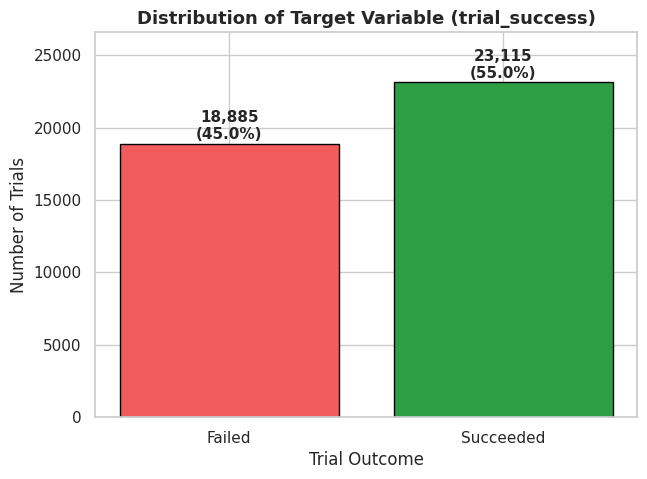

In [77]:
# create a copy of the data with readable labels to be used for plots
plot_df = df.copy()
plot_df["outcome"] = plot_df["trial_success"].map({0: "Failed", 1: "Succeeded"})
outcome_order = ["Failed", "Succeeded"]
outcome_colors = {"Failed": FAIL_COLOR, "Succeeded": SUCCESS_COLOR}

# count and percent for each class
counts = plot_df["outcome"].value_counts()[outcome_order]
percents = counts / counts.sum() * 100

# class balance of the target variable visual
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(counts.index, counts.values,
              color=[FAIL_COLOR, SUCCESS_COLOR], edgecolor="black")

# make the count and percent show on top of each bar
for bar, count, pct in zip(bars, counts.values, percents.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 300,
            f"{count:,}\n({pct:.1f}%)", ha="center", fontsize=11, fontweight="bold")

# set plot title and axes
ax.set_title("Distribution of Target Variable (trial_success)")
ax.set_xlabel("Trial Outcome")
ax.set_ylabel("Number of Trials")
ax.set_ylim(0, counts.max() * 1.15)   # leave room for the labels
plt.show()

### Results from Validation and Cleaning
*Results from Synthetic dataset, seed 973.*
- **Shape:** 42,000 rows × 17 columns (1 ID, 15 predictors, 1 target), 3 categorical, 6 numeric, 6 binary predictors.
- **Success rate:** 55.04% (23,115 succeeded, 18,885 failed) against the generator's 55% target. The classes are balanced enough that no rebalancing is needed.
- **All checks passed:** expected columns, binary target, unique IDs, no missing values or duplicates, levels and ranges match the data dictionary.
- **Cleaning log: "No changes needed."** The cleaning steps are implemented but not exercised on this clean synthetic file. They would act on a messier uploaded dataset.

### Compute Descriptive Statistics

In [78]:
# summary statistics for numeric predictors
df[numeric_cols].describe().round(2)

,phase2_effect_size,phase2_pvalue_strength,enrollment,statistical_power,prior_approvals_target,years_in_development
count,42000.00,42000.00,42000.00,42000.00,42000.00,42000.00
mean,5.00,6.90,582.18,0.82,1.20,7.00
std,1.96,2.00,403.07,0.10,1.09,2.49
min,0.08,0.35,45.00,0.45,0.00,1.10
25%,3.53,5.56,315.00,0.75,0.00,5.10
50%,5.01,7.21,481.00,0.83,1.00,6.80
75%,6.47,8.53,729.00,0.90,2.00,8.70
max,9.97,10.00,6897.00,0.99,8.00,15.70


In [79]:
# for binary predictors, the mean is the proportion of trials with a value of 1
df[binary_cols].mean().round(3).to_frame("calculated_mean")

,calculated_mean
uses_biomarker,0.416
novel_mechanism,0.420
randomized,0.881
double_blind,0.721
active_comparator,0.495
orphan_designation,0.179


In [80]:
# counts for each categorical predictor
for col in categorical_cols:
    print(df[col].value_counts())
    print()

therapeutic_area
oncology              10881
cns                    5049
infectious_disease     4204
cardiovascular         4139
rare_disease           3802
immunology             3756
metabolic              3696
vaccine                3459
respiratory            3014
Name: count, dtype: int64

endpoint_type
clinical         16721
surrogate        12826
hard_survival    12453
Name: count, dtype: int64

sponsor_type
small_biotech    14363
large_pharma     14108
mid_pharma        8614
academic          4915
Name: count, dtype: int64



In [81]:
### **Describe the data (and data type) for each variable**
cols = predictor_cols + [TARGET]
role = {**{c: "Categorical" for c in categorical_cols}, **{c: "Numeric" for c in numeric_cols},
        **{c: "Binary (0/1)" for c in binary_cols}, TARGET: "Target"}

summary = df[cols].describe(include="all").T.astype(object).fillna("NA")
summary.insert(0, "Role", [role[c] for c in summary.index])
summary.insert(0, "Variable",
    [f"<b>{c}</b><br><span style='font-weight:normal; font-size:smaller;'>[{df[c].dtype}]</span>"
     for c in summary.index])
summary.reset_index(drop=True, inplace=True)

(summary.style
        .format(precision=3, na_rep="NA")
        .set_table_styles([{"selector": "th", "props": [("font-weight", "bold"), ("text-align", "center")]},
                           {"selector": "td", "props": [("text-align", "center")]}])
        .hide(axis="index"))

Variable,Role,count,unique,top,freq,mean,std,min,25%,50%,75%,max
therapeutic_area[object],Categorical,42000.000,9,oncology,10881,NA,NA,NA,NA,NA,NA,NA
endpoint_type[object],Categorical,42000.000,3,clinical,16721,NA,NA,NA,NA,NA,NA,NA
sponsor_type[object],Categorical,42000.000,4,small_biotech,14363,NA,NA,NA,NA,NA,NA,NA
phase2_effect_size[float64],Numeric,42000.000,NA,NA,NA,5.002,1.959,0.080,3.530,5.010,6.470,9.970
phase2_pvalue_strength[float64],Numeric,42000.000,NA,NA,NA,6.900,1.999,0.350,5.560,7.210,8.530,10.000
enrollment[int64],Numeric,42000.000,NA,NA,NA,582.182,403.071,45.000,315.000,481.000,729.000,6897.000
statistical_power[float64],Numeric,42000.000,NA,NA,NA,0.819,0.100,0.448,0.753,0.833,0.898,0.994
prior_approvals_target[int64],Numeric,42000.000,NA,NA,NA,1.200,1.092,0.000,0.000,1.000,2.000,8.000
years_in_development[float64],Numeric,42000.000,NA,NA,NA,7.005,2.494,1.100,5.100,6.800,8.700,15.700
uses_biomarker[int64],Binary (0/1),42000.000,NA,NA,NA,0.416,0.493,0.000,0.000,0.000,1.000,1.000


### Description of Variables

All 15 predictors describe the trial **as designed, before Phase 3 begins**. None of them uses information from the Phase 3 trial itself, so the model can be used for go/no-go decisions without "peeking" at the outcome.

| Variable | Python dtype | Measurement level | Variable type | Values / range (observed) | Description | How it is used in the analysis |
|---|---|---|---|---|---|---|
| **`trial_id`** | `object` | Nominal (identifier) | Unique string | `SYN000000` … `SYN041999` | Trial identifier (no predictive information) | **Excluded** from any model |
| **`therapeutic_area`** | `object` | **Nominal** (unordered) | Categorical – 9 levels | `oncology`, `cardiovascular`, `cns`, `infectious_disease`, `rare_disease`, `immunology`, `metabolic`, `vaccine`, `respiratory` | Disease area of the programme | One‑hot encoded; reference level = **oncology**; association tested with chi‑square & Cramér’s V |
| **`endpoint_type`** | `object` | **Nominal** (unordered) | Categorical – 3 levels | `hard_survival`, `clinical`, `surrogate` | Primary‑endpoint type (hard_survival is the hardest to meet) | One‑hot encoded; reference = **hard_survival**; chi‑square & Cramér’s V |
| **`sponsor_type`** | `object` | **Nominal** (unordered) | Categorical – 4 levels | `large_pharma`, `mid_pharma`, `small_biotech`, `academic` | Organisation that runs the trial | One‑hot encoded; reference = **large_pharma**; chi‑square & Cramér’s V |
| **`phase2_effect_size`** | `float64` | **Interval** (bounded, zero is a scale floor) | Continuous – Beta‑distributed on [0, 9.97] (≈ 0‑10) | 0.08 – 9.97 (mean ≈ 5.00, SD ≈ 1.96) | Strength of the Phase 2 efficacy signal (higher = stronger) | Standardised (mean 0, SD 1); tested with Mann‑Whitney U & appears as a linear term in the logistic model |
| **`phase2_pvalue_strength`** | `float64` | **Interval** (bounded) | Continuous – Beta‑distributed on [0, 10] | 0.35 – 10.00 (mean ≈ 6.90, SD ≈ 2.00) | Strength of the Phase 2 statistical evidence (higher = stronger) – generated to correlate with `phase2_effect_size` (ρ ≈ 0.36) | Standardised; Mann‑Whitney U; linear term in the logistic model |
| **`enrollment`** | `int64` | **Ratio** (true zero, multiplicative) | Discrete count, heavily right‑skewed (log‑normal) | 45 – 6 897 (mean ≈ 582, SD ≈ 403) | Number of patients enrolled in the Phase 3 trial | Yeo‑Johnson transform → standardised for LR & SVM; used raw for tree‑based models |
| **`statistical_power`** | `float64` | **Ratio** (probability, bounded 0‑1) | Continuous – Beta‑distributed on [0.40, 0.995] | 0.45 – 0.99 (mean ≈ 0.82, SD ≈ 0.10) | Planned power to detect the target effect size (higher = more likely to detect a true effect) | Standardised; Mann‑Whitney U; linear term in the logistic model |
| **`prior_approvals_target`** | `int64` | **Ratio** (count of approvals) | Discrete count, right‑skewed (Poisson λ ≈ 1.2) | 0 – 8 (mean ≈ 1.20, SD ≈ 1.09) | Number of already‑approved drugs that act on the same molecular target | Standardised; Mann‑Whitney U; linear term in the logistic model |
| **`years_in_development`** | `float64` | **Ratio** (duration, true zero) | Continuous – Beta‑distributed on [1, 17] | 1.1 – 15.7 (mean ≈ 7.00, SD ≈ 2.49) | Years the programme has been in development before Phase 3 | Standardised; Mann‑Whitney U; linear term in the logistic model |
| **`uses_biomarker`** | `int64` | Nominal (dichotomous) | Binary indicator | 0 = no, 1 = yes (≈ 41.6 % = 1) | Trial uses a biomarker‑guided patient‑selection strategy | Kept as 0/1; entered as a binary covariate (OR ≈ 1.35); chi‑square & Cramér’s V |
| **`novel_mechanism`** | `int64` | Nominal (dichotomous) | Binary indicator | 0 = no, 1 = yes (≈ 42.0 % = 1) | First‑in‑class (novel) mechanism of action | Binary covariate (OR ≈ 0.81); chi‑square & Cramér’s V |
| **`randomized`** | `int64` | Nominal (dichotomous) | Binary indicator | 0 = no, 1 = yes (≈ 88.1 % = 1) | Patients randomly allocated to treatment arms | Binary covariate; chi‑square & Cramér’s V |
| **`double_blind`** | `int64` | Nominal (dichotomous) | Binary indicator | 0 = no, 1 = yes (≈ 72.1 % = 1) | Neither participants nor investigators know the assignment | Binary covariate; chi‑square & Cramér’s V |
| **`active_comparator`** | `int64` | Nominal (dichotomous) | Binary indicator | 0 = no, 1 = yes (≈ 49.5 % = 1) | Comparator is an active drug rather than placebo | Binary covariate; chi‑square & Cramér’s V |
| **`orphan_designation`** | `int64` | Nominal (dichotomous) | Binary indicator | 0 = no, 1 = yes (≈ 17.9 % = 1) | Trial has an FDA/EMA orphan‑drug designation (rare disease) | Binary covariate; chi‑square & Cramér’s V |
| **`trial_success`** | `int64` | **Nominal** (dichotomous) | **Binary target** | 0 = failed, 1 = succeeded (55 % = 1) | Whether the Phase 3 trial met its primary endpoint | Outcome variable to be predicted (logistic regression, SVM, tree‑based models, etc.) |

**Summary:** 15 predictors: 3 nominal categorical, 6 numeric (2 interval-scale scores and 4 ratio-scale measures, of which 2 are counts), and 6 binary indicators.

**Why the measurement level matters for the analysis**
- **Nominal variables** have no natural order, so they are one-hot encoded instead of coded 1, 2, 3, which would wrongly imply equal spacing. Their association with success is tested with chi-square and Cramér's V.
- **Interval and ratio variables** can be ranked and differenced, so they are compared between failed and successful trials with the Mann-Whitney U test, which does not require normality.
- **Only ratio variables support "times as much" statements.** "Twice the enrollment" is meaningful; "twice the Phase 2 effect-size score" is not, because that score's zero is arbitrary.
- **Capped variables** No variable is capped by design. Spearman's ρ is still reported because it is robust to skew.
- **Counts** (`prior_approvals_target`) take few distinct values, so the empirical-logit plot groups them by exact value instead of by decile.

In [82]:
# compare the average of each numeric predictor for failed vs. successful trials
df.groupby("trial_success")[numeric_cols].mean().round(2)

,phase2_effect_size,phase2_pvalue_strength,enrollment,statistical_power,prior_approvals_target,years_in_development
trial_success,,,,,,
0,4.59,6.56,573.47,0.81,1.14,7.00
1,5.34,7.18,589.30,0.83,1.25,7.01


###Interpretation of Descriptive Statistics

*Interpretation from Synthetic dataset, seed 973.*

*Numeric predictors*
- **phase2_effect_size** (mean 5.00, SD 1.96, median 5.01) is centred on the 0–10 scale and symmetric. The range is 0.08–9.97, so values do not pile up at 0 or 10.
- **phase2_pvalue_strength** (mean 6.90, SD 2.00) has a median (7.21) above its mean, so it is left-skewed. 75% of trials score 5.56 or higher. The maximum of 10.00 is the extreme upper tail rounded to two decimals, not a cap, and the 75th percentile is only 8.53.
- **enrollment** varies the most: 45 to 6,897 patients. The mean (582) is well above the median (481), which shows right skew. The minimum of 45 means the generator's floor of 40 was never reached.
- **statistical_power** (mean 0.82, SD 0.10) ranges from 0.45 to 0.99. Half of trials are designed at 0.83 or higher, and a quarter are below 0.75.
- **prior_approvals_target** is a small count (mean 1.20, median 1, max 8).
- **years_in_development** averages 7.0 years (SD 2.5, range 1.1–15.7). The floor at 1.0 was not reached.

*Binary predictors* (proportion of trials = 1)
- Randomized 88.1%, double-blind 72.1%, active comparator 49.5%.
- Biomarker use 41.6%, novel mechanism 42.0%, orphan designation 17.9%.

*Categorical predictors*
- Oncology is the largest therapeutic area (10,881 trials, 25.9%). The smallest, respiratory, still has 3,014 (7.2%).
- Endpoints: clinical 39.8%, surrogate 30.5%, hard_survival 29.7%.
- Sponsors: small biotech 34.2%, large pharma 33.6%, mid pharma 20.5%, academic 11.7%.

*Successful vs. failed trials (means)*
- The biggest differences are in Phase 2 effect size (5.34 vs. 4.59) and p-value strength (7.18 vs. 6.56).
- Successful trials also have slightly higher power (0.83 vs. 0.81) and more prior approvals on the target (1.25 vs. 1.14).
- Enrollment differs only slightly (589 vs. 573). Years in development shows no difference (7.01 vs. 7.00).

### Exploratory Visualizations

**Why this matters for sponsors:** before building any model, looking at how each characteristic is distributed and how its success rate varies is important. This step shows:
- which factors have large, visible differences in success rate (candidate drivers)
- which variables are skewed or capped and need special handling in the models
- whether any two predictors are closely related to each other. If they were, their individual effects would be hard to separate.

All success rates are **raw rates**. They do not adjust for other factors. Adjusted effects come from the logistic regression later in the notebook.

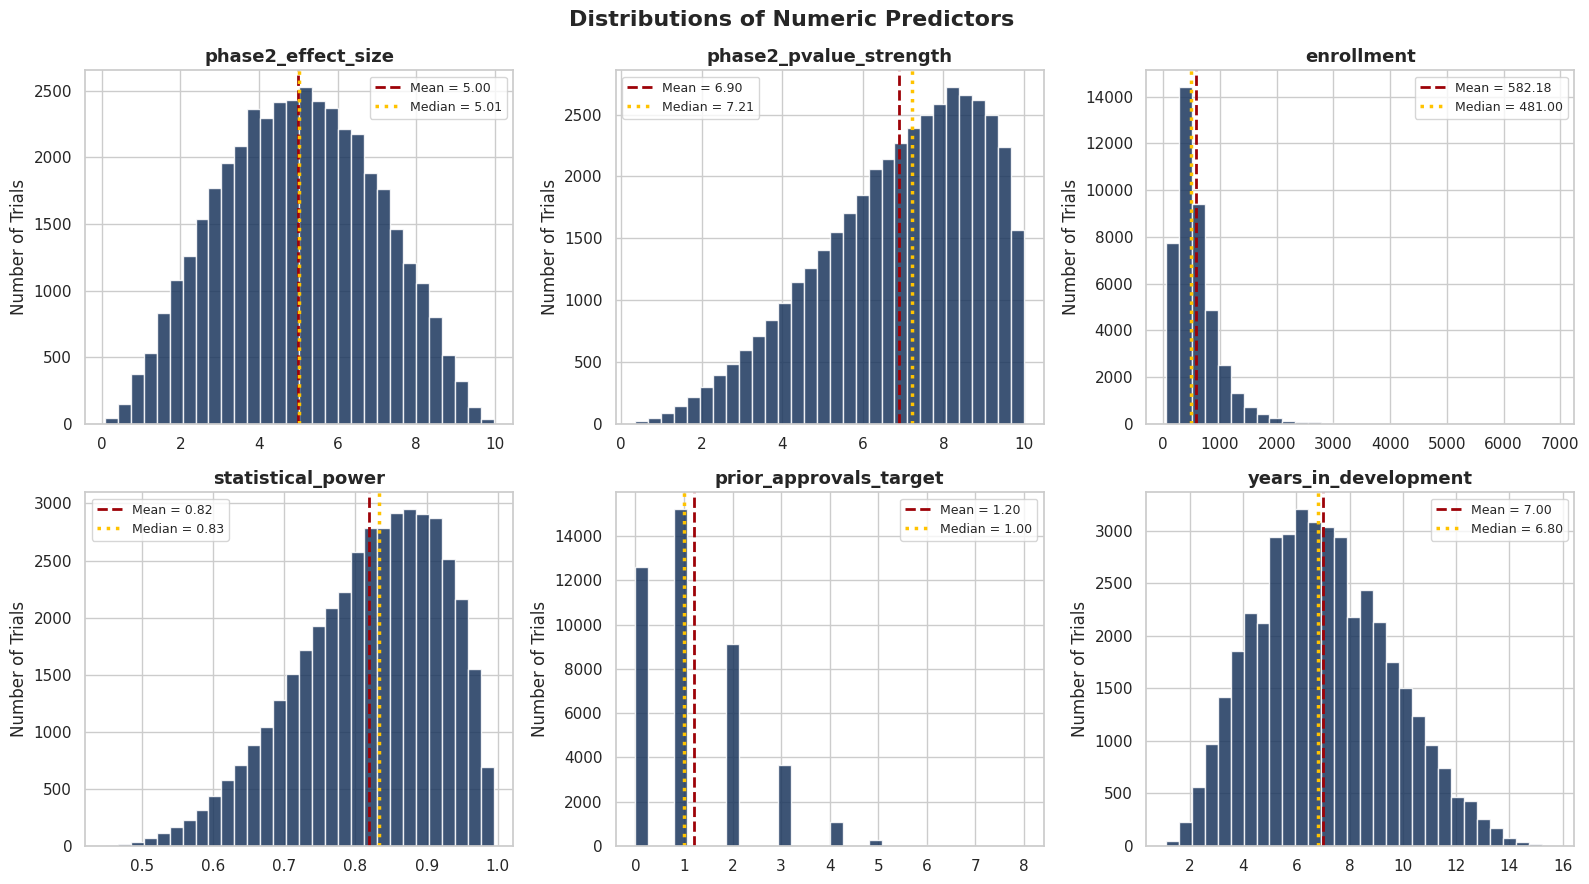

In [83]:
# histograms of the numeric predictors
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    ax = axes[i]
    ax.hist(df[col], bins=30, color=MAIN_COLOR, edgecolor="white", alpha=0.85)

    # add mean and median lines
    mean_value = df[col].mean()
    median_value = df[col].median()
    ax.axvline(mean_value, color=MEAN_COLOR, linestyle="--", linewidth=2,
               label=f"Mean = {mean_value:.2f}")
    ax.axvline(median_value, color=MEDIAN_COLOR, linestyle=":", linewidth=2.5,
               label=f"Median = {median_value:.2f}")

    ax.set_title(col)
    ax.set_ylabel("Number of Trials")
    ax.legend(fontsize=9)

plt.suptitle("Distributions of Numeric Predictors", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

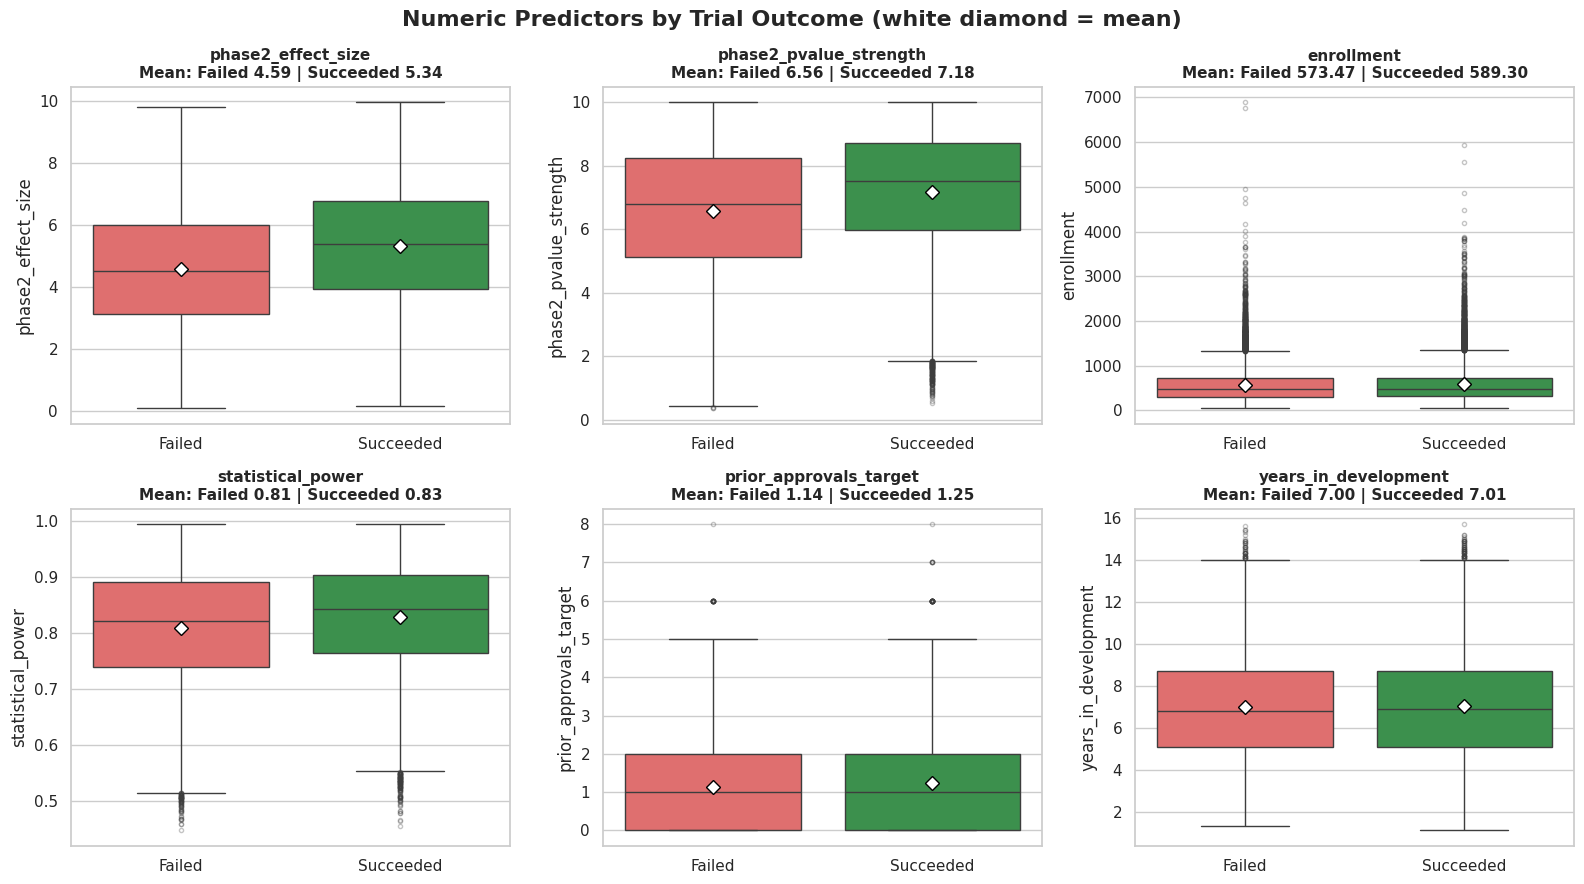

In [84]:
# boxplots of numeric predictors split by trial outcome
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(data=plot_df, x="outcome", y=col, hue="outcome",
                order=outcome_order, palette=outcome_colors, legend=False,
                showmeans=True,
                meanprops={"marker": "D", "markerfacecolor": "white",
                           "markeredgecolor": "black", "markersize": 7},
                flierprops={"marker": "o", "markersize": 3, "alpha": 0.3},
                ax=axes[i])

    # group means in the title
    mean_fail = df[df["trial_success"] == 0][col].mean()
    mean_success = df[df["trial_success"] == 1][col].mean()
    axes[i].set_title(f"{col}\nMean: Failed {mean_fail:.2f} | Succeeded {mean_success:.2f}",
                      fontsize=11)
    axes[i].set_xlabel("")

plt.suptitle("Numeric Predictors by Trial Outcome (white diamond = mean)",
             fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

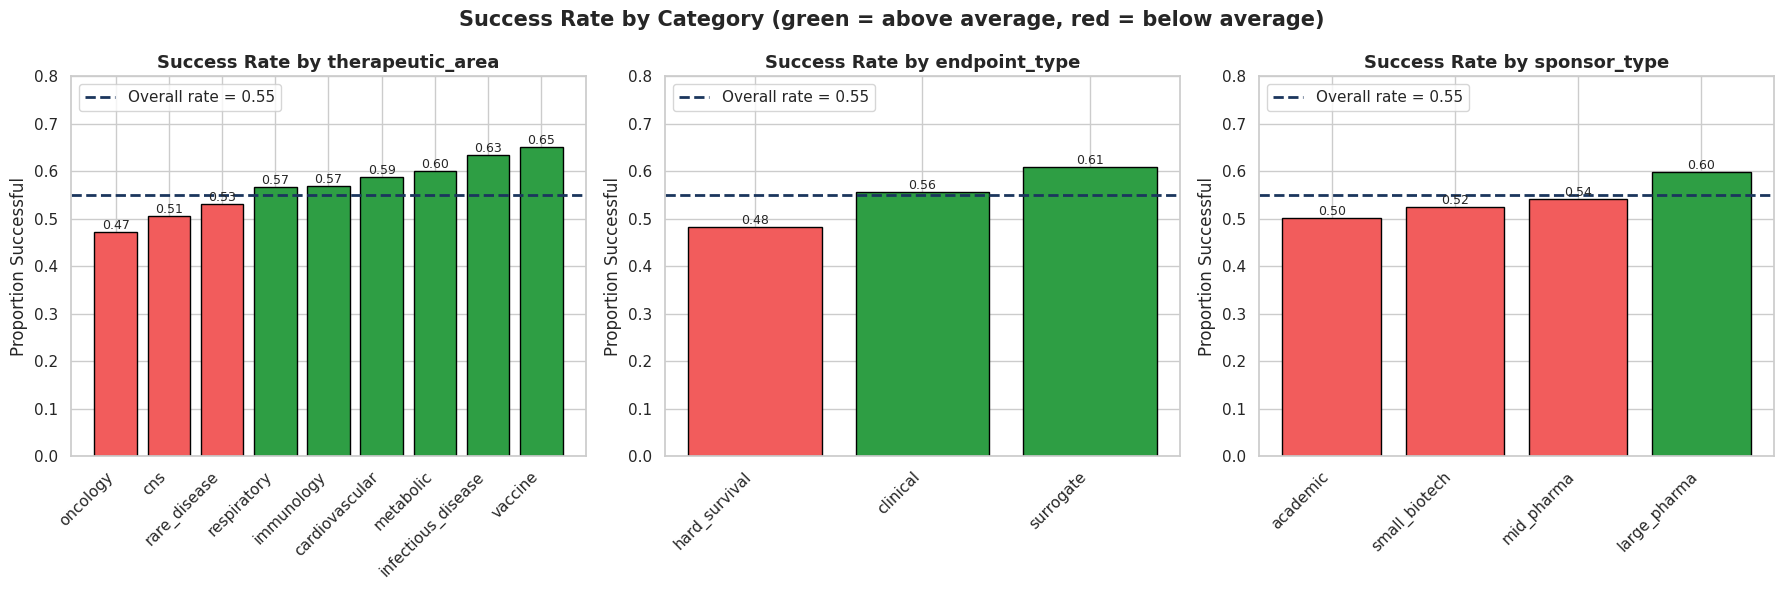

In [85]:
# overall success rate for reference line
overall_rate = df["trial_success"].mean()

# visual for success rate for each category
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, col in enumerate(categorical_cols):
    ax = axes[i]
    success_rate = df.groupby(col)["trial_success"].mean().sort_values()

    # color for success if above the overall rate
    # color for failure if below the overall rate
    bar_colors = []
    for rate in success_rate:
        if rate >= overall_rate:
            bar_colors.append(SUCCESS_COLOR)
        else:
            bar_colors.append(FAIL_COLOR)

    bars = ax.bar(success_rate.index, success_rate.values,
                  color=bar_colors, edgecolor="black")
    ax.bar_label(bars, fmt="%.2f", fontsize=9)    # value on top of each bar

    ax.axhline(overall_rate, color=MAIN_COLOR, linestyle="--", linewidth=2,
               label=f"Overall rate = {overall_rate:.2f}")

    ax.set_title("Success Rate by " + col)
    ax.set_ylabel("Proportion Successful")
    ax.set_ylim(0, 0.8)
    ax.legend(loc="upper left")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

plt.suptitle("Success Rate by Category (green = above average, red = below average)",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

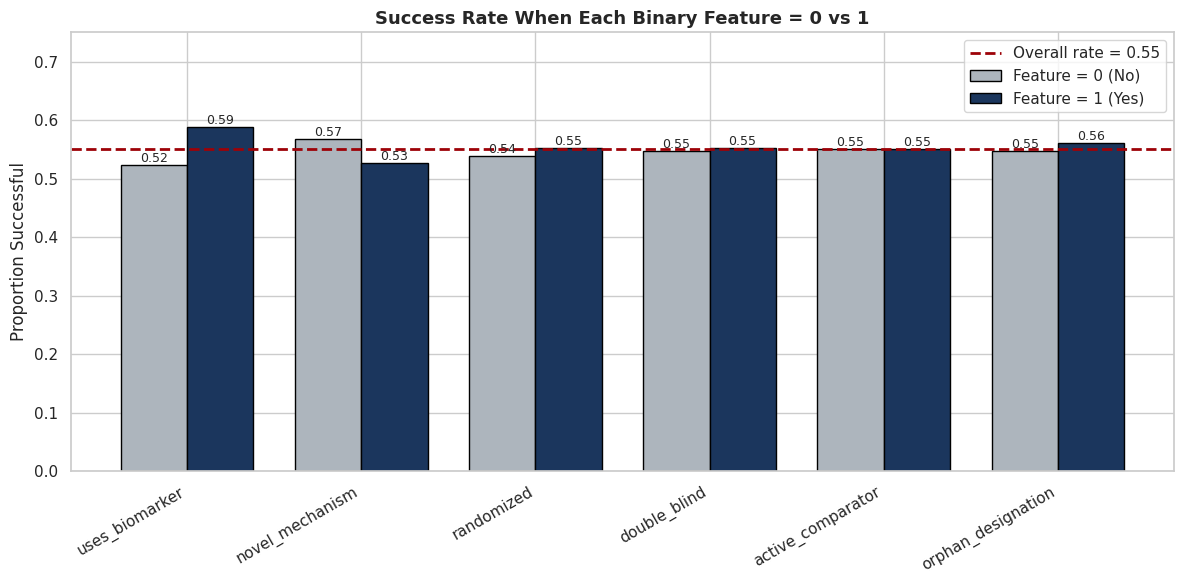

In [86]:
# success rate when each binary feature is 0 vs 1
rate_when_0 = []
rate_when_1 = []
for col in binary_cols:
    rates = df.groupby(col)["trial_success"].mean()
    rate_when_0.append(rates[0])
    rate_when_1.append(rates[1])

overall_rate = df["trial_success"].mean()

# visual for side-by-side bars
x = np.arange(len(binary_cols))   # one position per feature
width = 0.38

fig, ax = plt.subplots(figsize=(12, 6))
bars0 = ax.bar(x - width / 2, rate_when_0, width, label="Feature = 0 (No)",
               color="#ADB5BD", edgecolor="black")
bars1 = ax.bar(x + width / 2, rate_when_1, width, label="Feature = 1 (Yes)",
               color=MAIN_COLOR, edgecolor="black")
ax.bar_label(bars0, fmt="%.2f", fontsize=9)
ax.bar_label(bars1, fmt="%.2f", fontsize=9)

ax.axhline(overall_rate, color=MEAN_COLOR, linestyle="--", linewidth=2,
           label=f"Overall rate = {overall_rate:.2f}")

ax.set_xticks(x)
ax.set_xticklabels(binary_cols, rotation=30, ha="right")
ax.set_ylim(0, 0.75)
ax.set_ylabel("Proportion Successful")
ax.set_title("Success Rate When Each Binary Feature = 0 vs 1")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [87]:
# exact success rates for each category
# supporting data for visuals
for col in categorical_cols + binary_cols:
    print("----", col, "----")
    print(df.groupby(col)["trial_success"].mean().round(3))
    print()

---- therapeutic_area ----
therapeutic_area
cardiovascular        0.587
cns                   0.505
immunology            0.568
infectious_disease    0.634
metabolic             0.600
oncology              0.472
rare_disease          0.531
respiratory           0.568
vaccine               0.651
Name: trial_success, dtype: float64

---- endpoint_type ----
endpoint_type
clinical         0.557
hard_survival    0.482
surrogate        0.608
Name: trial_success, dtype: float64

---- sponsor_type ----
sponsor_type
academic         0.502
large_pharma     0.599
mid_pharma       0.542
small_biotech    0.524
Name: trial_success, dtype: float64

---- uses_biomarker ----
uses_biomarker
0    0.523
1    0.589
Name: trial_success, dtype: float64

---- novel_mechanism ----
novel_mechanism
0    0.568
1    0.526
Name: trial_success, dtype: float64

---- randomized ----
randomized
0    0.538
1    0.552
Name: trial_success, dtype: float64

---- double_blind ----
double_blind
0    0.547
1    0.552
Name: tri

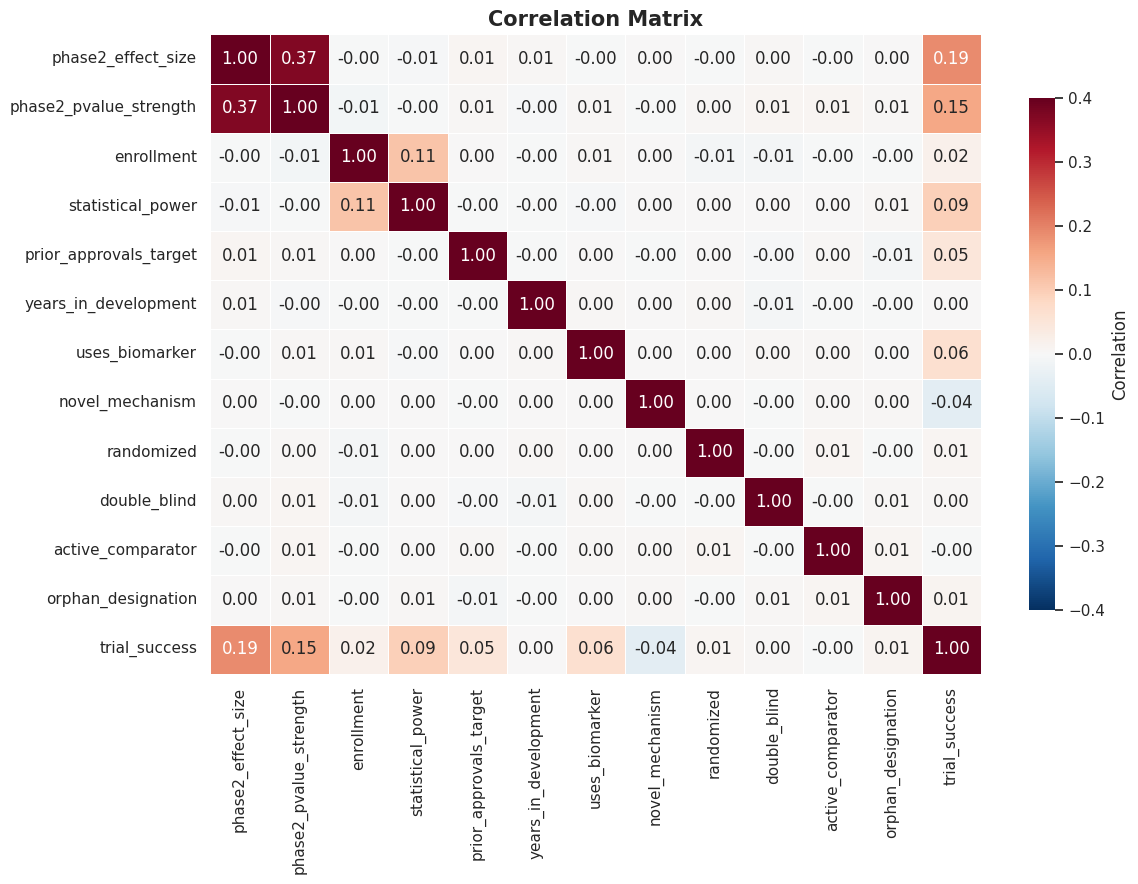

In [88]:
# correlation heatmap
corr = df[numeric_cols + binary_cols + ["trial_success"]].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-0.4, vmax=0.4,
            linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Correlation", "shrink": 0.8})
plt.title("Correlation Matrix", fontsize=15)
plt.tight_layout()
plt.show()

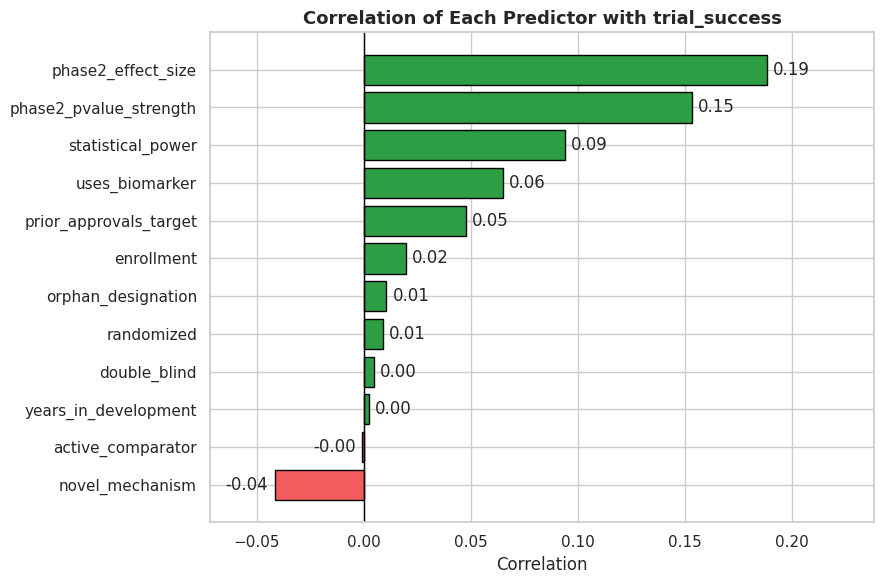

In [89]:
# how strongly is each predictor correlated with trial_success?
target_corr = corr["trial_success"].drop("trial_success").sort_values()

# success color indicates a positive relationship
# failure color indicates a negative relationship
bar_colors = []
for value in target_corr:
    if value > 0:
        bar_colors.append(SUCCESS_COLOR)
    else:
        bar_colors.append(FAIL_COLOR)

plt.figure(figsize=(9, 6))
plt.barh(target_corr.index, target_corr.values, color=bar_colors, edgecolor="black")
plt.axvline(0, color="black", linewidth=1)

# values will display next to each bar
for i, value in enumerate(target_corr.values):
    if value >= 0:
        plt.text(value + 0.003, i, f"{value:.2f}", va="center", ha="left")
    else:
        plt.text(value - 0.003, i, f"{value:.2f}", va="center", ha="right")

plt.title("Correlation of Each Predictor with trial_success")
plt.xlabel("Correlation")
plt.xlim(target_corr.min()-0.03, target_corr.max()+0.05)
plt.tight_layout()
plt.show()

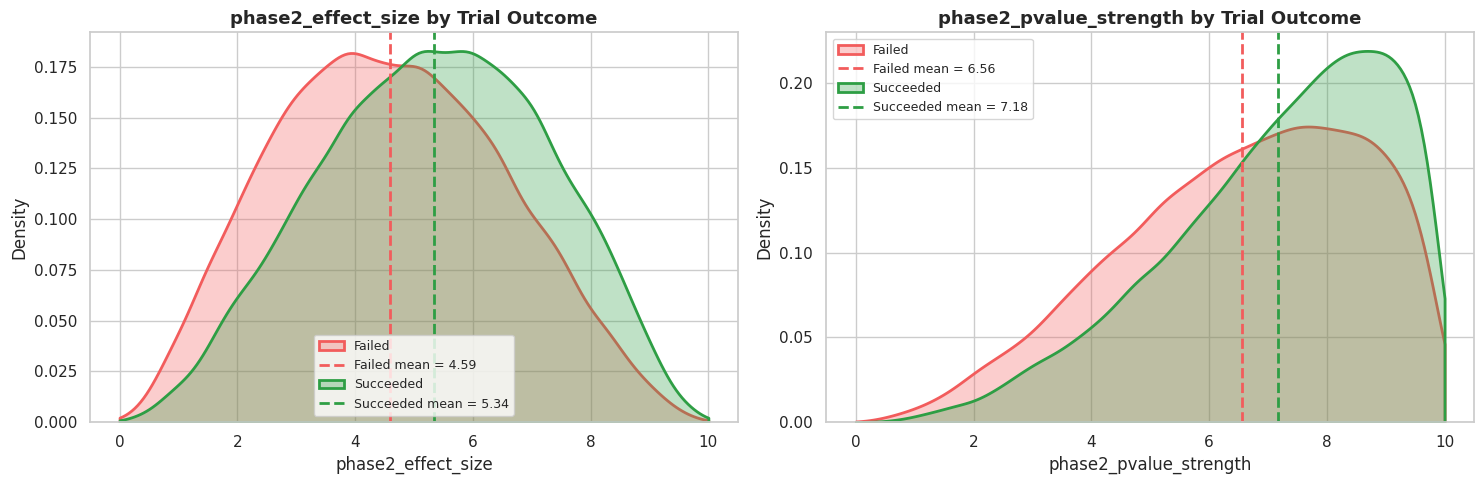

In [90]:
# visual to compare failed vs. successful trials for the top 2 predictors
top_predictors = ["phase2_effect_size", "phase2_pvalue_strength"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for i, col in enumerate(top_predictors):
    ax = axes[i]
    for outcome in outcome_order:
        values = plot_df[plot_df["outcome"] == outcome][col]
        sns.kdeplot(values, ax=ax, color=outcome_colors[outcome], fill=True,
                    alpha=0.3, linewidth=2, clip=(0, 10), label=outcome)
        ax.axvline(values.mean(), color=outcome_colors[outcome], linestyle="--",
                   linewidth=2, label=f"{outcome} mean = {values.mean():.2f}")

    ax.set_title(col + " by Trial Outcome")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

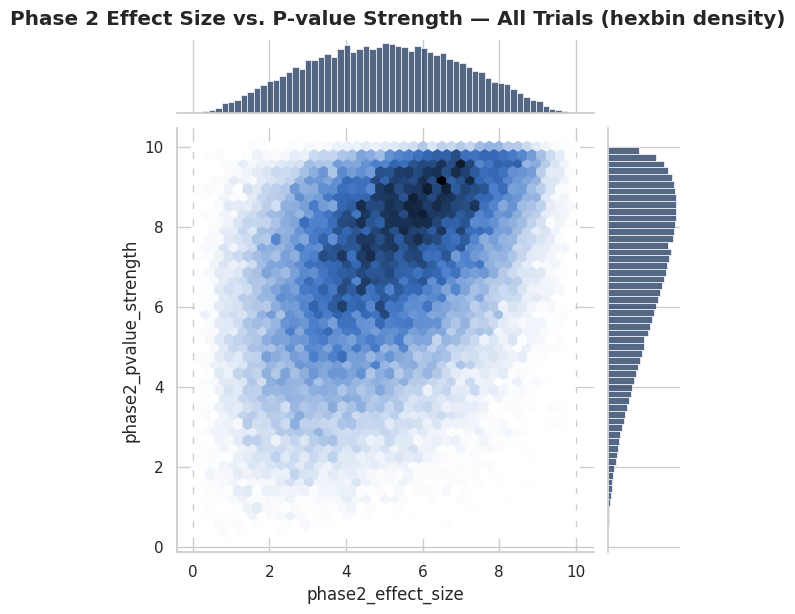

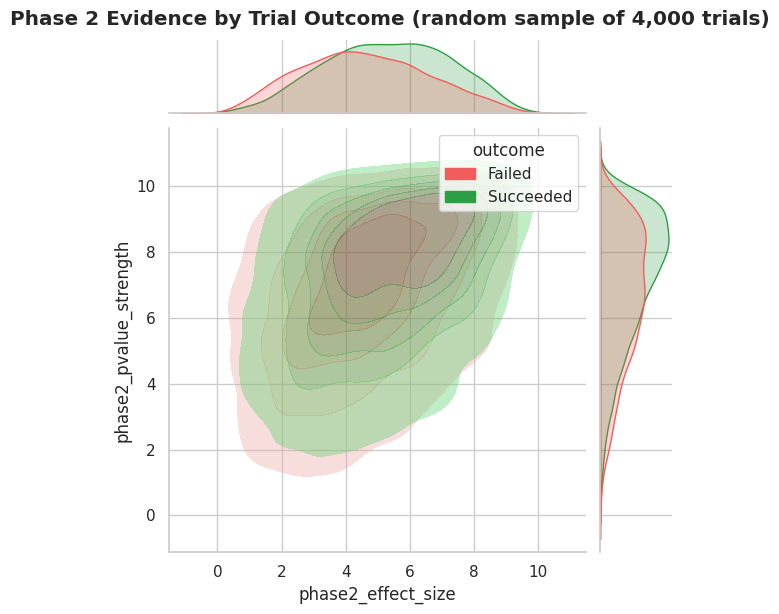

In [91]:
# Joint plots — Phase 2 effect size vs. p-value strength

# Hexbin: density of all 42,000 trials (overplotting-free)
g = sns.jointplot(data=df, x="phase2_effect_size", y="phase2_pvalue_strength",
                  kind="hex", gridsize=40, color=MAIN_COLOR, height=6)
g.fig.suptitle("Phase 2 Effect Size vs. P-value Strength — All Trials (hexbin density)",
               fontweight="bold", y=1.02)
plt.show()

# KDE by outcome: how much do successful and failed trials overlap?
kde_sample = plot_df.sample(n=4000, random_state=42)     # KDE is slow on 42k rows
g = sns.jointplot(data=kde_sample, x="phase2_effect_size", y="phase2_pvalue_strength",
                  hue="outcome", hue_order=outcome_order, palette=outcome_colors,
                  kind="kde", fill=True, alpha=0.4, levels=6, height=6)
g.fig.suptitle("Phase 2 Evidence by Trial Outcome (random sample of 4,000 trials)",
               fontweight="bold", y=1.02)
plt.show()

### Exploratory Visualization Key Points

*Interpretation of Synthetic dataset, seed 973.*

**Target distribution:** 55.0% succeeded and 45.0% failed. No rebalancing is needed. A model must beat the 55.0% baseline of always guessing "success".

**Histograms:**
- **phase2_effect_size** is bell-shaped with no spikes at 0 or 10.
- **phase2_pvalue_strength** is left-skewed and tapers toward 10 without a pile-up.
- **enrollment** is strongly right-skewed (mean 582 vs. median 481), with a long tail past 6,000.
- **statistical_power** is left-skewed within 0.45–0.99 with no spike at the top.
- **prior_approvals_target** is a right-skewed count. Most trials have 0–2.
- **years_in_development** is roughly bell-shaped with no pile-up at 1 year.
- *Any spike at a scale limit would mean the file is not generator output.*

**Boxplots by outcome:** successful trials have higher medians for **phase2_effect_size** (5.38 vs. 4.52), **phase2_pvalue_strength** (7.52 vs. 6.79) and **statistical_power** (0.843 vs. 0.821). **Enrollment**, **prior_approvals_target** and **years_in_development** look almost identical in the two groups. The classes overlap heavily on every variable, so no single feature separates them.

**Success rate by category:**
- *Therapeutic area:* oncology 47.2% (lowest) → CNS 50.5% → rare disease 53.1% → immunology and respiratory 56.8% → cardiovascular 58.7% → metabolic 60.0% → infectious disease 63.4% → vaccine 65.1% (highest). This is the planted order. Immunology and respiratory tie because their planted effects are nearly equal.
- *Endpoint type:* hard_survival 48.2% < clinical 55.7% < surrogate 60.8%.
- *Sponsor type:* academic 50.2% < small biotech 52.4% < mid pharma 54.2% < large pharma 59.9%.
- Below the 55.0% line: oncology, CNS, rare disease, hard-survival endpoints, academic, small biotech and mid pharma sponsors.

**Success rate for binary features (0 → 1):**
- **uses_biomarker** gives the biggest increase: 52.3% → 58.9% (+6.6 points).
- **novel_mechanism** lowers success: 56.8% → 52.6% (−4.2 points).
- **randomized** (53.8% → 55.2%), **orphan_designation** (54.8% → 56.2%), **double_blind** (54.7% → 55.2%) and **active_comparator** (55.1% → 55.0%) change success by 1.4 points or less.

**Correlations with the target** (point-biserial; for 2×2 tables this equals the phi coefficient, so it is derived from Cramér's V and the rates above): biomarker +0.065, novel mechanism −0.042, orphan +0.010, randomized +0.009, double-blind +0.005, active comparator −0.001. Approximate values from the group means: phase2_effect_size ≈ +0.19 and phase2_pvalue_strength ≈ +0.15. All are weak. The effect size ↔ p-value strength correlation is 0.37 and other predictor pairs are near 0. This is by construction: the generator draws predictors independently, apart from the Phase 2 pair and enrollment/power. "No multicollinearity concern" is therefore a property of the synthetic file. Real portfolios have strong dependencies (e.g., oncology ↔ hard-survival endpoints).

**Density, hexbin and KDE plots:** the successful-trial curves sit to the right of the failed-trial curves for both Phase 2 measures but overlap heavily. Strong Phase 2 evidence shifts the odds of success without guaranteeing it, so a model must combine several features.

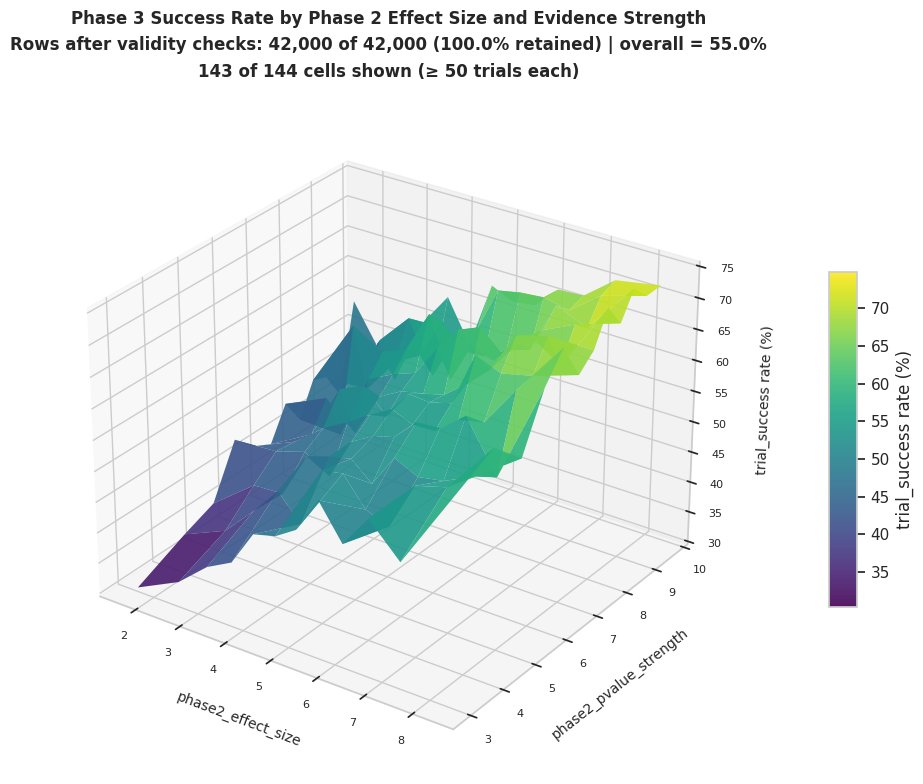

Highest: 74.8 at phase2_effect_size≈8.35, phase2_pvalue_strength≈8.74
Lowest:  30.4 at phase2_effect_size≈1.67, phase2_pvalue_strength≈2.96



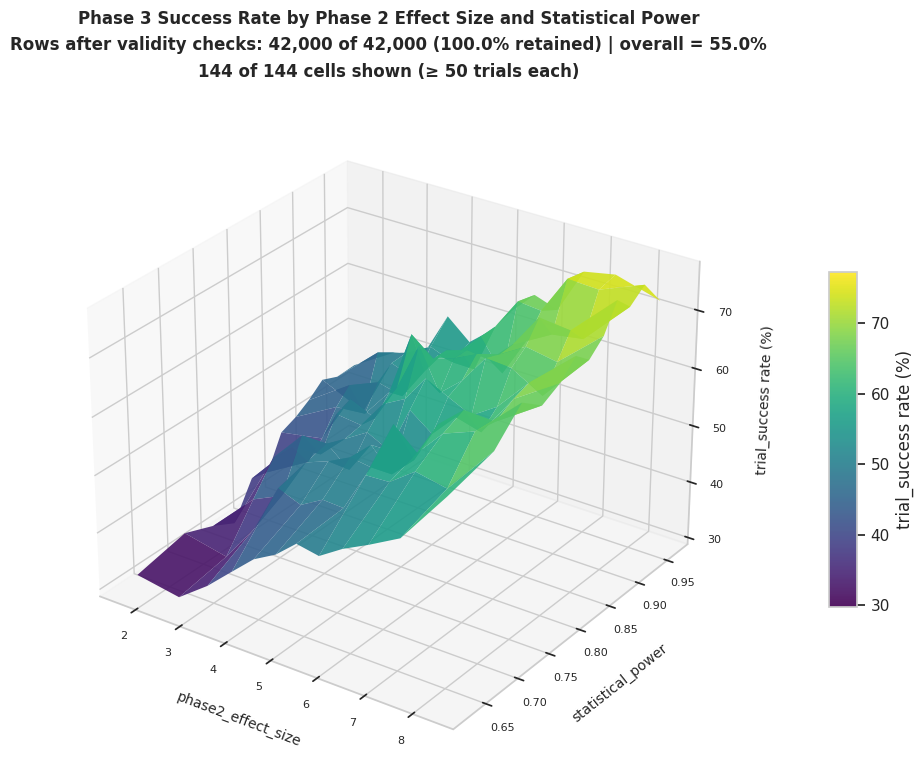

Highest: 77.3 at phase2_effect_size≈8.35, statistical_power≈0.888
Lowest:  29.8 at phase2_effect_size≈1.67, statistical_power≈0.769



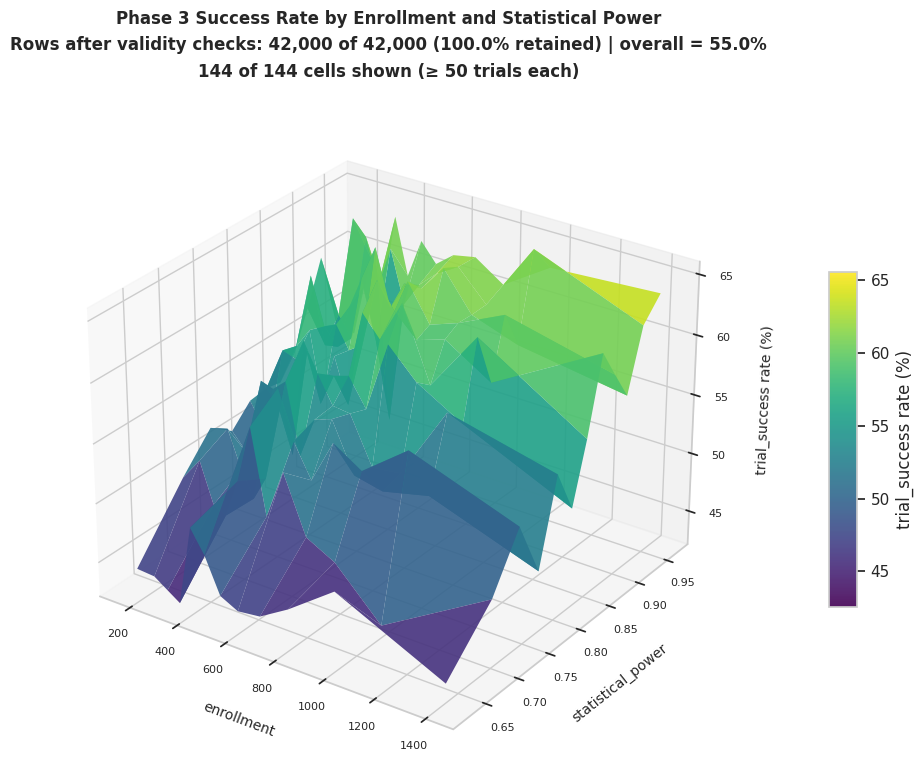

Highest: 65.6 at enrollment≈980, statistical_power≈0.934
Lowest:  42.6 at enrollment≈341, statistical_power≈0.625


In [92]:
# ══════════════════════════════════════════════════════════════════
# 3D SURFACE PLOTS — OBSERVED TRIAL SUCCESS RATE
# ══════════════════════════════════════════════════════════════════
# The target is binary (0 = failed, 1 = succeeded), so interpolating raw rows
# would produce spikes between 0 and 1. Instead, each predictor is cut into
# quantile bins, and the surface height is the observed success rate (%) in
# each (x-bin, y-bin) cell. Cells with fewer than `min_count` trials are left
# blank so that sparse corners don't produce noisy peaks.
#
# Note: these are RAW (marginal) rates. Other variables are not held constant,
# so a pattern here may partly reflect confounding.
# ══════════════════════════════════════════════════════════════════
from mpl_toolkits.mplot3d import Axes3D   # registers the 3D projection (older matplotlib)

# Range / validity checks for this dataset (no missing values, no 0-codes).
VALIDITY_RULES = {
    "enrollment":             lambda s: s > 0,
    "statistical_power":      lambda s: s.between(0, 1, inclusive="right"),
    "phase2_pvalue_strength": lambda s: s >= 0,
    "prior_approvals_target": lambda s: s >= 0,
    "years_in_development":   lambda s: s >= 0,
}

def apply_validity_filters(data):
    mask = pd.Series(True, index=data.index)
    for col, rule in VALIDITY_RULES.items():
        if col in data.columns:
            mask &= rule(data[col])
    return data[mask].copy()


def _draw_surface(fig, ax, XX, YY, ZZ, x_col, y_col, z_label, title,
                  cmap="viridis", elev=28, azim=-55, vmin=None, vmax=None):
    """Shared 3D drawing helper (used by the empirical and model surfaces)."""
    vmin = np.nanmin(ZZ) if vmin is None else vmin
    vmax = np.nanmax(ZZ) if vmax is None else vmax
    surf = ax.plot_surface(XX, YY, ZZ, cmap=cmap, vmin=vmin, vmax=vmax,
                           edgecolor="none", alpha=0.9)
    fig.colorbar(surf, ax=ax, shrink=0.5, aspect=12, pad=0.1, label=z_label)
    ax.set_title(title, fontsize=12, fontweight="bold", pad=20, linespacing=1.6)
    ax.set_xlabel(x_col, fontsize=10, labelpad=10)
    ax.set_ylabel(y_col, fontsize=10, labelpad=10)
    ax.set_zlabel(z_label, fontsize=10, labelpad=10)
    for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
        axis.set_tick_params(labelsize=8)
    ax.view_init(elev=elev, azim=azim)


def surface_plot_3d(data, x_col, y_col, z_col=TARGET, bins=12, binning="quantile",
                    min_count=50, title=None, cmap="viridis", elev=28, azim=-55):
    """
    3D surface of the mean of `z_col` over binned `x_col` × `y_col`.

    Parameters
    ----------
    data      : DataFrame (e.g., df)
    x_col     : str — numeric variable on the x-axis
    y_col     : str — numeric variable on the y-axis
    z_col     : str — variable averaged per cell (default: trial_success → % success)
    bins      : int — number of bins per axis
    binning   : 'quantile' (equal counts; good for skewed vars like enrollment)
                or 'uniform' (equal widths)
    min_count : int — minimum trials per cell; sparser cells are left blank
    title     : str — plot title (optional)
    cmap      : str — colormap

    Returns
    -------
    DataFrame of cell means (rows = x bins, columns = y bins)
    """
    df_clean = apply_validity_filters(data)

    def cut(s):
        return (pd.qcut(s, q=bins, duplicates="drop") if binning == "quantile"
                else pd.cut(s, bins=bins))

    x_bin, y_bin = cut(df_clean[x_col]), cut(df_clean[y_col])

    # Plot each bin at the MEDIAN of its actual values (not the interval midpoint)
    x_mid = df_clean[x_col].groupby(x_bin, observed=False).median().dropna()
    y_mid = df_clean[y_col].groupby(y_bin, observed=False).median().dropna()

    cell = df_clean.groupby([x_bin, y_bin], observed=False)[z_col].agg(["mean", "count"])
    Z = cell["mean"].unstack().reindex(index=x_mid.index, columns=y_mid.index)
    N = cell["count"].unstack().reindex(index=x_mid.index, columns=y_mid.index)
    Z = Z.where(N >= min_count)                  # hide sparse cells

    is_binary = set(df_clean[z_col].dropna().unique()) <= {0, 1}
    scale   = 100 if is_binary else 1
    z_label = f"{z_col} rate (%)" if is_binary else f"mean {z_col}"

    XX, YY = np.meshgrid(x_mid.values, y_mid.values, indexing="ij")
    ZZ = Z.values.astype(float) * scale

    overall = df_clean[z_col].mean() * scale
    n_shown = int(np.isfinite(ZZ).sum())
    full_title = (
        f"{title or f'{z_label} by {x_col} and {y_col}'}\n"
        f"Rows after validity checks: {len(df_clean):,} of {len(data):,} "
        f"({len(df_clean) / len(data) * 100:.1f}% retained) | "
        f"overall = {overall:.1f}{'%' if is_binary else ''}\n"
        f"{n_shown} of {ZZ.size} cells shown (≥ {min_count} trials each)"
    )

    fig = plt.figure(figsize=(11, 8))
    ax  = fig.add_subplot(111, projection="3d")
    _draw_surface(fig, ax, XX, YY, ZZ, x_col, y_col, z_label, full_title,
                  cmap=cmap, elev=elev, azim=azim)
    plt.tight_layout()
    plt.show()

    # Quick text summary of the extremes
    if n_shown:
        i_max = np.unravel_index(np.nanargmax(ZZ), ZZ.shape)
        i_min = np.unravel_index(np.nanargmin(ZZ), ZZ.shape)
        print(f"Highest: {ZZ[i_max]:.1f} at {x_col}≈{XX[i_max]:.3g}, {y_col}≈{YY[i_max]:.3g}")
        print(f"Lowest:  {ZZ[i_min]:.1f} at {x_col}≈{XX[i_min]:.3g}, {y_col}≈{YY[i_min]:.3g}")

    return Z * scale


# ── Plot 1: Phase 2 effect size × Phase 2 p-value strength → P(success) ──
surface_plot_3d(
    df,
    x_col="phase2_effect_size",
    y_col="phase2_pvalue_strength",
    title="Phase 3 Success Rate by Phase 2 Effect Size and Evidence Strength"
)
print()
# ── Plot 2: Phase 2 effect size × Statistical power → P(success) ─────────
surface_plot_3d(
    df,
    x_col="phase2_effect_size",
    y_col="statistical_power",
    title="Phase 3 Success Rate by Phase 2 Effect Size and Statistical Power"
)
print()
# ── Plot 3: Enrollment × Statistical power → P(success) ──────────────────
# Quantile bins handle enrollment's right skew.
surface_plot_3d(
    df,
    x_col="enrollment",
    y_col="statistical_power",
    title="Phase 3 Success Rate by Enrollment and Statistical Power"
);

### Interpretation of Surface Plots
*Interpretation from Synthetic dataset, seed 973.*

**Overall:** 55% of trials succeed. The generator is additive on the log-odds scale, with no interaction terms. The surfaces should therefore be smooth tilted ramps, and any ridges or twists are noise.

**1. Effect size × p-value strength:** success rises from **30.4%** (effect ≈ 1.7, p-value strength ≈ 3.0) to **74.8%** (effect ≈ 8.4, strength ≈ 8.7). Both variables push success upward.

**2. Effect size × statistical power:** range **29.8% → 77.3%**, the widest of the three. The peak is at power ≈ 0.89 rather than the highest-power bin, so it is probably noise. Most of the climb comes from effect size, with power adding a smaller lift.

**3. Enrollment × statistical power:** the narrowest range, **42.6% → 65.6%**. The lowest cell is at low power and modest enrollment (≈ 341, 0.63). The highest is at high power and high enrollment (≈ 980, 0.93). Enrollment and power are correlated by construction, since the generator builds log-enrollment partly from power. The two corners therefore cannot separate their effects. The planted enrollment effect is tiny, so most of this slope is power.

**Caveats**
- **Edges are noisy.** Each cell holds about 290 trials, so its rate can wobble by roughly ±6 points (95%) by chance. Picking the highest and lowest of ~144 cells also exaggerates the range. Read the overall slope.
- **These are raw rates.** Other variables are not held constant.
- **This supports the simpler model.** Smooth additive patterns are what logistic regression handles well. The later results confirm that logistic regression ties the more flexible models.

## Analytical Pipeline

## Inferential Statistics

**Purpose:** the charts above show differences between successful and failed trials. This section tests whether those differences are larger than chance would produce and measures how large they are.

**How to read the results:**
- **p-value:** how likely a difference this big would be if no real difference existed. With 42,000 trials, even trivial differences produce tiny p-values, so a small p-value alone is **not** evidence that a factor matters.
- **Effect size** (rank-biserial r, Cramér's V): how *big* the difference is. Rough guide: < 0.1 negligible, 0.1–0.3 small, 0.3–0.5 medium, > 0.5 large. **For decisions, the effect size is the number to watch.**

| Test | Used for | Question |
|---|---|---|
| Linearity checks | Pairs of numeric variables; each numeric variable vs. log-odds of success | Is a straight-line model appropriate? |
| Levene's test | Numeric variables by outcome | Do failed and successful trials vary by the same amount? |
| Mann-Whitney U | Numeric variables by outcome | Do successful trials tend to have higher values? |
| Chi-square | Categorical and yes/no variables by outcome | Does the success rate differ across categories? |

In [93]:
# =============================================================================
# INFERENTIAL STATISTICS LIBRARIES
# =============================================================================

# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import AnovaRM
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import warnings
warnings.filterwarnings("ignore")

### Phi-K (φK) Correlation Coefficient

**Phi-K correlation (φK)** is a general-purpose correlation coefficient developed by
**Baharad et al. (2018, CERN)** that measures the association between **any combination
of variable types** — numeric, categorical, or ordinal — in a unified framework. Like
Pearson's and Spearman's, it ranges from **0 to 1**, where:

- **φK = 1** — Perfect association between the two variables
- **φK = 0** — No association between the two variables

> Note: Unlike Pearson's and Spearman's, Phi-K is **always non-negative** — it measures
> the strength of association but does not indicate direction.

### How It Works

Phi-K works by:

1. **Binning** continuous variables into intervals (discretization)
2. Constructing a **contingency table** for each variable pair
3. Computing a **chi-squared statistic** on that contingency table
4. **Normalizing** the result to a [0, 1] scale, correcting for the number of bins and
   sample size

### Key Assumptions

1. Works with **any variable type** — numeric, ordinal, or categorical (nominal)
2. Detects **non-linear and non-monotonic** associations that Pearson's and Spearman's miss
3. Observations are **independent** of one another
4. Sufficient **sample size** per bin is recommended for stable estimates

### Pearson's vs. Spearman's vs. Phi-K — When to Use Each

| Condition | Use |
|---|---|
| Continuous data, linear relationship, no outliers | Pearson's (r) |
| Ordinal data, non-normal, or outliers present | Spearman's (ρ) |
| Mixed variable types (numeric + categorical) | Phi-K (φK) |
| Non-linear or non-monotonic relationships | Phi-K (φK) |
| Categorical vs. categorical association | Phi-K (φK) |
| Unified correlation matrix across all feature types | Phi-K (φK) |

### Important Notes
- Because it uses **binning and chi-squared statistics**, results can be sensitive to the
  number of bins chosen for continuous variables — inspect results carefully.
- Phi-K does **not indicate direction** of association. A high φK tells you two variables
  are strongly associated but not whether that relationship is positive or negative; direction comes from the success-rate charts and odds ratios.
- Phi-K is particularly valuable in **clinical and biomedical research** where datasets
  routinely mix continuous measurements, ordinal scales, and categorical variables
  (e.g., diagnosis, sex, treatment group).

  
###Why Phi-K is used in this notebook:
- Pearson correlation only works for numeric variables, so it misses therapeutic area, endpoint type, and sponsor type.
- Phi-K measures association between any mix of categorical, binary, and numeric variables on a 0–1 scale, and it also picks up non-linear relationships.

### Phi-K correlation heatmap (works for categorical, binary and numeric together)

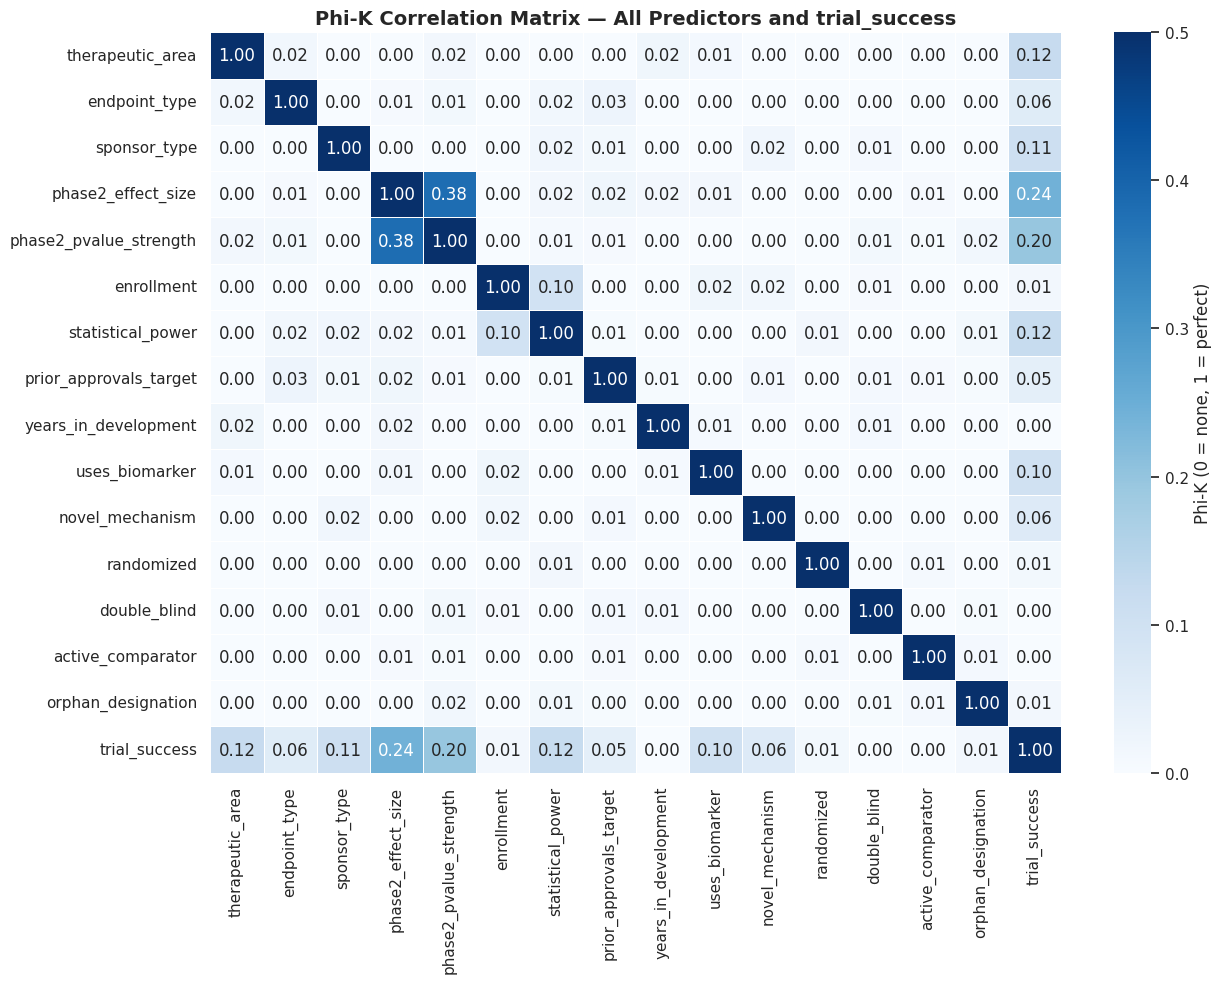

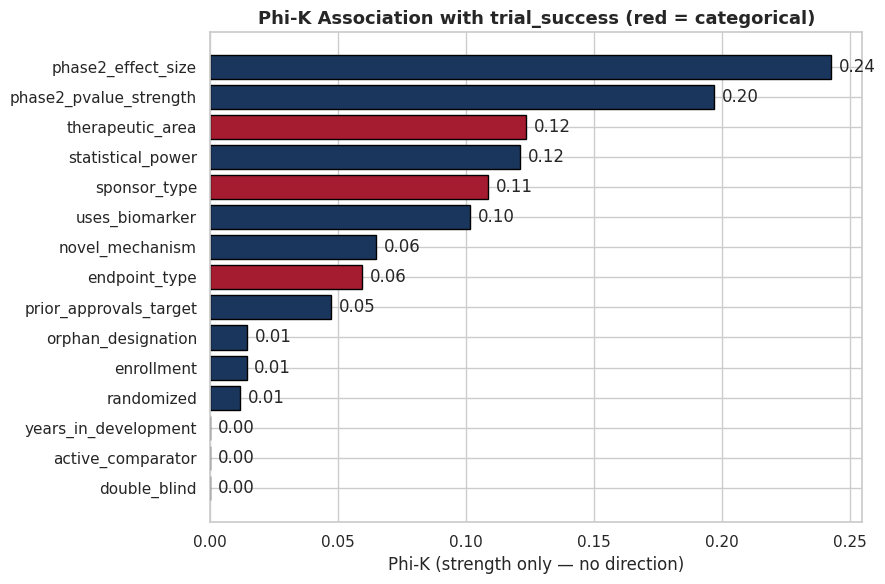

In [94]:

import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "phik"],
               stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
import phik   # registers DataFrame.phik_matrix()

phik_corr = df[predictor_cols + [TARGET]].phik_matrix(interval_cols=numeric_cols)
# (If this is slow, use df.sample(20000, random_state=42) instead of df.)

plt.figure(figsize=(13, 10))
sns.heatmap(phik_corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=0.5,
            linewidths=0.5, linecolor="white", cbar_kws={"label": "Phi-K (0 = none, 1 = perfect)"})
plt.title("Phi-K Correlation Matrix — All Predictors and trial_success", fontsize=14)
plt.tight_layout(); plt.show()

phik_target = phik_corr[TARGET].drop(TARGET).sort_values()
plt.figure(figsize=(9, 6))
bar_colors = ["#A51C30" if c in categorical_cols else MAIN_COLOR for c in phik_target.index]
plt.barh(phik_target.index, phik_target.values, color=bar_colors, edgecolor="black")
for i, v in enumerate(phik_target.values):
    plt.text(v + 0.003, i, f"{v:.2f}", va="center")
plt.title("Phi-K Association with trial_success (red = categorical)")
plt.xlabel("Phi-K (strength only — no direction)")
plt.tight_layout(); plt.show()

### Phi-K Interpretation
*Interpretation from Synthetic dataset, seed 973.*

- Phi-K shows strength only, not direction. Direction comes from the success-rate charts and odds ratios.
- The ranking against `trial_success` should resemble the chi-square and Mann-Whitney results: therapeutic area and the Phase 2 variables on top.
- `years_in_development`, `active_comparator` and `double_blind` should sit near 0, because they have no or tiny planted effects (and V ≤ 0.005 for the last two).
- Between predictors, `phase2_effect_size` ↔ `phase2_pvalue_strength` should be the standout pair, because the generator links them. Values around 0.00–0.05 are binning noise.
- Phi-K depends on binning, so treat small values cautiously.

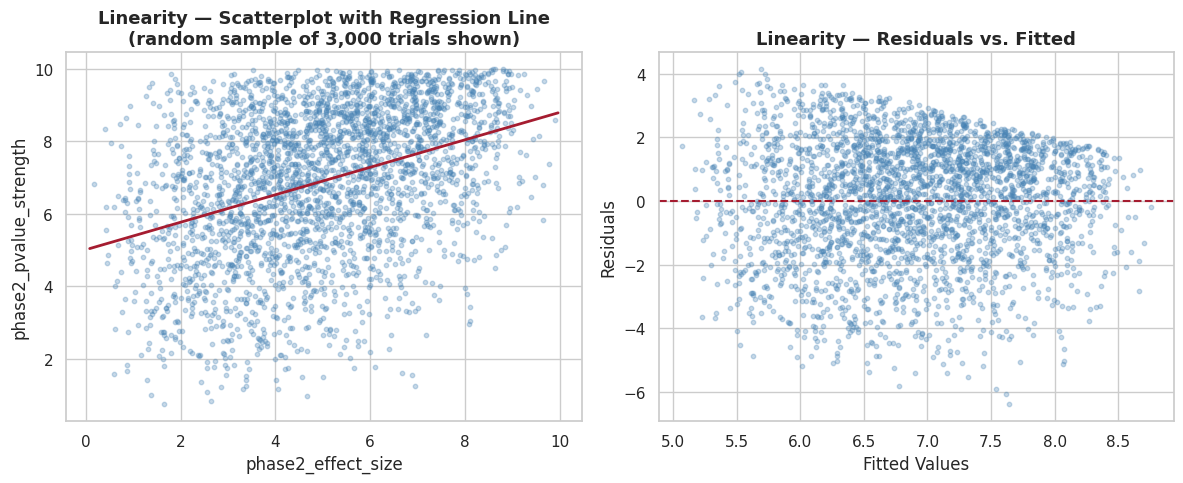

Pearson  r = 0.370   p = < 0.0001
Spearman ρ = 0.370   p = < 0.0001


In [95]:
# =============================================================================
# ASSUMPTION 1: LINEARITY
# =============================================================================
# Assessed visually via scatterplot with a regression line and a residuals-vs-
# fitted plot, and numerically via Pearson's r (with Spearman's ρ for comparison,
# because both Phase 2 scores are capped at 10).
#
# Pair chosen: the two strongest predictors of trial success. Change X_VAR /
# Y_VAR to test any other pair of continuous variables.
# =============================================================================

X_VAR = "phase2_effect_size"
Y_VAR = "phase2_pvalue_strength"

sample = df.sample(n=min(PLOT_SAMPLE, len(df)), random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Scatterplot (sample) with regression line (fit on ALL rows)
axes[0].scatter(sample[X_VAR], sample[Y_VAR], alpha=0.3, s=10, color='steelblue')
m, b = np.polyfit(df[X_VAR], df[Y_VAR], 1)
x_line = np.linspace(df[X_VAR].min(), df[X_VAR].max(), 100)
axes[0].plot(x_line, m * x_line + b, color='#A51C30', linewidth=2)
axes[0].set_xlabel(X_VAR)
axes[0].set_ylabel(Y_VAR)
axes[0].set_title(f'Linearity — Scatterplot with Regression Line\n'
                  f'(random sample of {len(sample):,} trials shown)')

# Residuals vs. Fitted (OLS fit on ALL rows, sample plotted)
model = sm.OLS(df[Y_VAR], sm.add_constant(df[X_VAR])).fit()
fitted    = model.fittedvalues.loc[sample.index]
residuals = model.resid.loc[sample.index]

axes[1].scatter(fitted, residuals, alpha=0.3, s=10, color='steelblue')
axes[1].axhline(0, color='#A51C30', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('Fitted Values')
axes[1].set_ylabel('Residuals')
axes[1].set_title('Linearity — Residuals vs. Fitted')

plt.tight_layout()
plt.show()

r,   p_r   = stats.pearsonr(df[X_VAR], df[Y_VAR])
rho, p_rho = stats.spearmanr(df[X_VAR], df[Y_VAR])
print(f"Pearson  r = {r:.3f}   p = {fmt_p(p_r)}")
print(f"Spearman ρ = {rho:.3f}   p = {fmt_p(p_rho)}")

### Interpretation of Linearity Assumption
*Interpretation of Synthetic dataset, seed 973.*

| Statistic | Value |
|---|---|
| Pearson r | 0.370 (p < 0.0001) |
| Spearman ρ | 0.370 (p < 0.0001) |

`phase2_effect_size` and `phase2_pvalue_strength` have a **weak-to-moderate positive relationship** (r² ≈ 0.14, so about 14% of the variation in one is shared with the other). Pearson and Spearman are identical, so the relationship is linear as well as monotonic. The generator builds p-value strength from a latent score that depends on effect size, and r = 0.37 reflects that.

Because the correlation is modest, both variables can be used in the same model. Each carries part of the Phase 2 signal, and their coefficients share some credit.

- **Residual plot:** the points should scatter evenly around 0 with no curve. Unlike the reference file, there is no cap at 10, so there should be no sharp diagonal edge, but it does appear there is still some edge left, which suggests the generator may still need some updates.

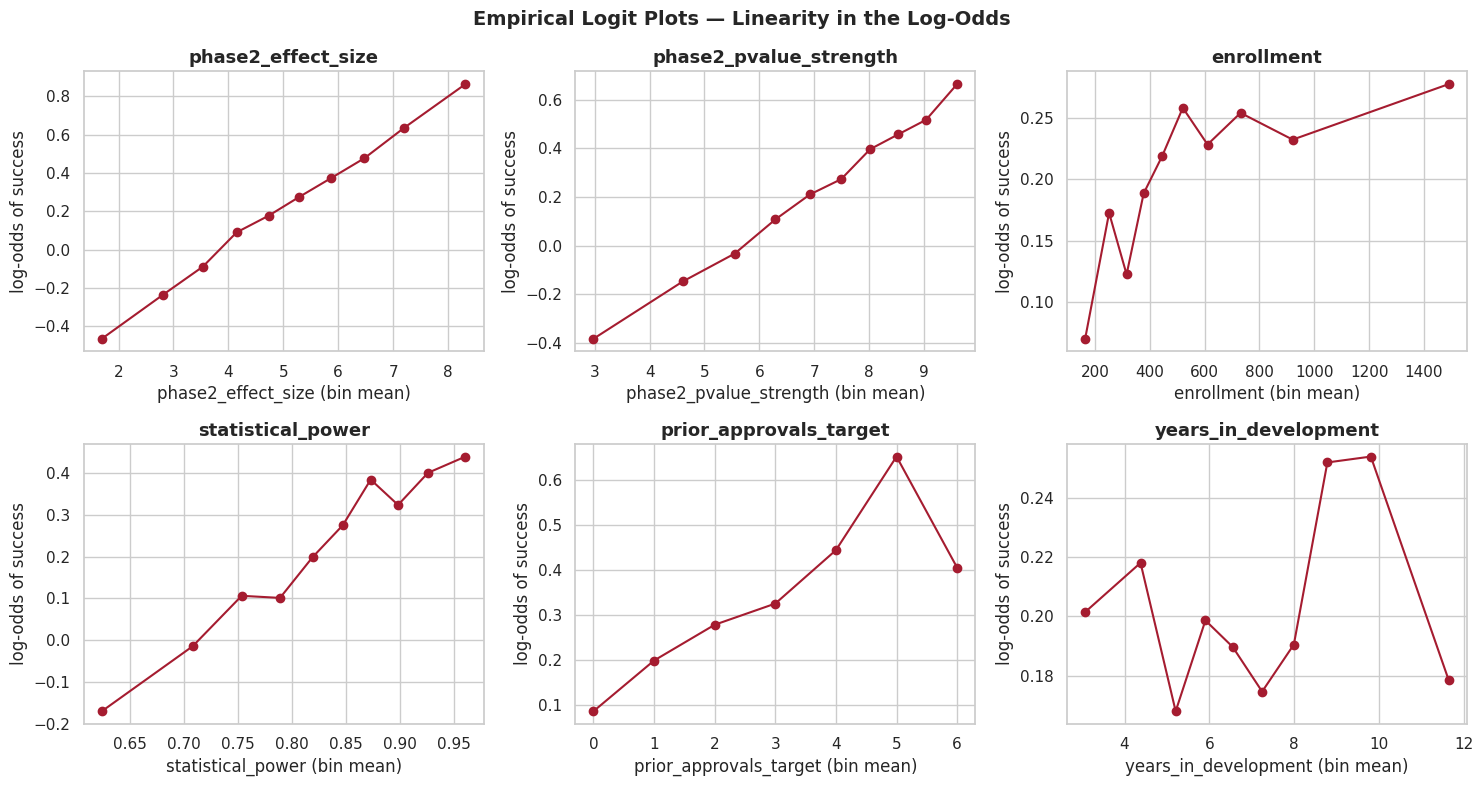

In [96]:
# =============================================================================
# ASSUMPTION 1b: LINEARITY IN THE LOG-ODDS (LOGISTIC REGRESSION)
# =============================================================================
# Logistic regression assumes each continuous predictor relates LINEARLY to the
# log-odds of success (not to the other predictors). Empirical logit plot:
# bin each predictor, compute the success rate per bin, convert to log-odds.
#   Roughly straight line → assumption OK
#   Clear curve / U-shape → consider a transform, spline, or rely on XGBoost
# =============================================================================

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    # Small counts (e.g., prior_approvals_target) are grouped by value; others by decile
    bins = df[col] if df[col].nunique() <= 15 else pd.qcut(df[col], q=10, duplicates='drop')
    g = (df.groupby(bins, observed=True)
           .agg(x=(col, 'mean'), p=(TARGET, 'mean'), n=(TARGET, 'size')))
    g = g[g['n'] >= 30]                                  # drop unstable tiny groups
    g['p'] = g['p'].clip(0.001, 0.999)
    g['logit'] = np.log(g['p'] / (1 - g['p']))

    ax.plot(g['x'], g['logit'], 'o-', color='#A51C30')
    ax.set_title(col, fontweight='bold')
    ax.set_xlabel(f'{col} (bin mean)')
    ax.set_ylabel('log-odds of success')

plt.suptitle('Empirical Logit Plots — Linearity in the Log-Odds', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

In [97]:
# =============================================================================
# ASSUMPTION 2: EQUAL VARIANCES (HOMOSCEDASTICITY / HOMOGENEITY OF VARIANCE)
# =============================================================================
# Tests whether each continuous predictor has equal variance in failed vs.
# successful trials.
# Levene's Test (median-centred, scipy default): robust to non-normality —
# preferred over Bartlett's.
# H₀: Variances are equal across trial_success groups
# =============================================================================

LEVENE_VAR = "phase2_effect_size"     # ← change to test a different variable

group0 = df[df[TARGET] == 0][LEVENE_VAR].dropna()
group1 = df[df[TARGET] == 1][LEVENE_VAR].dropna()

stat, p = stats.levene(group0, group1)
print(f"Levene's Test — {LEVENE_VAR} by {TARGET}")
print(f"  SD failed = {group0.std():.3f},  SD succeeded = {group1.std():.3f}")
print(f"  F = {stat:.4f},  p = {fmt_p(p)}")
print(f"  {'✓ Equal variances — proceed with standard t-test' if p > 0.05 else '✗ Unequal variances — use Welch t-test (equal_var=False) or Mann-Whitney U'}")

# Loop through all continuous predictors and summarize in one table.
# SD ratio is included because with n ≈ 42k Levene's test flags even tiny,
# practically irrelevant differences. A ratio between ~0.8 and 1.25 is minor.
results = []
for var in numeric_cols:
    g0 = df[df[TARGET] == 0][var].dropna()
    g1 = df[df[TARGET] == 1][var].dropna()
    stat, p = stats.levene(g0, g1)
    results.append({
        'Variable':        var,
        'SD (Failed)':     round(g0.std(), 3),
        'SD (Succeeded)':  round(g1.std(), 3),
        'SD Ratio (S/F)':  round(g1.std() / g0.std(), 3),
        'Levene F':        round(stat, 4),
        'p-value':         fmt_p(p),
        'Equal Variance?': '✓ Yes' if p > 0.05 else '✗ No'
    })

levene_df = pd.DataFrame(results)
print("\nLevene's Test for Equality of Variances — All Continuous Predictors by trial_success (0 vs 1)")
print("H₀: Variances are equal across outcome groups\n")
display(levene_df)

Levene's Test — phase2_effect_size by trial_success
  SD failed = 1.929,  SD succeeded = 1.919
  F = 1.2368,  p = 0.2661
  ✓ Equal variances — proceed with standard t-test

Levene's Test for Equality of Variances — All Continuous Predictors by trial_success (0 vs 1)
H₀: Variances are equal across outcome groups



,Variable,SD (Failed),SD (Succeeded),SD Ratio (S/F),Levene F,p-value,Equal Variance?
0,phase2_effect_size,1.929,1.919,0.994,1.2368,0.2661,✓ Yes
1,phase2_pvalue_strength,2.066,1.899,0.919,232.5282,< 0.0001,✗ No
2,enrollment,400.864,404.735,1.010,1.5038,0.2201,✓ Yes
3,statistical_power,0.103,0.097,0.940,96.1996,< 0.0001,✗ No
4,prior_approvals_target,1.066,1.110,1.041,20.6515,< 0.0001,✗ No
5,years_in_development,2.495,2.494,0.999,0.1659,0.6838,✓ Yes


### Interpretation of Equal Variances (Levene's test) Assumption
*Interpretation from Synthetic dataset, seed 973.*

| Variable | SD ratio (S/F) | Levene p | Result |
|---|---|---|---|
| phase2_effect_size | 0.994 | 0.266 | Equal |
| phase2_pvalue_strength | 0.919 | < 0.0001 | Differs |
| enrollment | 1.010 | 0.220 | Equal |
| statistical_power | 0.940 | < 0.0001 | Differs |
| prior_approvals_target | 1.041 | < 0.0001 | Differs |
| years_in_development | 0.999 | 0.684 | Equal |

Levene's test flags three variables, but **every SD ratio is between 0.92 and 1.04, so all differences are practically small** (a ratio between about 0.8 and 1.25 is minor). With 42,000 rows, the test detects differences of a few percent.

The differences are due to:
- **phase2_pvalue_strength** and **statistical_power** are bounded, left-skewed scores. Successful trials sit nearer the top of the range, so their spread is slightly smaller (SD 1.90 vs. 2.07 and 0.097 vs. 0.103).
- **prior_approvals_target** is a Poisson-type count, where variance grows with the mean. Successes have a higher mean (1.25 vs. 1.14) and therefore a larger SD (1.11 vs. 1.07).

These differences have little impact. The Mann-Whitney test is not sensitive to them, and logistic regression does not assume equal variances across outcome groups.

## Nonparametric Test 1: Mann-Whitney U Test

### Purpose in This Project

This test compares `phase2_effect_size` between failed (0) and succeeded (1) Phase 3 trials. The same test is then run on all six numeric predictors.

### Mathematical Foundation

The Mann-Whitney U test compares two independent groups without assuming a particular distribution. It pools all trials, ranks them from 1 to $N = n_1 + n_2$, and asks whether one group tends to have higher ranks than the other. Tied values receive their average rank.

Let $R_1$ be the sum of ranks for group 1 (failed trials). SciPy reports

$$
U_1 = R_1 - \frac{n_1(n_1+1)}{2}
$$

which counts the pairs (failed, succeeded) in which the failed trial has the higher value (ties count ½). Its counterpart is $U_2 = n_1 n_2 - U_1$. The two-sided p-value is the same whichever one is used.

For larger samples, $U$ is approximately normal:

$$
z = \frac{U - \frac{n_1 n_2}{2}}{\sqrt{\frac{n_1 n_2 (n_1 + n_2 + 1)}{12}}}
$$

Because many values are tied (for example, `phase2_effect_size` is recorded to two decimals), the p-value uses a tie correction and a continuity correction. `scipy.stats.mannwhitneyu` applies both by default.

### Hypotheses

$$
H_0: \text{The two distributions are equal}
$$

$$
H_1: \text{One group tends to have higher values}
$$

In probability terms, with $X$ a random failed trial and $Y$ a random succeeded trial, $H_0$ says $P(X > Y) = P(Y > X)$. The test is two-sided.

### Effect Size: Rank-Biserial Correlation

$$
r_{rb} = 1 - \frac{2U}{n_1 n_2}
$$

The value ranges from −1 to +1. The sign gives the direction. The code uses the statistic for the failed group, so **a positive r means successful trials tend to have higher values**. The code labels effects as negligible (|r| < 0.1), small (< 0.3), medium (< 0.5), or large (≥ 0.5). Because $(1 + r)/2$ approximates the probability that a random successful trial exceeds a random failed trial, an r of 0.207 corresponds to about 60%.

### Key Assumptions

1. **Independent observations.** Each trial appears once.
2. **Ordinal or continuous outcome.** The variable must be rankable.
3. **Similar distribution shapes for a location shift.** The test detects any difference between groups. It is easiest to read as a difference in medians when the shapes are similar.

Unlike the t-test, the test does not require normality or equal variances.

### When to Use It

| Situation | Use Mann-Whitney U? |
|---|---|
| Continuous or ordinal predictor, two independent groups | Yes |
| Skewed data, outliers, or capped values (for example, scores capped at 10) | Yes |
| Normality is doubtful | Yes |
| Paired or repeated measurements on the same trial | No (use Wilcoxon signed-rank) |
| More than two groups | No (use Kruskal-Wallis) |

---


Mann-Whitney U Test — phase2_effect_size by trial_success
  Failed    (0): n=18,885, median=4.520, IQR=[3.120, 6.000]
  Succeeded (1): n=23,115, median=5.380, IQR=[3.930, 6.790]
  U = 170,980,789.5
  p-value = < 0.0001
  Rank-biserial r = 0.217  (small)

  ✓ Reject H₀ — phase2_effect_size distributions differ significantly between groups
    (successful trials tend to have higher values)


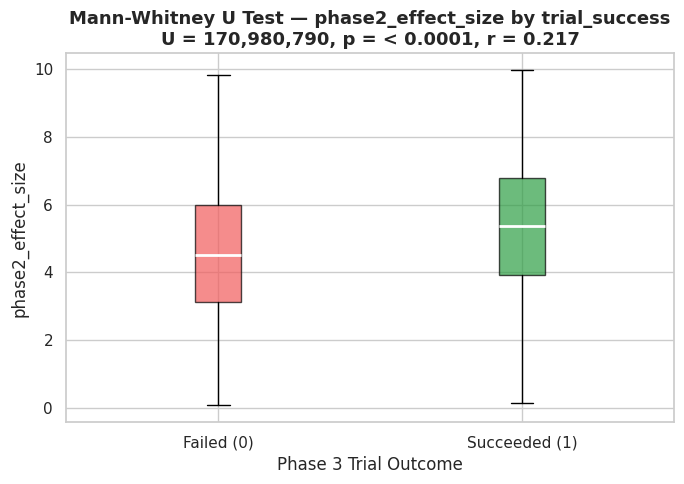


Mann-Whitney U — All Continuous Predictors (sorted by effect size)


,Variable,Median (Failed),Median (Succeeded),p-value,Rank-biserial r,Effect
0,phase2_effect_size,4.520,5.380,< 0.0001,0.217,small
1,phase2_pvalue_strength,6.790,7.520,< 0.0001,0.175,small
2,statistical_power,0.821,0.843,< 0.0001,0.105,small
3,prior_approvals_target,1.000,1.000,< 0.0001,0.052,negligible
4,enrollment,471.000,489.000,< 0.0001,0.030,negligible
5,years_in_development,6.800,6.900,0.4774,0.004,negligible


In [98]:
# =============================================================================
# NONPARAMETRIC TEST 1: MANN-WHITNEY U TEST
# =============================================================================
# Nonparametric alternative to the independent t-test.
# Tests whether Phase 2 effect size distributions differ between failed and
# successful Phase 3 trials.
#
# Test statistic (scipy returns U for the FIRST sample = failed trials):
#
#   U₁ = R₁ − n₁(n₁+1)/2        R₁ = sum of ranks of failed trials
#   U₂ = n₁n₂ − U₁
#
# For large samples:  z = (U₁ − n₁n₂/2) / √(n₁n₂(n₁+n₂+1)/12)   (tie-corrected)
#
# Rank-biserial r = 1 − 2U₁/(n₁n₂):  positive → successful trials tend to be HIGHER.
# (Using min(U₁, U₂) instead would always give r ≥ 0 and lose the direction.)
#
# H₀: phase2_effect_size distributions are equal across trial_success groups
# H₁: One group tends to have higher phase2_effect_size values
# =============================================================================

MW_VAR = "phase2_effect_size"         # ← change to test a different variable

group0 = df[df[TARGET] == 0][MW_VAR].dropna()
group1 = df[df[TARGET] == 1][MW_VAR].dropna()

u_stat, p_val = stats.mannwhitneyu(group0, group1, alternative='two-sided')

# Effect size: rank-biserial correlation
# scipy returns U for the FIRST sample (failed), so:
#   positive r → successful trials tend to have HIGHER values
n0, n1 = len(group0), len(group1)
r_rb = 1 - (2 * u_stat) / (n0 * n1)

print(f"Mann-Whitney U Test — {MW_VAR} by {TARGET}")
print(f"  Failed    (0): n={n0:,}, median={group0.median():.3f}, "
      f"IQR=[{group0.quantile(.25):.3f}, {group0.quantile(.75):.3f}]")
print(f"  Succeeded (1): n={n1:,}, median={group1.median():.3f}, "
      f"IQR=[{group1.quantile(.25):.3f}, {group1.quantile(.75):.3f}]")
print(f"  U = {u_stat:,.1f}")
print(f"  p-value = {fmt_p(p_val)}")
print(f"  Rank-biserial r = {r_rb:.3f}  ({effect_label(r_rb)})")
print()
if p_val < 0.05:
    direction = "higher" if r_rb > 0 else "lower"
    print(f"  ✓ Reject H₀ — {MW_VAR} distributions differ significantly between groups")
    print(f"    (successful trials tend to have {direction} values)")
else:
    print(f"  ✗ Fail to reject H₀ — no significant distributional difference in {MW_VAR}")

# Visualization
fig, ax = plt.subplots(figsize=(7, 5))
bp = ax.boxplot([group0, group1],
                patch_artist=True,
                medianprops=dict(color='white', linewidth=2))
for patch, color in zip(bp['boxes'], [FAIL_COLOR, SUCCESS_COLOR]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_xticks([1, 2])
ax.set_xticklabels([OUTCOME_LABELS[0], OUTCOME_LABELS[1]])
ax.set_title(f'Mann-Whitney U Test — {MW_VAR} by {TARGET}\n'
             f'U = {u_stat:,.0f}, p = {fmt_p(p_val)}, r = {r_rb:.3f}', fontweight='bold')
ax.set_xlabel('Phase 3 Trial Outcome')
ax.set_ylabel(MW_VAR)
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# All continuous predictors at once
# -----------------------------------------------------------------------------
mw_rows = []
for var in numeric_cols:
    g0 = df[df[TARGET] == 0][var].dropna()
    g1 = df[df[TARGET] == 1][var].dropna()
    u, p = stats.mannwhitneyu(g0, g1, alternative='two-sided')
    r = 1 - (2 * u) / (len(g0) * len(g1))
    mw_rows.append({'Variable': var,
                    'Median (Failed)': round(g0.median(), 3),
                    'Median (Succeeded)': round(g1.median(), 3),
                    'p-value': fmt_p(p),
                    'Rank-biserial r': round(r, 3),
                    'Effect': effect_label(r)})

mw_df = (pd.DataFrame(mw_rows)
           .sort_values('Rank-biserial r', key=abs, ascending=False)
           .reset_index(drop=True))
print("\nMann-Whitney U — All Continuous Predictors (sorted by effect size)")
display(mw_df)

### Interpretation of Mann-Whitney U
*Synthetic dataset, seed 973.*

| Variable | Median (Failed) | Median (Succeeded) | Rank-biserial r | Effect | P(success > failure)* |
|---|---|---|---|---|---|
| phase2_effect_size | 4.520 | 5.380 | 0.217 | small | 60.9% |
| phase2_pvalue_strength | 6.790 | 7.520 | 0.175 | small | 58.8% |
| statistical_power | 0.821 | 0.843 | 0.105 | small | 55.3% |
| prior_approvals_target | 1 | 1 | 0.052 | negligible | 52.6% |
| enrollment | 471 | 489 | 0.030 | negligible | 51.5% |
| years_in_development | 6.8 | 6.9 | 0.004 (p = 0.48) | negligible | 50.2% |

\*Approximate, from (1 + r) / 2.

- **Phase 2 evidence is the strongest numeric signal.** A randomly chosen successful trial has a higher `phase2_effect_size` than a randomly chosen failed trial about **61%** of the time (50% would be a coin flip). Equivalent figures: about 59% for p-value strength and 55% for power.
- **`years_in_development` is a built-in negative control.** Its planted effect is zero, and the test finds nothing (r = 0.004, p = 0.48).
- **`enrollment` and `prior_approvals_target`** are statistically significant but practically negligible. Prior approvals have identical medians (1 vs. 1); the difference is in the shape of the distribution. The enrollment signal is tiny and partly reflects its correlation with power.
- **Link to AUC:** the rank-biserial r equals 2·AUC − 1. Effect size alone therefore corresponds to an AUC of about **0.61**.

## Nonparametric Test 2: Chi-Square Test of Independence

### Purpose in This Project

This test checks whether `trial_success` is associated with `endpoint_type` (hard_survival, clinical, surrogate). The same test is then run on all six binary predictors and the three categorical predictors.

### Mathematical Foundation

For a contingency table with $r$ rows and $c$ columns, the chi-square test compares observed counts with the counts expected if the two variables were unrelated. The expected count in row $i$ and column $j$ is

$$
E_{ij} = \frac{(\text{row } i \text{ total}) \times (\text{column } j \text{ total})}{N}
$$

where $N$ is the total number of trials. The test statistic is

$$
\chi^2 = \sum_{i=1}^{r} \sum_{j=1}^{c} \frac{(O_{ij} - E_{ij})^2}{E_{ij}}
$$

where $O_{ij}$ is the observed count in cell $(i, j)$. Under $H_0$, $\chi^2$ approximately follows a chi-square distribution with

$$
\text{df} = (r - 1)(c - 1)
$$

### Hypotheses

$$
H_0: \text{trial\_success and endpoint\_type are independent}
$$

$$
H_1: \text{trial\_success and endpoint\_type are associated}
$$

Under $H_0$, the success rate is the same for every endpoint type.

### Effect Size: Cramér's V

A significant $\chi^2$ shows that an association exists, but not how strong it is. Cramér's V standardizes the statistic:

$$
V = \sqrt{\frac{\chi^2}{N \cdot \min(r-1,\; c-1)}}
$$

V ranges from 0 (no association) to 1 (perfect association). The code uses the same effect labels as the Mann-Whitney test. Because V is scaled by sample size, it is more informative than $\chi^2$ when $N$ is large.

### Decision Rules in the Code

- **If every expected count is at least 5:** use the chi-square test and report Cramér's V.
- **If any expected count is below 5 and the table is 2×2:** use Fisher's exact test. For a 2×2 table, the probability of one specific set of counts is

$$
p = \frac{R_1!\, R_2!\, C_1!\, C_2!}{n!\, a!\, b!\, c!\, d!}
$$

  where $a, b, c, d$ are the four cell counts, $R_1, R_2$ are the row totals, $C_1, C_2$ are the column totals, and $n$ is the grand total. This is the probability of the observed table under $H_0$. The Fisher p-value adds up the probabilities of all tables at least as extreme.
- **If any expected count is below 5 and the table is larger than 2×2:** the code prints a warning and does not run a test. The sparse categories would need to be combined first.

### Key Assumptions

1. **Independent observations.** Each trial is counted once.
2. **Adequate expected counts.** The chi-square approximation requires expected counts of about 5 or more. In this dataset the smallest expected count is about 1,340, so the approximation is reliable.
3. **Categorical variables.** Each variable has a fixed set of categories.

The test does not assume a distribution for the data. It relies on the large-sample approximation, which is why the expected-count rule matters.

### When to Use It

| Situation | Use chi-square? |
|---|---|
| Two categorical variables (for example, endpoint type and success) | Yes |
| A binary predictor and the binary outcome | Yes |
| Expected counts below 5 in a 2×2 table | No (use Fisher's exact test) |
| Predicting a continuous variable | No (use a t-test, ANOVA, or regression) |
| Measuring a predictor's effect after adjusting for other variables | No (use logistic regression) |

---

Contingency Table — endpoint_type × trial_success


trial_success,Failed (0),Succeeded (1),All
endpoint_type,,,
clinical,7408,9313,16721
hard_survival,6449,6004,12453
surrogate,5028,7798,12826
All,18885,23115,42000



Expected Frequencies:


trial_success,0,1
endpoint_type,,
clinical,7518.48,9202.52
hard_survival,5599.40,6853.60
surrogate,5767.12,7058.88



Minimum expected frequency: 5599.40

Chi-Square Test of Independence
  χ²(2) = 409.2961
  p-value   = < 0.0001
  Cramér's V = 0.099  (negligible)
  ✓ Reject H₀ — endpoint_type and trial success are significantly associated

Success rate by endpoint_type:


,n,success_rate
endpoint_type,,
surrogate,"12,826",60.8%
clinical,"16,721",55.7%
hard_survival,"12,453",48.2%


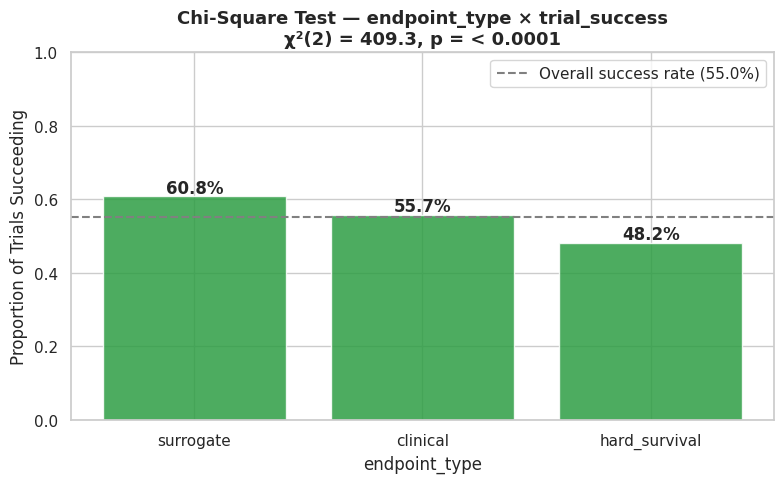


Chi-Square Tests — All Categorical & Binary Predictors vs. trial_success


,Variable,Levels,χ²,df,p-value,Cramér's V,Effect,Min Expected
0,therapeutic_area,9,645.96,8,< 0.0001,0.124,small,1355.2
1,endpoint_type,3,409.30,2,< 0.0001,0.099,negligible,5599.4
2,sponsor_type,4,219.70,3,< 0.0001,0.072,negligible,2210.0
3,uses_biomarker,2,176.83,1,< 0.0001,0.065,negligible,7863.8
4,novel_mechanism,2,72.37,1,< 0.0001,0.042,negligible,7924.5
5,orphan_designation,2,4.55,1,0.0330,0.010,negligible,3372.8
6,randomized,2,3.35,1,0.0670,0.009,negligible,2245.1
7,double_blind,2,0.93,1,0.3344,0.005,negligible,5269.4
8,active_comparator,2,0.02,1,0.8889,0.001,negligible,9345.4


In [99]:
# =============================================================================
# NONPARAMETRIC TEST 2: CHI-SQUARE TEST  —OR—  FISHER'S EXACT TEST
# =============================================================================
# Tests whether trial_success is associated with endpoint_type
# (hard_survival / clinical / surrogate). The dataset has real categorical
# predictors, so no median split of a continuous variable is needed.
#
# Chi-Square test statistic:
#
#   χ² = Σ [(Observed - Expected)² / Expected]
#   Expected_ij = (row_i total · col_j total) / grand total
#   df = (rows - 1) · (cols - 1)
#
# Fisher's Exact Test (when any expected frequency < 5; 2×2 tables only):
#
#   p = (R₁! R₂! C₁! C₂!) / (n! · a! · b! · c! · d!)
#
# H₀: trial_success and endpoint_type are independent
# H₁: trial_success and endpoint_type are associated
# =============================================================================

CAT_VAR = "endpoint_type"             # ← any categorical or binary column

contingency_table = pd.crosstab(
    df[CAT_VAR],
    df[TARGET].map(OUTCOME_LABELS),
    margins=True
)
print(f"Contingency Table — {CAT_VAR} × {TARGET}")
display(contingency_table)

ct_no_margins = pd.crosstab(df[CAT_VAR], df[TARGET])
chi2_stat, p_chi2, dof, expected = stats.chi2_contingency(ct_no_margins)

expected_df = pd.DataFrame(expected,
                           index=ct_no_margins.index,
                           columns=ct_no_margins.columns)
print("\nExpected Frequencies:")
display(expected_df.round(2))

min_expected = expected.min()
print(f"\nMinimum expected frequency: {min_expected:.2f}")

if min_expected >= 5:
    n = ct_no_margins.values.sum()
    min_dim = min(ct_no_margins.shape) - 1
    cramers_v = np.sqrt(chi2_stat / (n * min_dim))

    print("\nChi-Square Test of Independence")
    print(f"  χ²({dof}) = {chi2_stat:.4f}")
    print(f"  p-value   = {fmt_p(p_chi2)}")
    print(f"  Cramér's V = {cramers_v:.3f}  ({effect_label(cramers_v)})")
    if p_chi2 < 0.05:
        print(f"  ✓ Reject H₀ — {CAT_VAR} and trial success are significantly associated")
    else:
        print("  ✗ Fail to reject H₀ — no significant association detected")

elif ct_no_margins.shape == (2, 2):
    print("\nFisher's Exact Test (minimum expected frequency < 5)")
    a, b = ct_no_margins.iloc[0, 0], ct_no_margins.iloc[0, 1]
    c, d = ct_no_margins.iloc[1, 0], ct_no_margins.iloc[1, 1]
    odds_ratio, p_fisher = stats.fisher_exact([[a, b], [c, d]])
    print(f"  Odds Ratio = {odds_ratio:.4f}")
    print(f"  p-value    = {fmt_p(p_fisher)}")
    if p_fisher < 0.05:
        print(f"  ✓ Reject H₀ — {CAT_VAR} and trial success are significantly associated")
    else:
        print("  ✗ Fail to reject H₀ — no significant association detected")

else:
    print("\n⚠ Expected count < 5 in a table larger than 2×2 — Fisher's exact test")
    print("  does not apply. Combine sparse categories and re-run.")

# Success rate per category (easier to interpret than raw counts)
rate_df = (df.groupby(CAT_VAR)[TARGET]
             .agg(n='size', success_rate='mean')
             .sort_values('success_rate', ascending=False))
print(f"\nSuccess rate by {CAT_VAR}:")
display(rate_df.style.format({'n': '{:,}', 'success_rate': '{:.1%}'}))

# Visualization
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(rate_df.index.astype(str), rate_df['success_rate'],
              color=SUCCESS_COLOR, edgecolor='white', alpha=0.85)
ax.axhline(df[TARGET].mean(), color='gray', linestyle='--', linewidth=1.5,
           label=f'Overall success rate ({df[TARGET].mean():.1%})')
for bar, val in zip(bars, rate_df['success_rate']):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.01, f'{val:.1%}',
            ha='center', fontweight='bold')
ax.set_title(f'Chi-Square Test — {CAT_VAR} × {TARGET}\n'
             f'χ²({dof}) = {chi2_stat:.1f}, p = {fmt_p(p_chi2)}', fontweight='bold')
ax.set_xlabel(CAT_VAR)
ax.set_ylabel('Proportion of Trials Succeeding')
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# All categorical and binary predictors at once
# -----------------------------------------------------------------------------
chi_rows = []
for var in categorical_cols + binary_cols:
    ct = pd.crosstab(df[var], df[TARGET])
    chi2, p, dof_v, exp = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    chi_rows.append({'Variable': var, 'Levels': ct.shape[0],
                     'χ²': round(chi2, 2), 'df': dof_v, 'p-value': fmt_p(p),
                     "Cramér's V": round(v, 3), 'Effect': effect_label(v),
                     'Min Expected': round(exp.min(), 1)})

chi_df = (pd.DataFrame(chi_rows)
            .sort_values("Cramér's V", ascending=False)
            .reset_index(drop=True))
print("\nChi-Square Tests — All Categorical & Binary Predictors vs. trial_success")
display(chi_df)

### Interpretation of Chi-Square Test of Independence
*Interpretation from Synthetic dataset, seed 973.*

**Endpoint type:** χ²(2) = 409.3, p < 0.0001, Cramér's V = 0.099 (negligible, just under the 0.10 "small" cut-off).

| Endpoint type | n | Success rate | Successes vs. expected |
|---|---|---|---|
| Surrogate | 12,826 | 60.8% | +739 |
| Clinical | 16,721 | 55.7% | +110 |
| Hard survival | 12,453 | 48.2% | −850 |

Success depends on how demanding the endpoint is, in the given order (hard survival < clinical < surrogate). The smallest expected count is 5,599, so the chi-square approximation is reliable.

**All categorical and binary predictors (ranked by Cramér's V):**

| Variable | Cramér's V | p-value | Verdict |
|---|---|---|---|
| therapeutic_area | 0.124 | < 0.0001 | Small, the strongest |
| endpoint_type | 0.099 | < 0.0001 | Negligible/small boundary |
| sponsor_type | 0.072 | < 0.0001 | Negligible |
| uses_biomarker | 0.065 | < 0.0001 | Negligible but significant |
| novel_mechanism | 0.042 | < 0.0001 | Negligible but significant |
| orphan_designation | 0.010 | 0.033 | Not significant after correction |
| randomized | 0.009 | 0.067 | Not significant |
| double_blind | 0.005 | 0.334 | Not significant |
| active_comparator | 0.001 | 0.889 | Not significant |

With nine tests, the Bonferroni threshold is p < 0.0056. The first five pass. `orphan_designation` (p = 0.033) is significant only without correction, and the last three are not significant. Their planted effects are tiny (|log-odds| ≤ 0.08), and the observed rate differences are 1.4 points or less, so "not significant" means "too small to detect here", not "exactly zero". Chi-square shows association, not direction. Direction comes from the logistic regression odds ratios.

### Overall Findings of Statistical Tests
*Interpretation of Synthetic dataset, seed 973.*

1. **No single predictor is strong.** The largest effects are small (rank-biserial r = 0.217, Cramér's V = 0.124).
2. **The most informative predictors** are the Phase 2 evidence variables (effect size, p-value strength, power), therapeutic area, endpoint type, and sponsor type. Biomarker use and novel mechanism are smaller but clearly detectable.
3. **Little or no information:** `years_in_development`, `active_comparator`, `double_blind`, `randomized`, `orphan_designation`, and (practically) `enrollment` and `prior_approvals_target`.
4. **These tests match the models.** The variables with the largest effects here also have the largest logistic-regression odds ratios. The near-1 odds ratios match the negligible effects.
5. **Small individual effects explain the modest model performance.** The best test AUC is 0.667, close to the ceiling set by the noise built into the data.
6. **These are one-variable-at-a-time tests.** They do not adjust for other predictors, so the logistic regression remains the better guide to each variable's independent contribution.

## Supervised Classification Models

### **Binary Classification**

### Formalizing the Machine Learning Problem

In supervised machine learning, we begin with a dataset consisting of observations (examples) and their corresponding target labels. We denote the complete dataset as

$$
\mathcal{D}=\{(x_i,y_i)\}_{i=1}^{n},
\qquad
y_i\in\{0,1\}.
$$

where

- $\mathcal{D}$ denotes the complete dataset, which is later split into a training set and a held-out test set.
- $n$ is the total number of observations (rows) in the dataset. Here, each observation is **one Phase 3 clinical trial** ($n \approx 42{,}000$).
- $i$ represents the index of an individual observation, where $i=1,2,\ldots,n$.
- $x_i$ is the feature vector (predictor variables) describing the $i^{th}$ trial.
- $p$ is the total number of predictor (feature) variables.
- $y_i$ is the target (response) variable associated with trial $i$.
- $\{0,1\}$ indicates that this is a **binary classification** problem, where:
  - $0$ represents a trial that **failed** to meet its primary endpoint
  - $1$ represents a trial that **succeeded** in meeting its primary endpoint

About 55% of trials in the dataset succeeded, so the two classes are roughly balanced.

For the clinical trials dataset used in this notebook,

$$
x_i=
\begin{bmatrix}
\text{therapeutic_area}\\
\text{endpoint_type}\\
\text{sponsor_type}\\
\text{phase2_effect_size}\\
\text{phase2_pvalue_strength}\\
\text{enrollment}\\
\text{statistical_power}\\
\text{prior_approvals_target}\\
\text{years_in_development}\\
\text{uses_biomarker}\\
\text{novel_mechanism}\\
\text{randomized}\\
\text{double_blind}\\
\text{active_comparator}\\
\text{orphan_designation}
\end{bmatrix},
\qquad
y_i=\text{trial_success}
$$

The 15 raw predictors fall into three groups:

| **Group** | **Variables** | **Levels / Type** | **Count** |
|---|---|---|---|
| **Categorical (nominal)** | `therapeutic_area` (9), `endpoint_type` (3), `sponsor_type` (4) | unordered string labels | 3 |
| **Numeric (ratio / interval)** | `phase2_effect_size`, `phase2_pvalue_strength`, `enrollment`, `statistical_power`, `prior_approvals_target`, `years_in_development` | continuous, bounded, right‑skewed for enrollment & scores | 6 |
| **Binary (0/1)** | `uses_biomarker`, `novel_mechanism`, `randomized`, `double_blind`, `active_comparator`, `orphan_designation` | indicator variables | 6 |

`trial_id` is only an identifier and is **not** included in $x_i$.

#### From Raw Predictors to a Numeric Feature Space

Machine learning algorithms require numeric inputs, but three of the predictors are categorical (text labels such as *oncology* or *large_pharma*). Before modeling, each categorical predictor is **one-hot encoded**: replaced by a set of 0/1 indicator columns, one per category level. We write this encoding step as a function $\phi$:

$$
\phi(x_i) \in \mathbb{R}^{p}
$$

where $\mathbb{R}^{p}$ denotes the $p$-dimensional real-valued feature space produced by the encoding.

| Model | Encoding / scaling details | Resulting dimensionality \(p\) |
|---|---|---|
| **Logistic Regression (LR)** | One‑hot encoding **with one level dropped** (reference group: oncology / hard_survival / large_pharma). Numeric columns are Yeo‑Johnson transformed (only `enrollment` is notably skewed) and then standardised. Binary columns are left as raw 0/1. | 25 |
| **Support Vector Machine (SVM)** | All categorical columns are **one‑hot encoded with *all* levels kept** (trees don’t need a reference level). All numeric columns are Yeo‑Johnson transformed **and then standardised** because SVM is distance‑based. | 28 |
| **Decision Tree (DT)** | One‑hot encoding with *all* levels kept (no reference level). **No scaling** – trees split on raw values. | 28 |
| **XGBoost (XGB)** | Same preprocessing as DT (full one‑hot, raw numeric, binary). | 28 |

#### The Prediction Function

Each trial is therefore represented by a vector of predictor variables, and the machine learning algorithm learns an estimated prediction function

$$
\hat{f}:\mathbb{R}^{p}\rightarrow\{0,1\},
$$

where

- $\hat{f}$ (pronounced *"f-hat"*) denotes the **estimated prediction function** learned from the training data.
- The "hat" indicates that the function is an **estimate** of the unknown relationship between the trial's characteristics and whether it succeeds.

In practice, the models in this notebook first estimate the **probability** that a trial succeeds, and then convert that probability into a class label using a decision threshold:

$$
\hat{p}(x_i) = \widehat{P}\left(y_i = 1 \mid x_i\right),
\qquad
\hat{f}(x_i) =
\begin{cases}
1 \;(\text{success}) & \text{if } \hat{p}(x_i) \geq \theta \\
0 \;(\text{failure}) & \text{if } \hat{p}(x_i) < \theta
\end{cases}
$$

The function $\hat{f}(\cdot)$ maps a trial's characteristics to a predicted outcome.

The objective of supervised learning is to estimate the function $\hat{f}(\cdot)$ so that it accurately predicts the outcome of trials that were **not** used during model training. Because about 55% of trials succeed, a model that always predicts "success" would already be about 55% accurate. A useful model must do meaningfully better than this baseline.

---

### Summary of the modelling pipeline for the clinical‑trial data  

| Step | What happens | Why it matters |
|---|---|---|
| **1. Upload & validate** | Automatic checks for missing values, duplicate `trial_id`s, valid categorical levels, reasonable numeric ranges. | Guarantees data quality before any inference. |
| **2. Split** | Stratified 80/20 train‑test split (preserves the 55 % success rate). | Provides an unbiased test set for final performance. |
| **3. Adaptive preprocessing** | `make_preprocessor(scale=True)` for LR & SVM (standardization required); `scale=False` for DT & XGB (trees need raw values). | Avoids leakage and ensures each algorithm gets the representation it needs. |
| **4. Model families** | LR (linear, interpretable), SVM (linear + RBF, margin‑based), Decision Tree (rule‑based, readable profiles), XGBoost (gradient‑boosted trees). | Covers the full range required by the assignment and lets us test whether non‑linear interactions improve precision. |
| **5. Hyper‑parameter tuning** | Grid‑/Randomized‑search **optimised for `precision_at_k`** (primary metric) and cross‑validated on the training set. | Guarantees that any improvement is measured on the same business‑relevant metric. |
| **6. Model selection** | Pick the model with highest CV precision@30 % (ties broken by simplicity). | Aligns with the sponsor’s need for a transparent, high‑precision scoring system. |
| **7. Threshold selection** | Determine the probability cut‑off that yields the **target precision** (default 70 %) while keeping recall ≥ 20 % (using out‑of‑fold predictions). | Translates the model’s scores into an actionable “fund / don’t fund” rule. |
| **8. Final evaluation** | Report precision@k, average precision, AUC‑ROC, confusion matrix (highlighting funded‑but‑failed cells), precision‑recall curve, ROC curve, and permutation‑importance (precision drop when a variable is shuffled). | Provides a complete picture of performance, explainability, and the monetary impact of each predictor. |
| **9. Decision support** | Lift chart, decile‑wise success rates, scenario tool (what‑if a sponsor changes a design variable). | Helps portfolio committees translate model output into concrete funding decisions. |

### Evaluation Metrics

With $TP$, $FP$, $TN$, $FN$ = true/false positives/negatives (positive = trial succeeded):

$$
\text{Precision}=\frac{TP}{TP+FP},\qquad
\text{Recall}=\frac{TP}{TP+FN},\qquad
F_1=\frac{2\cdot\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}},\qquad
\text{Accuracy}=\frac{TP+TN}{N}
$$

- **Precision:** of the trials the model calls "likely success", the share that actually succeeded. This is the key number for a sponsor deciding where to invest.
- **Recall:** of the trials that succeeded, the share the model identified. Low recall means promising drugs could be wrongly deprioritized.

**AUC-ROC** is the probability that the model gives a randomly chosen successful trial a higher score than a randomly chosen failed one:

$$
\text{AUC}=P\big(\hat p(X_{\text{success}})>\hat p(X_{\text{fail}})\big)=\frac{U}{n_{\text{success}}\, n_{\text{fail}}}
$$

This is the **Mann-Whitney U statistic** from the inferential section, applied to the model's predicted probabilities instead of a single predictor. The rank-biserial correlation is therefore $r_{rb}=2\,\text{AUC}-1$. On its own, `phase2_effect_size` had $r_{rb}=0.217$, which corresponds to an AUC of about 0.61. Combining all 15 characteristics raises this only to about **0.667** on the test set.

### Why Precision Is the Primary Metric

A Phase 3 trial is the most expensive step in drug development. The worst outcome for a sponsor is to **fund a trial that then fails**: the investment is lost, years of development time are lost, and patients are enrolled in a study that produces no usable treatment. The model's job is therefore to make sure that **the trials it recommends funding actually succeed**.

| | Trial succeeded | Trial failed |
|---|---|---|
| **Model says "fund" (go)** | True positive (TP) | **False positive (FP): funded a failure, the costliest error** |
| **Model says "don't fund" (no-go)** | False negative (FN): missed a success | True negative (TN) |

**Precision** is the share of funded trials that succeed:

$$
\text{Precision}=\frac{TP}{TP+FP}=\widehat{P}(\text{success}\mid\text{funded})
$$

**The bar to beat.** Funding every trial gives a precision equal to the overall success rate, $\pi = 0.55$. A useful model must do clearly better than 55%.

**Comparing models fairly: precision@k.** A model can raise its precision simply by recommending fewer trials. Funding only the single most promising trial could give 100% precision while abandoning nearly every successful drug. Models are therefore compared at the **same funding rate** $k$ (30% by default):

$$
\text{Precision@}k=\frac{1}{\lceil kN\rceil}\sum_{i\,\in\,\text{top }\lceil kN\rceil} y_i
$$

This is the success rate among the $\lceil kN\rceil$ trials the model ranks highest. It answers the portfolio question directly: *"If we can fund 30% of proposed trials, what share of the ones we fund will succeed?"*

**Average precision (AP)** summarises precision over **all** funding levels, where $P_n$ and $R_n$ are the precision and recall at the $n$-th threshold:

$$
\text{AP}=\sum_{n}(R_n-R_{n-1})\,P_n
$$

**Cost link.** For an average Phase 3 cost $\bar C$, the money spent on trials that fail is

$$
\text{Wasted investment}=FP\times\bar C
$$

so every point of precision gained at a fixed funding level is a direct saving.

**Guardrails.** Recall (the share of successful drugs that get funded) is still reported. A threshold is never chosen if it would fund fewer than `MIN_RECALL` (20%) of the trials that would succeed, because dropping good drugs also has a cost to the sponsor and to patients. AUC-ROC is reported as a secondary, threshold-free measure of ranking quality.

In [100]:
# =============================================================================
# SUPERVISED MACHINE LEARNING — CLASSIFICATION
# =============================================================================

# Core scientific computing
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import warnings
warnings.filterwarnings("ignore")

# =============================================================================
# Preprocessing
# =============================================================================
from sklearn.preprocessing import (
    StandardScaler,
    PowerTransformer,
    LabelEncoder
)
from sklearn.impute import KNNImputer

# =============================================================================
# Model selection and pipeline
# =============================================================================
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)
from sklearn.pipeline import Pipeline

# =============================================================================
# Class imbalance
# =============================================================================
%pip install imbalanced-learn
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# =============================================================================
# Classifiers — Module 3
# =============================================================================
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

# =============================================================================
# Evaluation metrics
# =============================================================================
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay
)
from sklearn.metrics import make_scorer

# =============================================================================
# Reproducibility
# =============================================================================
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

%matplotlib inline
sns.set_theme(style="whitegrid")

print("=" * 60)
print("Module 3 libraries loaded successfully.")
print(f"Random seed set to {RANDOM_STATE}.")
print("=" * 60)


Module 3 libraries loaded successfully.
Random seed set to 42.


In [101]:
# =============================================================================
# PRECISION-FOCUSED SETTINGS AND SCORERS
# =============================================================================
# Business framing: funding a Phase 3 trial that then FAILS (a false positive)
# is the costliest error, so PRECISION, the share of funded trials that
# succeed, is the primary metric.
#
# Precision at the default 0.5 cut-off is NOT a fair way to compare models:
# any model can raise it by recommending fewer trials. Models are therefore
# compared on precision at a FIXED funding rate: "if the sponsor funds only
# the top FUNDING_RATE share of trials ranked by the model, what share succeed?"
# =============================================================================
FUNDING_RATE     = 0.30    # share of trials the sponsor can fund (top-ranked by the model)
TARGET_PRECISION = 0.70    # desired success rate among funded trials → sets the decision threshold
MIN_RECALL       = 0.20    # never pick a threshold that funds < 20% of the trials that will succeed
LARGE_DATA_ROWS  = 20_000  # above this many training rows, exact RBF-SVM → scalable approximation

# ── Input validation ───────────────────────────────────────────
for _name, _val in {"FUNDING_RATE": FUNDING_RATE, "TARGET_PRECISION": TARGET_PRECISION,
                    "MIN_RECALL": MIN_RECALL}.items():
    if not 0 < _val < 1:
        raise ValueError(f"{_name} must be between 0 and 1 (got {_val})")
if TIE_TOLERANCE < 0:
    raise ValueError("TIE_TOLERANCE must be ≥ 0")


def positive_scores(model, X):
    """Predicted probability (or decision score) that the trial SUCCEEDS (class 1)."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    if hasattr(model, "decision_function"):
        return model.decision_function(X)
    raise TypeError(f"{type(model).__name__} has neither predict_proba nor decision_function")


def precision_at_k(y_true, scores, k=None):
    """Success rate among the top-k share of trials ranked by the model (k defaults to FUNDING_RATE)."""
    k = FUNDING_RATE if k is None else k
    y_true = np.asarray(y_true)
    n_fund = max(1, int(round(k * len(scores))))
    top = np.argsort(-np.asarray(scores), kind="stable")[:n_fund]   # highest scores first
    return y_true[top].mean()


def precision_at_k_scorer(estimator, X, y):
    """scikit-learn scorer signature (estimator, X, y) → usable in CV and hyperparameter searches."""
    return precision_at_k(y, positive_scores(estimator, X))


# Every CV / tuning step records all of these; refit=PRIMARY chooses the final parameters.
PRIMARY = "precision_at_k"
SCORING = {
    "precision_at_k":    precision_at_k_scorer,  # PRIMARY: precision when funding the top 30%
    "average_precision": "average_precision",    # precision averaged over all funding levels
    "roc_auc":           "roc_auc",
    "precision":         "precision",            # at the default 0.5 threshold
    "recall":            "recall",
    "f1":                "f1",
    "accuracy":          "accuracy",
}
print(f"Primary metric: precision among the top {FUNDING_RATE:.0%} of trials (5-fold CV)")
print(f"Decision threshold target: {TARGET_PRECISION:.0%} precision with recall ≥ {MIN_RECALL:.0%}")

Primary metric: precision among the top 30% of trials (5-fold CV)
Decision threshold target: 70% precision with recall ≥ 20%


In [102]:
# =============================================================================
# SHARED EVALUATION FUNCTIONS — PRECISION-FOCUSED
# =============================================================================
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score)


def _predict_at(model, X, threshold):
    """Class predictions at a chosen probability threshold (falls back to .predict())."""
    if not 0 < threshold < 1:
        raise ValueError(f"threshold must be between 0 and 1 (got {threshold})")
    if hasattr(model, "predict_proba"):
        return (model.predict_proba(X)[:, 1] >= threshold).astype(int)
    return model.predict(X)


def get_metrics_score(model, X_train, X_test, y_train, y_test, threshold=0.5, verbose=True):
    """
    Train and test metrics with PRECISION listed first (primary metric).

    Extra rows (printed only): precision when funding the top FUNDING_RATE of trials,
    specificity (share of failed trials correctly NOT funded), and the number of
    failed trials the model would have funded (false positives).

    Returns (unchanged order, so existing index-based code keeps working):
        [train_acc, test_acc, train_recall, test_recall, train_precision,
         test_precision, train_f1, test_f1, train_auc, test_auc]
    """
    def block(X, y):
        s, yhat = positive_scores(model, X), _predict_at(model, X, threshold)
        tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
        return {"Precision":                        precision_score(y, yhat, zero_division=0),
                f"Precision @ top {FUNDING_RATE:.0%}": precision_at_k(y, s),
                "Recall":                           recall_score(y, yhat, zero_division=0),
                "Specificity":                      tn / (tn + fp) if (tn + fp) else np.nan,
                "F1-Score":                         f1_score(y, yhat, zero_division=0),
                "Accuracy":                         accuracy_score(y, yhat),
                "AUC-ROC":                          roc_auc_score(y, s),
                "Trials funded (predicted go)":     int(tp + fp),
                "Failed trials funded (FP)":        int(fp)}

    tr, te = block(X_train, y_train), block(X_test, y_test)

    if verbose:
        print("=" * 58)
        print(f"{'Metric (threshold = ' + f'{threshold:.2f})':<36} {'Train':>9}  {'Test':>9}")
        print("=" * 58)
        for key in tr:
            fmt = "{:>9,}" if isinstance(tr[key], int) else "{:>9.3f}"
            star = "  ← primary" if key.startswith("Precision") else ""
            print(f"{key:<36} {fmt.format(tr[key])}  {fmt.format(te[key])}{star}")
        print("=" * 58)

    return [tr["Accuracy"], te["Accuracy"], tr["Recall"], te["Recall"],
            tr["Precision"], te["Precision"], tr["F1-Score"], te["F1-Score"],
            tr["AUC-ROC"], te["AUC-ROC"]]


def make_confusion_matrix(model, X, y_actual, title="Confusion Matrix", threshold=0.5,
                          class_names=("Failed", "Succeeded")):
    """Confusion matrix in funding terms; the costly cell (funded but failed) is outlined."""
    y_pred = _predict_at(model, X, threshold)
    cm = confusion_matrix(y_actual, y_pred, labels=[0, 1])
    meaning = [["Correctly NOT funded", "Funded but FAILED\n(costliest error)"],
               ["Missed success\n(not funded)", "Funded and succeeded"]]
    labels = np.array([[f"{meaning[i][j]}\n{cm[i, j]:,}  ({cm[i, j] / cm.sum():.1%})"
                        for j in range(2)] for i in range(2)])
    precision = cm[1, 1] / cm[:, 1].sum() if cm[:, 1].sum() else np.nan

    fig, ax = plt.subplots(figsize=(8, 5.5))
    sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=[f"Predicted: {class_names[0]} (no-go)", f"Predicted: {class_names[1]} (go)"],
                yticklabels=[f"Actual: {class_names[0]}", f"Actual: {class_names[1]}"])
    ax.add_patch(plt.Rectangle((1, 0), 1, 1, fill=False, edgecolor=FAIL_COLOR, lw=4))
    ax.set_title(f"{title}\nthreshold = {threshold:.2f}  |  precision: {precision:.1%} of funded trials succeeded",
                 fontsize=12, fontweight="bold")
    ax.set_ylabel("True outcome"); ax.set_xlabel("Model recommendation")
    plt.tight_layout(); plt.show()

    print("Classification Report:")
    print(classification_report(y_actual, y_pred, target_names=list(class_names), zero_division=0))


def plot_roc_curve(model, X_test, y_test, model_name="Model"):
    """ROC curve (secondary: ranking quality across all thresholds)."""
    s = positive_scores(model, X_test)
    fpr, tpr, _ = roc_curve(y_test, s)
    auc_score = roc_auc_score(y_test, s)
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(fpr, tpr, color="#A51C30", lw=2, label=f"{model_name}  (AUC = {auc_score:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random (AUC = 0.500)")
    ax.fill_between(fpr, tpr, alpha=0.1, color="#A51C30")
    ax.set_xlabel("False Positive Rate (share of failed trials funded)")
    ax.set_ylabel("True Positive Rate (share of successful trials funded)")
    ax.set_title(f"ROC Curve — {model_name}", fontweight="bold")
    ax.legend(); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    plt.tight_layout(); plt.show()
    return auc_score


def plot_pr_curve(model, X_test, y_test, model_name="Model", mark_thresholds=(0.5,)):
    """Precision–recall curve (primary view): how precision changes as fewer trials are funded."""
    s = positive_scores(model, X_test)
    prec, rec, _ = precision_recall_curve(y_test, s)
    ap = average_precision_score(y_test, s)
    base = np.mean(y_test)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(rec, prec, color=MAIN_COLOR, lw=2, label=f"{model_name}  (AP = {ap:.3f})")
    ax.axhline(base, color="gray", ls="--", label=f"Fund every trial ({base:.1%})")
    ax.axhline(TARGET_PRECISION, color=SUCCESS_COLOR, ls=":", lw=2,
               label=f"Target precision ({TARGET_PRECISION:.0%})")
    for t in mark_thresholds:
        yhat = _predict_at(model, X_test, t)
        ax.plot(recall_score(y_test, yhat, zero_division=0),
                precision_score(y_test, yhat, zero_division=0),
                "o", ms=10, mec="black", label=f"Threshold {t:.2f}")
    ax.set_xlabel("Recall (share of successful trials funded)")
    ax.set_ylabel("Precision (share of funded trials that succeed)")
    ax.set_title(f"Precision–Recall Curve — {model_name}", fontweight="bold")
    ax.set_xlim(0, 1); ax.set_ylim(0.4, 1.0); ax.legend(fontsize=9)
    plt.tight_layout(); plt.show()
    return ap


print("Evaluation functions defined: get_metrics_score(), make_confusion_matrix(), "
      "plot_roc_curve(), plot_pr_curve()")

Evaluation functions defined: get_metrics_score(), make_confusion_matrix(), plot_roc_curve(), plot_pr_curve()


### Train / Test Split and Cross-Validation

The data are split once into two non-overlapping sets:

| Subset | Share | Purpose |
|---|---|---|
| Training set | 80% (33,600 trials) | Fit models and tune hyperparameters |
| Test set | 20% (8,400 trials) | Final, untouched estimate of performance on new trials |

There is no separate validation set. Hyperparameters are tuned with **5-fold stratified cross-validation inside the training set**. The training data are split into 5 parts, and each part takes a turn as the validation fold. This uses the data more efficiently than a single validation set, and the test set stays completely unseen until final evaluation.

**Stratified** splitting (`stratify=y`) keeps the 55/45 success/failure ratio the same in every split.

In [103]:
# =============================================================================
# SETUP: FEATURES, TARGET, SPLIT
# =============================================================================
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import RandomizedSearchCV

TARGET = "trial_success"
ID_COL = "trial_id"

categorical_cols = ["therapeutic_area", "endpoint_type", "sponsor_type"]
numeric_cols     = ["phase2_effect_size", "phase2_pvalue_strength", "enrollment",
                    "statistical_power", "prior_approvals_target", "years_in_development"]
binary_cols      = ["uses_biomarker", "novel_mechanism", "randomized",
                    "double_blind", "active_comparator", "orphan_designation"]

X = df[categorical_cols + numeric_cols + binary_cols]     # trial_id excluded
y = df[TARGET].astype(int)

# Missing-value check (KNNImputer has been removed from both pipelines)
n_missing = X.isnull().sum().sum()
print(f"Missing values in predictors: {n_missing}")
if n_missing > 0:
    print("  → Add SimpleImputer(strategy='median') to the numeric branches below.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape[0]:,} rows | Test: {X_test.shape[0]:,} rows")
print(f"Class balance (train): {y_train.value_counts(normalize=True).round(3).to_dict()}")
print(f"Majority-class baseline accuracy (always predict 'success'): "
      f"{y_test.value_counts(normalize=True).max():.3f}  ← the bar to beat")

Missing values in predictors: 0
Train: 33,600 rows | Test: 8,400 rows
Class balance (train): {1: 0.55, 0: 0.45}
Majority-class baseline accuracy (always predict 'success'): 0.550  ← the bar to beat


### Conditional Logic: How the pipeline adapts
The pipeline is not hard-coded. It inspects the training data and the user settings, then configures itself:

| Condition checked | If true | If false (this dataset) |
|---|---|---|
| Missing values present | Add median / most-frequent imputers | No imputer |
| Class ratio > `IMBALANCE_RATIO_MAX` | `class_weight='balanced'`, XGBoost `scale_pos_weight` | No reweighting (ratio ≈ 1.2) |
| Numeric column \|skew\| > `SKEW_THRESHOLD` | Yeo-Johnson transform | Standardize only |
| Rows > `LARGE_DATA_ROWS` | Randomized search, linear SVM | Grid search, RBF SVM |
| Expected count < 5 (chi-square) | Fisher's exact test | Chi-square |
| `DECISION_GOAL` | Threshold chosen for precision, recall, or F1 | — |

The same notebook can therefore be reused on a different trial dataset (for example, one with missing values or more rare successes) without code changes.

In [104]:
# =============================================================================
# DATA-DRIVEN PIPELINE CONFIGURATION (conditional logic)
# =============================================================================
from sklearn.impute import SimpleImputer

def profile_dataset(X, y):
    """Inspect the TRAINING data and decide how the pipeline should adapt."""
    counts = y.value_counts()
    prof = {
        "n_rows":              len(X),
        "missing_numeric":     bool(X[numeric_cols + binary_cols].isna().any().any()),
        "missing_categorical": bool(X[categorical_cols].isna().any().any()),
        "imbalance_ratio":     counts.max() / counts.min(),
        # discrete counts (≤ 15 unique values) are not transformed
        "skewed_cols": [c for c in numeric_cols
                        if X[c].nunique() > 15 and abs(X[c].skew()) > SKEW_THRESHOLD],
    }
    prof["class_weight"]     = "balanced" if prof["imbalance_ratio"] > IMBALANCE_RATIO_MAX else None
    prof["scale_pos_weight"] = counts[0] / counts[1] if prof["class_weight"] else 1.0
    prof["large_data"]       = prof["n_rows"] > LARGE_DATA_ROWS
    return prof

def report_profile(p):
    """Print every adaptive decision and the reason behind it."""
    print("Pipeline decisions based on the training data:")
    print(f"  • Imputation:       {'median/most-frequent imputers ADDED' if p['missing_numeric'] or p['missing_categorical'] else 'none (no missing values)'}")
    print(f"  • Class imbalance:  ratio {p['imbalance_ratio']:.2f} → "
          f"{'class_weight=balanced' if p['class_weight'] else 'no reweighting'} (limit {IMBALANCE_RATIO_MAX})")
    print(f"  • Skewed columns:   {p['skewed_cols'] or 'none'} → Yeo-Johnson (|skew| > {SKEW_THRESHOLD})")
    print(f"  • Dataset size:     {p['n_rows']:,} rows → "
          f"{'RandomizedSearchCV + linear SVM' if p['large_data'] else 'GridSearchCV + RBF SVM'}")

def build_preprocessor(profile, scale=True):
    """
    Conditional preprocessing:
      • imputers only if the profile found missing values
      • Yeo-Johnson only on columns the profile flagged as skewed
      • scaling + drop-first encoding only for scale-sensitive models (LR, SVM, MLP);
        tree models get unscaled data with all category levels
    """
    def maybe_impute(steps, strategy):
        needs = profile["missing_numeric"] if strategy == "median" else profile["missing_categorical"]
        steps = ([("impute", SimpleImputer(strategy=strategy))] if needs else []) + steps
        return Pipeline(steps) if steps else "passthrough"

    cat = maybe_impute([("ohe", OneHotEncoder(categories=level_order,
                                              drop="first" if scale else None))], "most_frequent")
    if not scale:
        return ColumnTransformer([("cat", cat, categorical_cols),
                                  ("num", maybe_impute([], "median"), numeric_cols + binary_cols)])

    skewed = profile["skewed_cols"]
    other  = [c for c in numeric_cols if c not in skewed]
    parts  = [("cat", cat, categorical_cols)]
    if skewed:
        parts.append(("skew", maybe_impute([("yj", PowerTransformer(standardize=True))], "median"), skewed))
    parts += [("num", maybe_impute([("scale", StandardScaler())], "median"), other),
              ("bin", maybe_impute([], "median"), binary_cols)]
    return ColumnTransformer(parts, remainder="drop")

profile = profile_dataset(X_train, y_train)
report_profile(profile)

Pipeline decisions based on the training data:
  • Imputation:       none (no missing values)
  • Class imbalance:  ratio 1.22 → no reweighting (limit 1.5)
  • Skewed columns:   ['enrollment'] → Yeo-Johnson (|skew| > 1.0)
  • Dataset size:     33,600 rows → RandomizedSearchCV + linear SVM


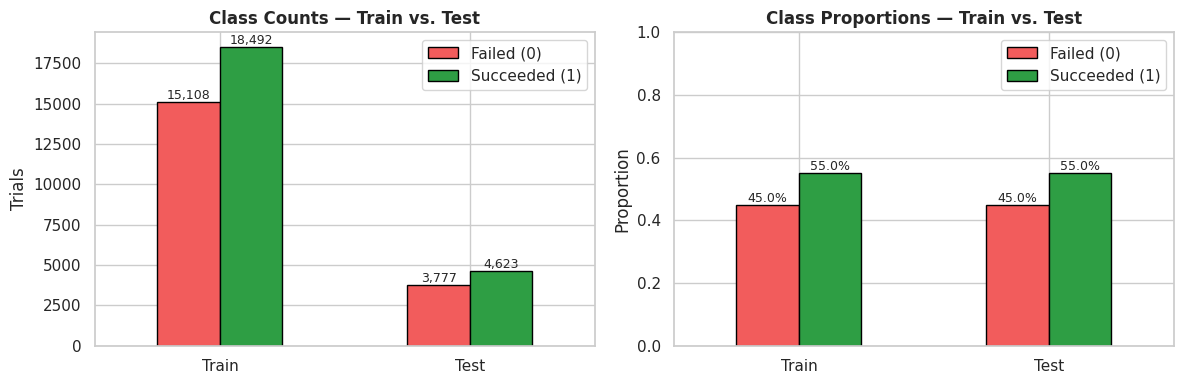

Imbalance ratio (majority/minority): 1.22
Train vs. test success rate: 0.550 vs. 0.550 (stratification preserved the ratio)

Precision benchmark: funding EVERY trial gives precision = 55.0%.
  → A model is only useful if the trials it recommends succeed more often than this.


In [105]:
# =============================================================================
# CLASS BALANCE CHECK — TRAIN vs. TEST, AND THE PRECISION BENCHMARK
# =============================================================================
split_counts = pd.DataFrame({"Train": y_train.value_counts(),
                             "Test":  y_test.value_counts()}).sort_index()
split_counts.index = ["Failed (0)", "Succeeded (1)"]
split_props = split_counts / split_counts.sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, data, title, fmt in [(axes[0], split_counts, "Class Counts", "{:,.0f}"),
                             (axes[1], split_props,  "Class Proportions", "{:.1%}")]:
    data.T.plot.bar(ax=ax, color=[FAIL_COLOR, SUCCESS_COLOR], edgecolor="black", rot=0)
    for container in ax.containers:
        ax.bar_label(container, labels=[fmt.format(v) for v in container.datavalues], fontsize=9)
    ax.set_title(f"{title} — Train vs. Test", fontweight="bold")
axes[0].set_ylabel("Trials")
axes[1].set_ylabel("Proportion"); axes[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

imbalance_ratio = y_train.value_counts().max() / y_train.value_counts().min()
print(f"Imbalance ratio (majority/minority): {imbalance_ratio:.2f}")
print(f"Train vs. test success rate: {y_train.mean():.3f} vs. {y_test.mean():.3f} "
      "(stratification preserved the ratio)")
print(f"\nPrecision benchmark: funding EVERY trial gives precision = {y_test.mean():.1%}.")
print("  → A model is only useful if the trials it recommends succeed more often than this.")

# ── Conditional logic: decide on class weighting from the data ──
CLASS_WEIGHT = profile["class_weight"]

### Split, class balance, and pipeline decisions
*Decisions from Synthetic dataset, seed 973.*
- **Split:** 33,600 training / 8,400 test trials. Success rate is 0.550 in both, so stratification worked. Funding every test trial gives precision of 55.0%.
- **Class imbalance:** ratio 1.22 (limit 1.5) → no class reweighting.
- **Skewed columns:** only `enrollment` exceeds |skew| > 1 → Yeo-Johnson transform. This matches its log-normal design.
- **Missing values:** none → no imputer.
- **Dataset size:** 33,600 training rows exceeds the 20,000-row limit → RandomizedSearchCV and a linear (Platt-calibrated) SVM, with a Nyström approximation for the RBF variant.

---

## Logistic Regression

### Mathematical Foundation

Logistic Regression models the **probability** that an observation belongs to class 1 given its features:

$$
P(y_i = 1 \mid x_i) = \sigma(w^\top x_i + b) = \frac{1}{1 + e^{-(w^\top x_i + b)}}
$$

where:

- $w \in \mathbb{R}^p$ is the weight vector (learned coefficients).
- $b \in \mathbb{R}$ is the bias (intercept).
- $\sigma(\cdot)$ is the **sigmoid (logistic) function**, which maps any real value to $(0, 1)$.
- $w^\top x_i + b$ is the **linear predictor** (log-odds or logit).

The sigmoid function is defined as:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}, \qquad z \in \mathbb{R}
$$

### Log-Odds Interpretation

Taking the logarithm of the odds ratio gives the linear relationship:

$$
\log\left(\frac{P(y=1 \mid x)}{1 - P(y=1 \mid x)}\right) = w^\top x + b
$$

This expression is called the **logit** or **log-odds**. Logistic Regression estimates a linear decision boundary in the log-odds space.

### Loss Function: Binary Cross-Entropy

The model parameters are learned by minimizing the **binary cross-entropy loss** (negative log-likelihood):

$$
\mathcal{L}(w, b) = -\frac{1}{n}\sum_{i=1}^{n}\left[y_i \log \hat{p}_i + (1-y_i)\log(1-\hat{p}_i)\right]
$$

where $\hat{p}_i = P(y_i = 1 \mid x_i)$ is the predicted probability for observation $i$.

### L1 and L2 Regularization

To prevent overfitting, a regularization penalty is added to the loss function:

**L2 Regularization (Ridge):**
$$
\mathcal{L}_{\text{L2}}(w, b) = \mathcal{L}(w, b) + \frac{1}{2C}\|w\|_2^2
$$

**L1 Regularization (Lasso):**
$$
\mathcal{L}_{\text{L1}}(w, b) = \mathcal{L}(w, b) + \frac{1}{C}\|w\|_1
$$

where:

- $\|w\|_2^2 = \sum_{j=1}^p w_j^2$ is the **squared L2 norm** (penalizes large coefficients proportionally).
- $\|w\|_1 = \sum_{j=1}^p |w_j|$ is the **L1 norm** (drives some coefficients exactly to zero — feature selection).
- $C > 0$ is the **inverse regularization strength**: smaller $C$ = stronger regularization.

| Regularization | Effect | Use When |
|---|---|---|
| L2 (Ridge) | Shrinks all coefficients toward zero | Most features are relevant |
| L1 (Lasso) | Sets some coefficients to exactly zero | Feature selection desired |
| ElasticNet | Combination of L1 and L2 | High-dimensional, correlated features |


In [106]:
# ══════════════════════════════════════════════════════════════════
# FEATURE ENGINEERING — LOGISTIC REGRESSION
# ══════════════════════════════════════════════════════════════════

# ── 1. One Hot Encoding ────────────────────────────────────────
# Use for nominal (unordered) categorical variables.
# Here: therapeutic_area, endpoint_type, sponsor_type.
#
# The level order below sets the REFERENCE group (the first level in each
# list is dropped), so odds ratios read as "vs. oncology / hard_survival /
# large_pharma". Because the levels are listed explicitly, the encoder learns
# nothing from the data, so encoding before the split causes no leakage.
# An unexpected level in the data would raise an error instead of passing silently.

from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer
from sklearn.compose import ColumnTransformer

nominal_cols = ["therapeutic_area", "endpoint_type", "sponsor_type"]

level_order = [
    ["oncology", "cardiovascular", "cns", "infectious_disease", "immunology",
     "metabolic", "respiratory", "rare_disease", "vaccine"],      # reference: oncology
    ["hard_survival", "clinical", "surrogate"],                   # reference: hard_survival
    ["large_pharma", "mid_pharma", "small_biotech", "academic"],  # reference: large_pharma
]

if nominal_cols:
    ohe = OneHotEncoder(categories=level_order, sparse_output=False,
                        drop="first")                 # drop='first' avoids dummy variable trap
    ohe_array = ohe.fit_transform(df[nominal_cols])
    ohe_cols  = list(ohe.get_feature_names_out(nominal_cols))
    df_ohe    = pd.DataFrame(ohe_array, columns=ohe_cols, index=df.index)

    # Encode into a COPY so `df` keeps its text categories for the XGBoost pipeline
    # and the statistical tests.
    df_lr = pd.concat([df.drop(columns=nominal_cols), df_ohe], axis=1)

    print(f"One Hot Encoding applied to: {nominal_cols}")
    print(f"New columns created ({len(ohe_cols)}): {ohe_cols}\n")
else:
    ohe_cols = []
    df_lr = df.copy()
    print("No nominal categorical columns specified for One Hot Encoding.\n")

# ── 2. Rebuild the feature matrix and re-use the SAME train/test split ──
lr_feature_cols = numeric_cols + binary_cols + ohe_cols
X_lr = df_lr[lr_feature_cols]

X_train_lr = X_lr.loc[X_train.index]      # same trials as X_train
X_test_lr  = X_lr.loc[X_test.index]       # same trials as X_test

# ── 3. Confirm results ─────────────────────────────────────────
assert len(lr_feature_cols) == 25, f"Expected 25 features, got {len(lr_feature_cols)}"
print(f"Features for logistic regression: {len(lr_feature_cols)} "
      f"({len(numeric_cols)} numeric + {len(binary_cols)} binary + {len(ohe_cols)} one-hot)")
print(f"X_train_lr: {X_train_lr.shape} | X_test_lr: {X_test_lr.shape}")
display(X_train_lr.head())

One Hot Encoding applied to: ['therapeutic_area', 'endpoint_type', 'sponsor_type']
New columns created (13): ['therapeutic_area_cardiovascular', 'therapeutic_area_cns', 'therapeutic_area_infectious_disease', 'therapeutic_area_immunology', 'therapeutic_area_metabolic', 'therapeutic_area_respiratory', 'therapeutic_area_rare_disease', 'therapeutic_area_vaccine', 'endpoint_type_clinical', 'endpoint_type_surrogate', 'sponsor_type_mid_pharma', 'sponsor_type_small_biotech', 'sponsor_type_academic']

Features for logistic regression: 25 (6 numeric + 6 binary + 13 one-hot)
X_train_lr: (33600, 25) | X_test_lr: (8400, 25)


,phase2_effect_size,phase2_pvalue_strength,enrollment,statistical_power,prior_approvals_target,years_in_development,uses_biomarker,novel_mechanism,randomized,double_blind,...,therapeutic_area_immunology,therapeutic_area_metabolic,therapeutic_area_respiratory,therapeutic_area_rare_disease,therapeutic_area_vaccine,endpoint_type_clinical,endpoint_type_surrogate,sponsor_type_mid_pharma,sponsor_type_small_biotech,sponsor_type_academic
23426,7.58,7.90,1544,0.870,1,8.8,0,0,0,1,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
38477,4.55,4.62,260,0.781,1,2.9,0,1,1,1,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
91,7.97,9.28,1905,0.977,0,2.9,0,0,0,1,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
39789,2.80,6.00,456,0.491,4,6.7,0,0,1,1,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
36831,1.85,7.50,416,0.932,0,6.5,0,1,1,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [107]:
# =============================================================================
# SHARED MODEL HELPERS — PREPROCESSORS, FEATURE NAMES, SEARCH SUMMARIES
# =============================================================================
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, cross_validate, cross_val_predict
from sklearn.svm import SVC, LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.kernel_approximation import Nystroem
from sklearn.tree import DecisionTreeClassifier, plot_tree


def make_preprocessor(scale=True):
    """
    scale=True  → margin/distance-based models (SVM): one-hot with a reference level,
                  Yeo-Johnson on skewed enrollment, standardized numeric, binary kept as 0/1.
    scale=False → trees (Decision Tree): all one-hot levels, raw numeric and binary
                  (splits do not depend on scale).
    Explicit category lists → an unexpected level raises an error instead of passing silently.
    """
    if scale:
        return ColumnTransformer([
            ("cat",  OneHotEncoder(categories=level_order, drop="first", sparse_output=False),
                     categorical_cols),
            ("skew", PowerTransformer(method="yeo-johnson", standardize=True), ["enrollment"]),
            ("num",  StandardScaler(), [c for c in numeric_cols if c != "enrollment"]),
            ("bin",  "passthrough", binary_cols),
        ], remainder="drop")
    return ColumnTransformer([
        ("cat", OneHotEncoder(categories=level_order, sparse_output=False), categorical_cols),
        ("num", "passthrough", numeric_cols + binary_cols),
    ], remainder="drop")


def clean_feature_names(pipe):
    """Feature names after preprocessing, without the 'cat__' / 'num__' prefixes."""
    return [n.split("__", 1)[1] for n in pipe.named_steps["pre"].get_feature_names_out()]


def original_feature(name):
    """Map a one-hot column (e.g., 'therapeutic_area_vaccine') back to its source variable."""
    for col in categorical_cols:
        if name.startswith(col + "_"):
            return col
    return name


def search_summary(search, top=5):
    """Top-ranked hyperparameter settings by the PRIMARY metric, with secondary metrics."""
    res = pd.DataFrame(search.cv_results_).sort_values(f"rank_test_{PRIMARY}")
    metrics = [m for m in ["precision_at_k", "average_precision", "roc_auc", "precision", "recall"]
               if f"mean_test_{m}" in res]
    out = res.head(top)[["params"] + [f"mean_test_{m}" for m in metrics] + [f"std_test_{PRIMARY}"]]
    out.columns = ["params"] + [f"CV {m}" for m in metrics] + [f"CV {PRIMARY} SD"]
    out["params"] = out["params"].apply(
        lambda d: {k.split("__")[-1]: (type(v).__name__ if hasattr(v, "fit") else v) for k, v in d.items()})
    print(f"Best CV precision @ top {FUNDING_RATE:.0%}: {search.best_score_:.3f}")
    print(f"Best parameters: {out['params'].iloc[0]}")
    display(out.round(3).reset_index(drop=True))

In [108]:
# =============================================================================
# LOGISTIC REGRESSION — BASELINE MODEL
# =============================================================================
# Categorical variables were already one-hot encoded above (feature engineering
# cell), so this pipeline only handles scaling and transformation:
#
# Pipeline:
#   1. ColumnTransformer
#        • enrollment    → Yeo-Johnson + standardize (right-skewed)
#        • other numeric → standardize
#        • binary 0/1 and one-hot columns → passed through unchanged
#                          (odds ratio = effect of 0 → 1, or vs. reference level)
#   2. LogisticRegression — L2 regularization, NO class weighting
#
# Classes are roughly balanced (~55% success, ratio ≈ 1.2), so
# class_weight='balanced' is not needed. No imputer: no missing values.
# =============================================================================

pre_lr = ColumnTransformer([
    ("skew", PowerTransformer(method="yeo-johnson", standardize=True), ["enrollment"]),
    ("num",  StandardScaler(), [c for c in numeric_cols if c != "enrollment"]),
    ("pass", "passthrough", binary_cols + ohe_cols),
], remainder="drop")

lr_pipeline = Pipeline([
    ("pre", pre_lr),
    ("clf", LogisticRegression(
                penalty="l2",
                C=1.0,
                solver="lbfgs",
                max_iter=1000,
                random_state=RANDOM_STATE
            ))
])

lr_pipeline.fit(X_train_lr, y_train)

print("Logistic Regression — Baseline (L2, C=1.0, no class weighting)")
lr_scores = get_metrics_score(lr_pipeline, X_train_lr, X_test_lr, y_train, y_test)

Logistic Regression — Baseline (L2, C=1.0, no class weighting)
Metric (threshold = 0.50)                Train       Test
Precision                                0.644      0.639  ← primary
Precision @ top 30%                      0.727      0.715  ← primary
Recall                                   0.736      0.744
Specificity                              0.502      0.486
F1-Score                                 0.687      0.688
Accuracy                                 0.631      0.628
AUC-ROC                                  0.674      0.667
Trials funded (predicted go)            21,138      5,379
Failed trials funded (FP)                7,530      1,940


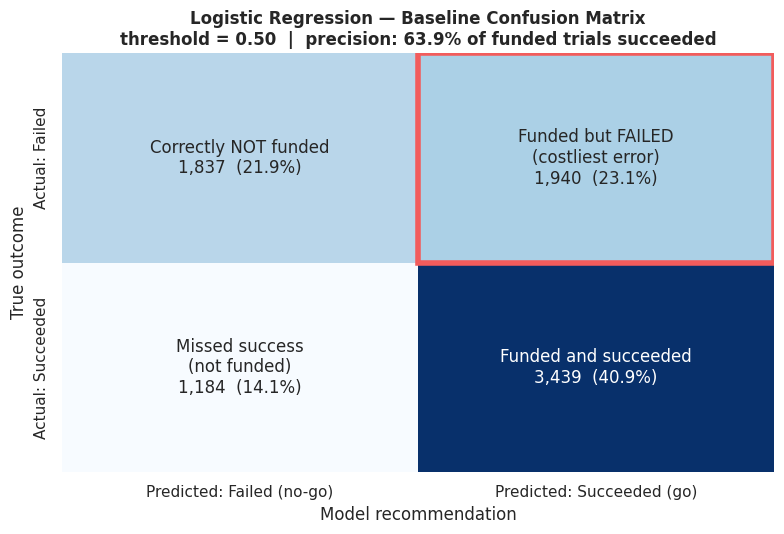

Classification Report:
              precision    recall  f1-score   support

      Failed       0.61      0.49      0.54      3777
   Succeeded       0.64      0.74      0.69      4623

    accuracy                           0.63      8400
   macro avg       0.62      0.62      0.61      8400
weighted avg       0.63      0.63      0.62      8400



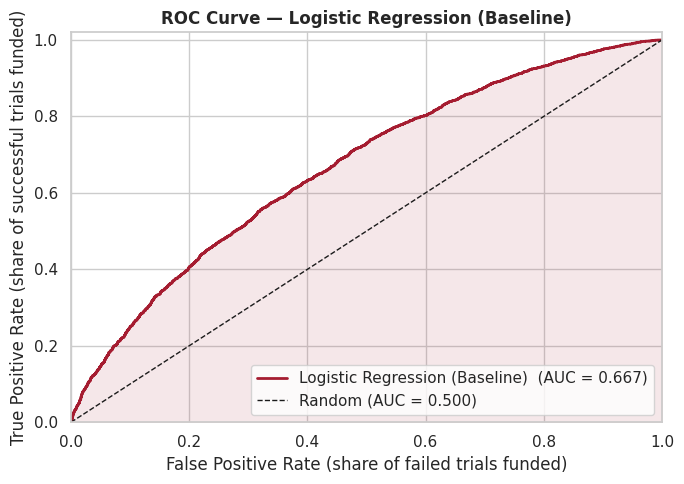

Logistic Regression — Learned Coefficients


,Feature,Coefficient (log-odds),Odds Ratio
19,therapeutic_area_vaccine,0.7856,2.1938
14,therapeutic_area_infectious_disease,0.6827,1.9793
16,therapeutic_area_metabolic,0.5619,1.7540
21,endpoint_type_surrogate,0.5540,1.7401
12,therapeutic_area_cardiovascular,0.4641,1.5905
15,therapeutic_area_immunology,0.4465,1.5628
24,sponsor_type_academic,-0.4450,0.6408
17,therapeutic_area_respiratory,0.4017,1.4944
1,phase2_effect_size,0.3409,1.4061
20,endpoint_type_clinical,0.3407,1.4059


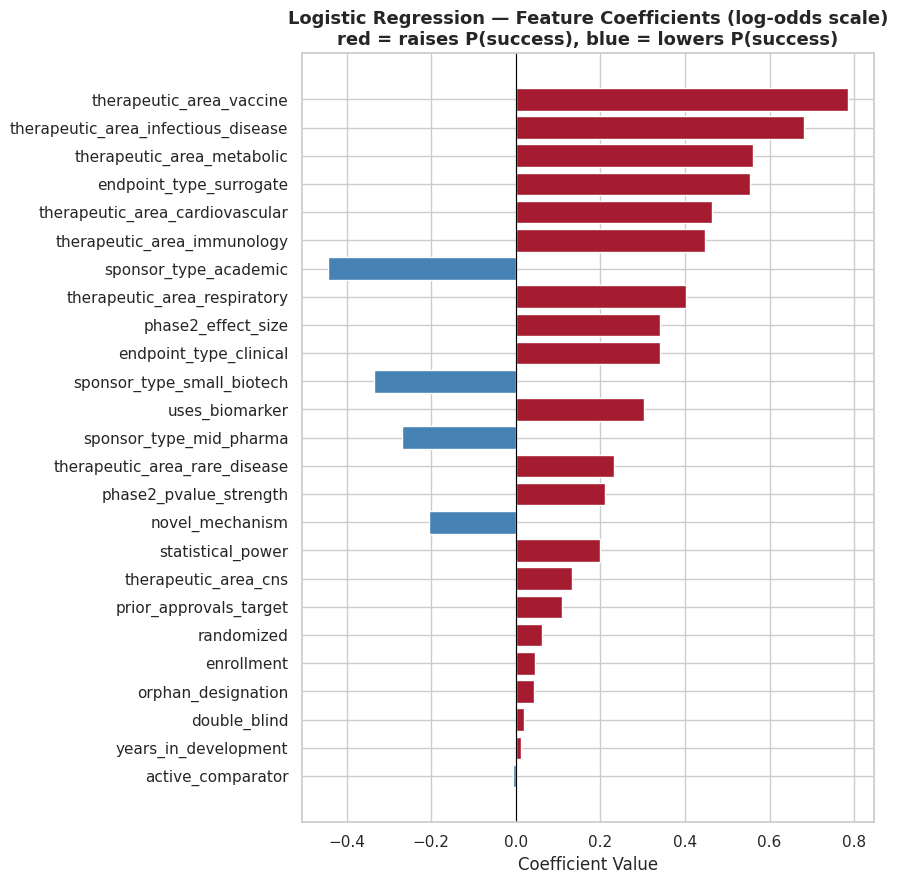

In [109]:
# =============================================================================
# LOGISTIC REGRESSION — CONFUSION MATRIX AND ROC CURVE
# =============================================================================
make_confusion_matrix(lr_pipeline, X_test_lr, y_test,
                      title="Logistic Regression — Baseline Confusion Matrix")

lr_auc = plot_roc_curve(lr_pipeline, X_test_lr, y_test,
                        model_name="Logistic Regression (Baseline)")

# =============================================================================
# LOGISTIC REGRESSION — COEFFICIENT / ODDS RATIO INTERPRETATION
# =============================================================================
# Feature names now come from the preprocessor (one-hot adds columns, so
# X_train.columns no longer matches the coefficients).
#
# How to read the odds ratios:
#   • Numeric features   → change in odds per 1 standard deviation increase
#   • Binary features    → odds when the feature = 1 vs. 0
#   • Categorical dummies → odds vs. the reference level
#                           (oncology / hard_survival / large_pharma)
# =============================================================================
lr_model = lr_pipeline.named_steps["clf"]
feature_names = [n.split("__", 1)[1]
                 for n in lr_pipeline.named_steps["pre"].get_feature_names_out()]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient (log-odds)": lr_model.coef_[0],
    "Odds Ratio": np.exp(lr_model.coef_[0])
}).sort_values("Coefficient (log-odds)", key=abs, ascending=False)

print("Logistic Regression — Learned Coefficients")
display(coef_df.round(4))

fig, ax = plt.subplots(figsize=(9, 9))
plot_df_coef = coef_df.iloc[::-1]          # largest effect at the top
colors = ["#A51C30" if c > 0 else "steelblue" for c in plot_df_coef["Coefficient (log-odds)"]]
ax.barh(plot_df_coef["Feature"], plot_df_coef["Coefficient (log-odds)"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Logistic Regression — Feature Coefficients (log-odds scale)\n"
             "red = raises P(success), blue = lowers P(success)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Coefficient Value")
plt.tight_layout()
plt.show()

,Odds Ratio,95% CI lower,95% CI upper,p-value,Significant (CI excludes 1)
sponsor_type_academic,0.64,0.59,0.69,< 0.0001,✓
sponsor_type_small_biotech,0.71,0.68,0.76,< 0.0001,✓
sponsor_type_mid_pharma,0.76,0.72,0.81,< 0.0001,✓
novel_mechanism,0.81,0.78,0.85,< 0.0001,✓
active_comparator,0.99,0.95,1.04,0.7457,
years_in_development,1.01,0.99,1.03,0.3148,
double_blind,1.02,0.97,1.07,0.4575,
orphan_designation,1.04,0.98,1.11,0.1493,
enrollment,1.05,1.02,1.07,0.0001,✓
randomized,1.07,1.00,1.15,0.0610,


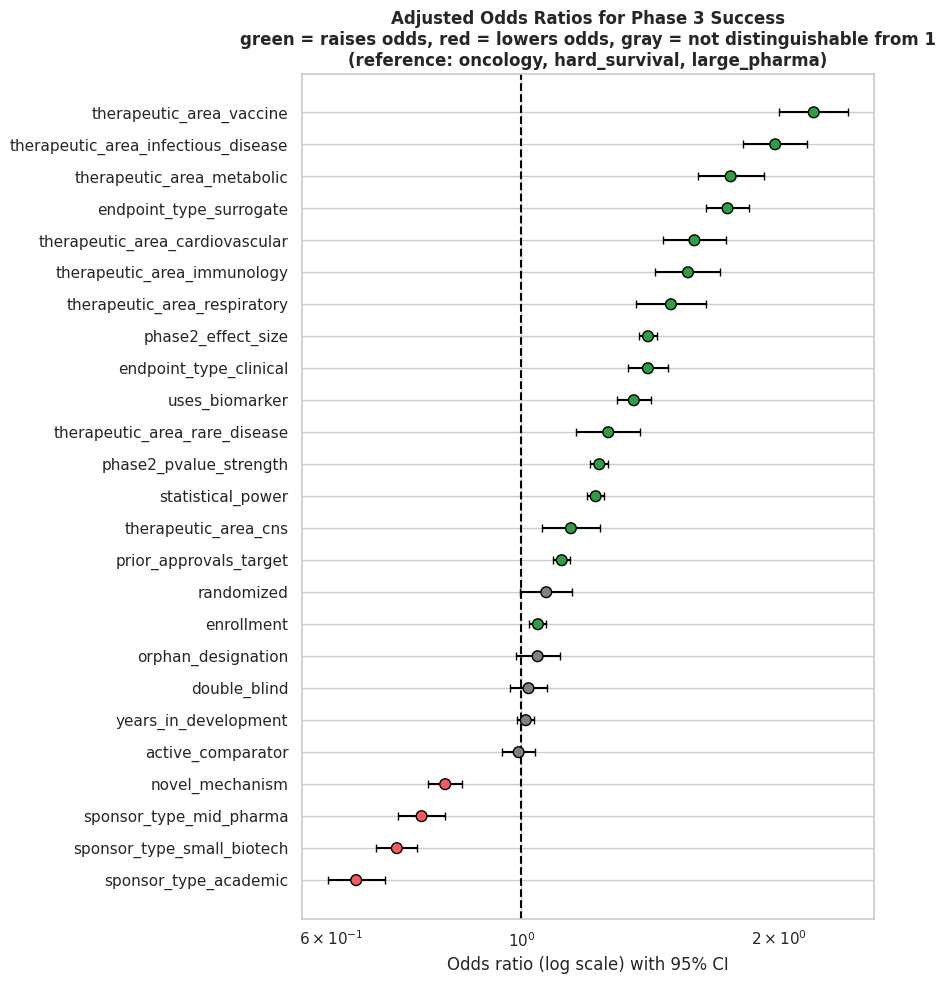

In [110]:
# =============================================================================
# ODDS RATIOS WITH 95% CONFIDENCE INTERVALS (statsmodels Logit)
# =============================================================================
X_design = pd.DataFrame(lr_pipeline.named_steps["pre"].transform(X_train_lr),
                        columns=feature_names, index=X_train_lr.index)
logit_res = sm.Logit(y_train, sm.add_constant(X_design)).fit(disp=False)

ci_ = logit_res.conf_int()
or_tbl = (pd.DataFrame({"Odds Ratio":   np.exp(logit_res.params),
                        "95% CI lower": np.exp(ci_[0]),
                        "95% CI upper": np.exp(ci_[1]),
                        "p-value":      logit_res.pvalues})
            .drop("const").sort_values("Odds Ratio"))
or_tbl["Significant (CI excludes 1)"] = np.where(
    (or_tbl["95% CI lower"] > 1) | (or_tbl["95% CI upper"] < 1), "✓", "")
display(or_tbl.style.format({"Odds Ratio": "{:.2f}", "95% CI lower": "{:.2f}",
                             "95% CI upper": "{:.2f}", "p-value": fmt_p}))

fig, ax = plt.subplots(figsize=(9, 10))
ypos = np.arange(len(or_tbl))
col = [SUCCESS_COLOR if l > 1 else FAIL_COLOR if u < 1 else "gray"
       for l, u in zip(or_tbl["95% CI lower"], or_tbl["95% CI upper"])]
ax.errorbar(or_tbl["Odds Ratio"], ypos,
            xerr=[or_tbl["Odds Ratio"] - or_tbl["95% CI lower"],
                  or_tbl["95% CI upper"] - or_tbl["Odds Ratio"]],
            fmt="none", ecolor="black", capsize=3)
ax.scatter(or_tbl["Odds Ratio"], ypos, c=col, s=60, zorder=3, edgecolor="black")
ax.axvline(1, color="black", ls="--")
ax.set_xscale("log")
ax.set_yticks(ypos); ax.set_yticklabels(or_tbl.index)
ax.set_xlabel("Odds ratio (log scale) with 95% CI")
ax.set_title("Adjusted Odds Ratios for Phase 3 Success\n"
             "green = raises odds, red = lowers odds, gray = not distinguishable from 1\n"
             "(reference: oncology, hard_survival, large_pharma)", fontweight="bold")
plt.tight_layout(); plt.show()

### Interpretion of Logistic Regression Results
*Interpretation from Synthetic dataset, seed 973.*

**Key Result:** the model predicts Phase 3 success better than chance, but only modestly. Use it as a **risk-adjustment input**, not an automatic decision rule.

#### Performance on 8,400 unseen trials (baseline model, threshold 0.50)
| Metric | Value | Meaning for a sponsor |
|---|---|---|
| Accuracy | 62.8% | vs. 55.0% from always predicting "success" |
| AUC-ROC | 0.667 | Ranks a successful trial above a failed one 67% of the time |
| Precision | 0.639 | Of trials rated "likely success", 64% succeeded (vs. 55% overall) |
| Recall | 0.744 | Of trials that succeeded, 74% were rated "likely success" |
| Specificity | 0.486 | Only 49% of failed trials were rated "at risk" |
| Precision @ top 30% | 0.715 | The primary metric: the success rate among the 30% of trials ranked highest |

- **Training and test scores are close** (AUC 0.674 vs. 0.667; precision@30% 0.727 vs. 0.715), so the model is not overfitting.
- **At the default 0.50 cut-off, the model leans optimistic.** It funds 5,379 trials (64%), including **1,940 of the 3,777 that failed** (51%). A sponsor who wants more confidence in "go" calls can raise the cut-off (see [*Choosing the Funding Threshold*](#scrollTo=_UxPLw2PX05B&line=2&uniqifier=1)).

#### What drives success (adjusted for all other factors)
- **Categories** are compared with a reference group: oncology, hard-survival endpoints, and large pharma.
- **Numeric features** show the change per 1 SD increase. For enrollment, this is per SD of the *transformed* value.
- **Yes/no features** compare "yes" with "no". OR > 1 raises the odds of success, and OR < 1 lowers them.

| Factor | Effect (odds ratio) |
|---|---|
| **Therapeutic area** (vs. oncology) | Every area outperforms oncology: vaccine 2.19, infectious disease 1.98, metabolic 1.75, cardiovascular 1.59, immunology 1.56, respiratory 1.49, rare disease 1.26, CNS 1.14 |
| **Endpoint type** (vs. hard survival) | Surrogate 1.74, clinical 1.41 |
| **Sponsor type** (vs. large pharma) | Mid pharma 0.76, small biotech 0.72, academic 0.64 |
| **Biomarker-guided selection** | 1.35 |
| **Novel mechanism** | 0.81 (first-in-class programs are riskier) |
| **Phase 2 evidence** (per SD) | Effect size 1.41, p-value strength 1.23, statistical power 1.22 |
| **Prior approvals** (per SD) | 1.11 |
| **Little or no effect** | Randomized 1.06, enrollment 1.05, orphan designation 1.04, double-blind 1.02, years in development 1.01, active comparator 0.99 |

#### Did the model recover the planted effects?
A synthetic dataset lets us check the model against known truth. Planted odds ratios come from the generator's coefficients.

| Factor | Planted OR | Estimated OR |
|---|---|---|
| Vaccine / infectious / metabolic vs. oncology | 2.12 / 1.97 / 1.79 | 2.19 / 1.98 / 1.75 |
| Cardiovascular / immunology / respiratory | 1.57 / 1.49 / 1.46 | 1.59 / 1.56 / 1.49 |
| Rare disease / CNS | 1.25 / 1.11 | 1.26 / 1.14 |
| Surrogate / clinical vs. hard survival | 1.79 / 1.35 | 1.74 / 1.41 |
| Mid / small / academic vs. large pharma | 0.80 / 0.67 / 0.62 | 0.76 / 0.72 / 0.64 |
| Biomarker / novel mechanism | 1.35 / 0.82 | 1.35 / 0.81 |
| Effect size / p-value strength / power (per SD) | 1.39 / 1.25 / 1.22 | 1.41 / 1.23 / 1.22 |
| Prior approvals (per SD) | 1.12 | 1.11 |
| Years in development | 1.00 | 1.01 |

All 25 estimates are within about 0.07 log-odds of the planted values, so logistic regression recovers the truth closely. This is expected because the generator is an additive logistic model. `enrollment` is the one place the estimate (OR 1.05) sits visibly above the planted effect (about 1.01); check its confidence interval in the odds-ratio table. A real analysis cannot do this check, because the truth is unknown.

#### Cautions
- **Don't compare categorical and numeric ORs head-to-head.** They are on different scales (per category vs. per SD).
- **These are associations, not causes.** Sponsor and therapeutic area cannot be changed, and switching endpoints does not guarantee the associated improvement.
- **Uncertainty:** confidence intervals and p-values appear in the [*Odds Ratios with 95% Confidence Intervals*](#scrollTo=PQGS4BWRRI_v&line=2&uniqifier=1) cell.

In [111]:
# =============================================================================
# LOGISTIC REGRESSION — HYPERPARAMETER TUNING (GridSearchCV)
# =============================================================================
#   C        — inverse regularization strength (smaller = stronger shrinkage)
#   penalty  — 'l2' shrinks all coefficients; 'l1' can set weak ones to exactly 0
#   solver   — liblinear supports both penalties
# Scoring: all metrics are recorded; parameters are chosen by precision among the
# top-ranked trials (refit=PRIMARY). The template's 'recall' would favour funding
# MORE trials, which is the opposite of the sponsor's goal.
# LR uses the pre-encoded matrix (X_train_lr) built in the feature-engineering cell.
# =============================================================================
lr_param_grid = {
    "clf__C":       [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
    "clf__penalty": ["l1", "l2"],
    "clf__solver":  ["liblinear"],
}

lr_grid = GridSearchCV(lr_pipeline, lr_param_grid, scoring=SCORING, refit=PRIMARY,
                       cv=cv, n_jobs=-1)
lr_grid.fit(X_train_lr, y_train)
search_summary(lr_grid)
lr_tuned = lr_grid.best_estimator_

Best CV precision @ top 30%: 0.725
Best parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}


,params,CV precision_at_k,CV average_precision,CV roc_auc,CV precision,CV recall,CV precision_at_k SD
0,"{'C': 0.1, 'penalty': 'l2', 'solver': 'libline...",0.725,0.704,0.673,0.642,0.736,0.012
1,"{'C': 1.0, 'penalty': 'l1', 'solver': 'libline...",0.725,0.704,0.673,0.643,0.735,0.012
2,"{'C': 10.0, 'penalty': 'l1', 'solver': 'liblin...",0.725,0.704,0.673,0.643,0.735,0.012
3,"{'C': 1.0, 'penalty': 'l2', 'solver': 'libline...",0.725,0.704,0.673,0.643,0.735,0.012
4,"{'C': 100.0, 'penalty': 'l1', 'solver': 'libli...",0.725,0.704,0.673,0.643,0.734,0.012


Logistic Regression — Tuned Model
Metric (threshold = 0.50)                Train       Test
Precision                                0.643      0.639  ← primary
Precision @ top 30%                      0.726      0.716  ← primary
Recall                                   0.737      0.743
Specificity                              0.500      0.487
F1-Score                                 0.687      0.687
Accuracy                                 0.630      0.628
AUC-ROC                                  0.674      0.667
Trials funded (predicted go)            21,186      5,372
Failed trials funded (FP)                7,557      1,938


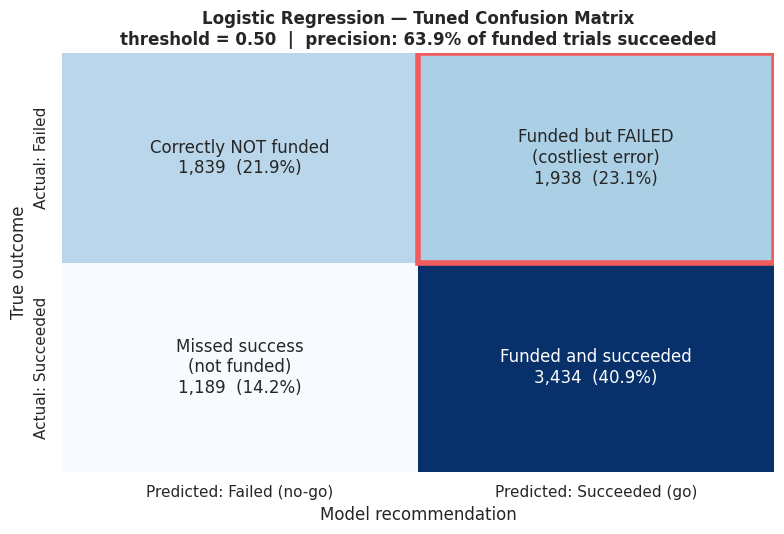

Classification Report:
              precision    recall  f1-score   support

      Failed       0.61      0.49      0.54      3777
   Succeeded       0.64      0.74      0.69      4623

    accuracy                           0.63      8400
   macro avg       0.62      0.61      0.61      8400
weighted avg       0.62      0.63      0.62      8400



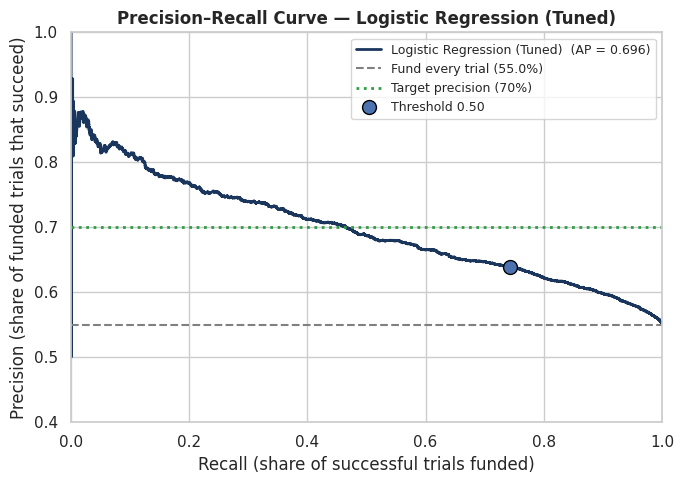

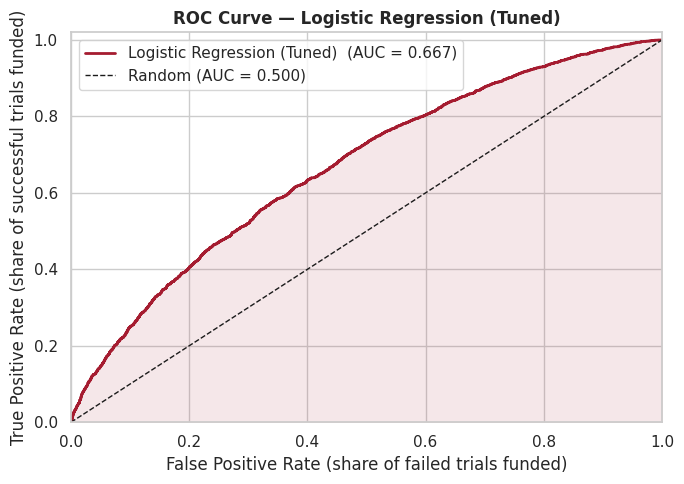

Features removed by the penalty: none


In [112]:
# =============================================================================
# LOGISTIC REGRESSION — TUNED MODEL EVALUATION
# =============================================================================
print("Logistic Regression — Tuned Model")
lr_tuned_scores = get_metrics_score(lr_tuned, X_train_lr, X_test_lr, y_train, y_test)

make_confusion_matrix(lr_tuned, X_test_lr, y_test,
                      title="Logistic Regression — Tuned Confusion Matrix")
lr_tuned_ap  = plot_pr_curve(lr_tuned, X_test_lr, y_test, model_name="Logistic Regression (Tuned)")
lr_tuned_auc = plot_roc_curve(lr_tuned, X_test_lr, y_test, model_name="Logistic Regression (Tuned)")

# With an L1 penalty, some coefficients may be exactly 0 (feature dropped)
coefs = pd.Series(lr_tuned.named_steps["clf"].coef_[0], index=clean_feature_names(lr_tuned))
dropped = coefs[coefs.abs() < 1e-8].index.tolist()
print(f"Features removed by the penalty: {dropped or 'none'}")

### Interpretation of Tuned Logistic Regression Results

*Interpretation of Synthetic dataset, seed 973.*

- The best setting was an L2 penalty with C = 0.1.
- The top five settings all score a cross-validated precision@30% of **0.725** (SD 0.012), so the choice among them is not meaningful.
- Test performance is the same as the baseline (precision@30% 0.716 vs. 0.715; AUC 0.667 for both; precision 0.639 for both).
- With 33,600 trials and only 25 features, regularization has little to restrain, as expected.
- The baseline's odds ratios therefore remain valid. "Features removed by the penalty: none" is expected because the selected model is L2, which shrinks coefficients, but never sets them to exactly zero.

---
## Support Vector Machine (SVM)

### Mathematical Foundation
An SVM finds the boundary that separates successful from failed trials with the **widest possible margin**. With labels recoded as $y_i\in\{-1,+1\}$, the soft-margin SVM solves

$$
\min_{w,\,b}\;\frac{1}{2}\lVert w\rVert^2 + C\sum_{i=1}^{n}\max\!\big(0,\;1-y_i(w^\top x_i+b)\big)
$$

- $\frac12\lVert w\rVert^2$ rewards a wide margin (a simpler, more stable boundary).
- The **hinge loss** $\max(0, 1-y_i f(x_i))$ penalizes trials on the wrong side of, or inside, the margin.
- $C$ sets the trade-off. A large $C$ fits the training data closely (overfitting risk); a small $C$ gives a smoother boundary.

**Kernels** allow curved boundaries by measuring similarity between trials. The radial basis function (RBF) kernel is

$$
K(x,x')=\exp\!\big(-\gamma\lVert x-x'\rVert^2\big)
$$

where $\gamma$ controls how local the boundary is. Because the kernel uses distances, **all features must be standardized**, otherwise enrollment (in hundreds) would swamp a 0–1 power value.

### From scores to probabilities (needed for precision)
An SVM outputs a distance from the boundary, $f(x)$, not a probability. To set a threshold that achieves a target precision, the scores are converted with **Platt scaling**:

$$
\widehat{P}(\text{success}\mid x)=\frac{1}{1+\exp\big(A\,f(x)+B\big)}
$$

$A$ and $B$ are fitted on held-out folds (`CalibratedClassifierCV`).

### Adapting to dataset size (conditional logic)
An exact kernel SVM needs time and memory that grow roughly with the **square** of the number of trials. That is fine for a few thousand rows but impractical for 33,600, especially with probability calibration. The pipeline therefore adapts:

| Training rows | Linear SVM | Kernel (RBF) SVM |
|---|---|---|
| ≤ `LARGE_DATA_ROWS` (20,000) | Exact `SVC(kernel='linear')` | Exact `SVC(kernel='rbf')` |
| > 20,000 (**this dataset**) | `LinearSVC` + Platt calibration | **Nyström approximation**: the RBF kernel is approximated from $m=500$ landmark trials, $K\approx K_{nm}K_{mm}^{+}K_{mn}$, then a linear SVM is fitted. Cost grows linearly with $n$ instead of quadratically |

Both a linear and an RBF-kernel SVM are evaluated in either case. Tuning decides which works better.

In [113]:
# =============================================================================
# SUPPORT VECTOR MACHINE — BASELINE MODEL
# =============================================================================
# Pipeline: adaptive preprocessor (one-hot + Yeo-Johnson + standardize; required
# for SVM, which is distance-based) → optional kernel map → SVM.
# Conditional logic: exact SVC on small data, calibrated LinearSVC on large data.
# The "kernel" step is a placeholder here; tuning can swap in an RBF approximation.
# =============================================================================
LARGE_DATA = len(X_train) > LARGE_DATA_ROWS

if LARGE_DATA:
    svm_kind = "Linear SVM, Platt-calibrated"
    svm_clf = CalibratedClassifierCV(
        estimator=LinearSVC(C=1.0, dual=False, class_weight=CLASS_WEIGHT, max_iter=5000),
        method="sigmoid", cv=3)
else:
    svm_kind = "RBF SVM"
    svm_clf = SVC(kernel="rbf", C=1.0, gamma="scale", class_weight=CLASS_WEIGHT,
                  probability=True, random_state=RANDOM_STATE)

print(f"{len(X_train):,} training rows → {'large' if LARGE_DATA else 'small'}-data branch: {svm_kind}")

svm_pipeline = Pipeline([
    ("pre",    make_preprocessor(scale=True)),
    ("kernel", "passthrough"),
    ("clf",    svm_clf),
])
svm_pipeline.fit(X_train, y_train)

print(f"\nSupport Vector Machine — Baseline ({svm_kind}, C=1.0)")
svm_scores = get_metrics_score(svm_pipeline, X_train, X_test, y_train, y_test)

33,600 training rows → large-data branch: Linear SVM, Platt-calibrated

Support Vector Machine — Baseline (Linear SVM, Platt-calibrated, C=1.0)
Metric (threshold = 0.50)                Train       Test
Precision                                0.644      0.639  ← primary
Precision @ top 30%                      0.727      0.715  ← primary
Recall                                   0.737      0.746
Specificity                              0.501      0.485
F1-Score                                 0.687      0.689
Accuracy                                 0.631      0.629
AUC-ROC                                  0.674      0.667
Trials funded (predicted go)            21,173      5,395
Failed trials funded (FP)                7,546      1,946


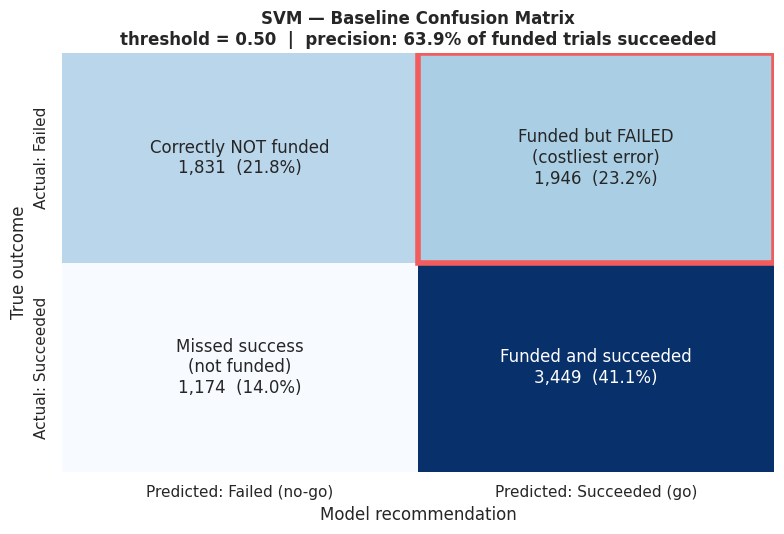

Classification Report:
              precision    recall  f1-score   support

      Failed       0.61      0.48      0.54      3777
   Succeeded       0.64      0.75      0.69      4623

    accuracy                           0.63      8400
   macro avg       0.62      0.62      0.61      8400
weighted avg       0.63      0.63      0.62      8400



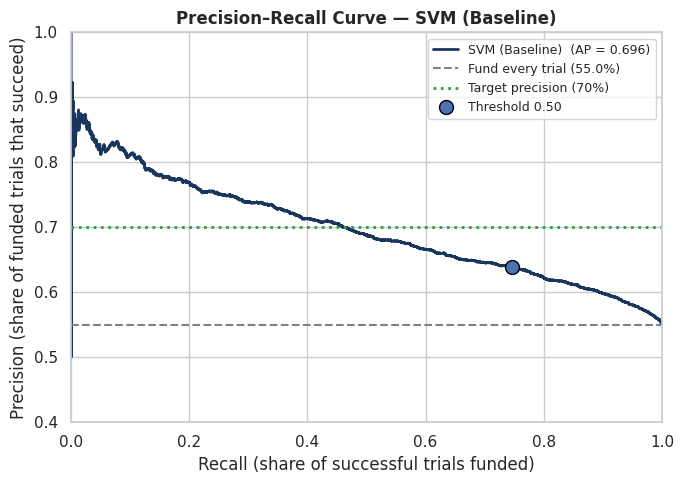

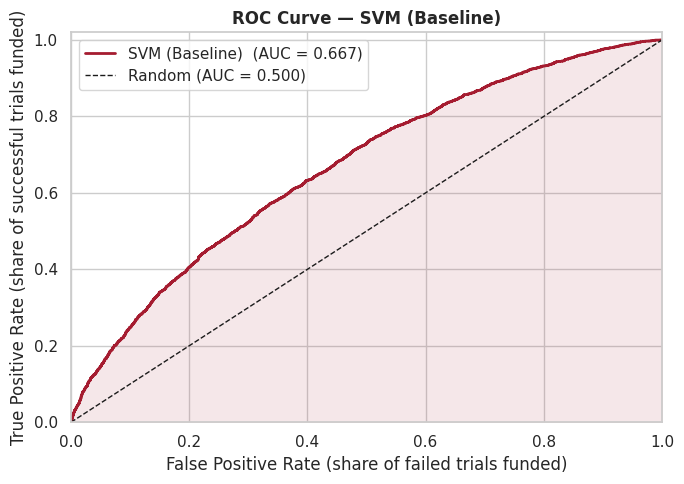

In [114]:
# =============================================================================
# SVM — CONFUSION MATRIX, PRECISION–RECALL AND ROC CURVES
# =============================================================================
make_confusion_matrix(svm_pipeline, X_test, y_test, title="SVM — Baseline Confusion Matrix")
svm_ap  = plot_pr_curve(svm_pipeline, X_test, y_test, model_name="SVM (Baseline)")
svm_auc = plot_roc_curve(svm_pipeline, X_test, y_test, model_name="SVM (Baseline)")

In [115]:
# =============================================================================
# SVM — HYPERPARAMETER TUNING (GridSearchCV, precision-focused)
# =============================================================================
#   C      — margin softness (smaller = smoother boundary, more regularization)
#   kernel — linear vs. RBF (exact on small data, Nyström approximation on large)
#   gamma  — RBF width (larger = more local, wigglier boundary)
# Large-data grid: 5 linear + 9 RBF settings × 5 folds = 70 fits (minutes, not hours).
# =============================================================================
if LARGE_DATA:
    svm_param_grid = [
        {"kernel": ["passthrough"],                                   # linear SVM
         "clf__estimator__C": [0.001, 0.01, 0.1, 1.0, 10.0]},
        {"kernel": [Nystroem(kernel="rbf", n_components=500,           # approximate RBF SVM
                             random_state=RANDOM_STATE)],
         "kernel__gamma": [0.01, 0.03, 0.1],
         "clf__estimator__C": [0.01, 0.1, 1.0]},
    ]
else:
    svm_param_grid = {"clf__C":      [0.1, 1.0, 10.0, 100.0],
                      "clf__kernel": ["rbf", "linear"],
                      "clf__gamma":  ["scale", "auto", 0.001, 0.01]}

svm_grid = GridSearchCV(svm_pipeline, svm_param_grid, scoring=SCORING, refit=PRIMARY,
                        cv=cv, n_jobs=-1, error_score="raise")
svm_grid.fit(X_train, y_train)
search_summary(svm_grid)
svm_tuned = svm_grid.best_estimator_

Best CV precision @ top 30%: 0.725
Best parameters: {'C': 10.0, 'kernel': 'passthrough'}


,params,CV precision_at_k,CV average_precision,CV roc_auc,CV precision,CV recall,CV precision_at_k SD
0,"{'C': 10.0, 'kernel': 'passthrough'}",0.725,0.704,0.673,0.642,0.736,0.012
1,"{'C': 0.01, 'kernel': 'passthrough'}",0.725,0.704,0.673,0.642,0.736,0.012
2,"{'C': 1.0, 'kernel': 'passthrough'}",0.725,0.704,0.673,0.643,0.737,0.012
3,"{'C': 0.1, 'kernel': 'passthrough'}",0.725,0.704,0.673,0.642,0.736,0.012
4,"{'C': 0.1, 'kernel': 'Nystroem', 'gamma': 0.01}",0.724,0.702,0.671,0.642,0.740,0.013


Support Vector Machine — Tuned Model
Metric (threshold = 0.50)                Train       Test
Precision                                0.644      0.639  ← primary
Precision @ top 30%                      0.727      0.715  ← primary
Recall                                   0.737      0.746
Specificity                              0.501      0.485
F1-Score                                 0.687      0.689
Accuracy                                 0.631      0.629
AUC-ROC                                  0.674      0.667
Trials funded (predicted go)            21,169      5,395
Failed trials funded (FP)                7,544      1,946


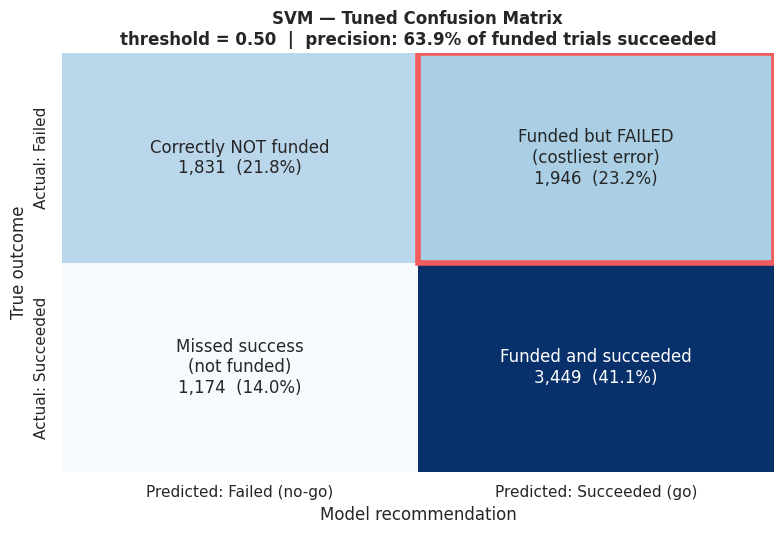

Classification Report:
              precision    recall  f1-score   support

      Failed       0.61      0.48      0.54      3777
   Succeeded       0.64      0.75      0.69      4623

    accuracy                           0.63      8400
   macro avg       0.62      0.62      0.61      8400
weighted avg       0.63      0.63      0.62      8400



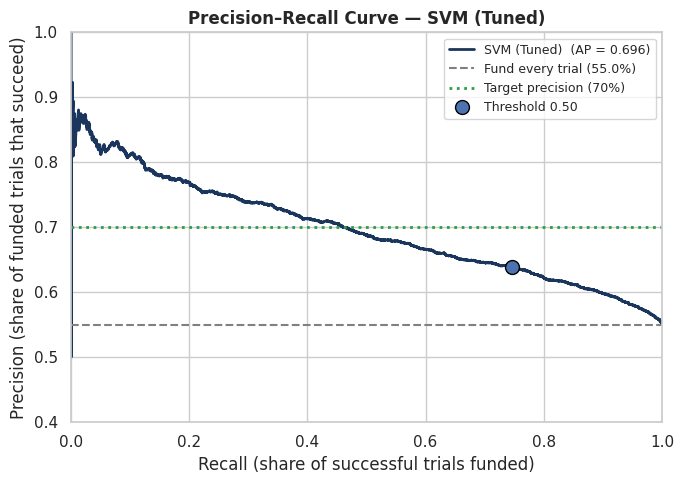

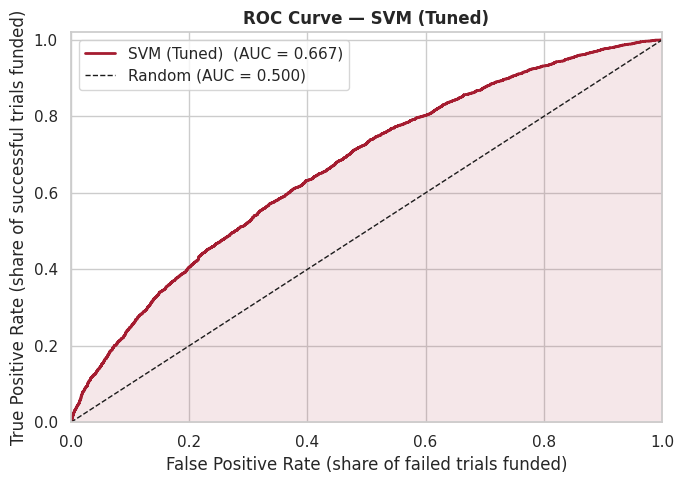

In [116]:
# =============================================================================
# SVM — TUNED MODEL EVALUATION
# =============================================================================
print("Support Vector Machine — Tuned Model")
svm_tuned_scores = get_metrics_score(svm_tuned, X_train, X_test, y_train, y_test)

make_confusion_matrix(svm_tuned, X_test, y_test, title="SVM — Tuned Confusion Matrix")
svm_tuned_ap  = plot_pr_curve(svm_tuned, X_test, y_test, model_name="SVM (Tuned)")
svm_tuned_auc = plot_roc_curve(svm_tuned, X_test, y_test, model_name="SVM (Tuned)")

### Interpretation of SVM Results
*Interpretation from Synthetic dataset, seed 973.*

- **Linear vs. RBF:** The search chose the **linear** kernel (CV precision@30% = 0.725). All five linear settings (C from 0.01 to 10) tie, and the best Nyström-RBF setting was 0.724. The boundary between successful and failed trials is essentially straight, which matches the logistic-regression and XGBoost results.
- **Agreement with logistic regression:** Test precision@30% is 0.715 for the SVM vs. 0.716 for LR. Test AUC is 0.667 for both, precision is 0.639 for both, and the SVM funds 1,946 failed trials vs. 1,938 for LR.
- **Overfitting:** The train-test gap in precision@30% is 0.012, well under 0.02. The model generalizes.
- **What it means for sponsors:** The SVM adds no precision, gives no odds ratios, and needed calibration to produce probabilities. It also took about 7 minutes to tune. It does not justify replacing logistic regression.

---
## Decision Tree

### Mathematical Foundation
A decision tree repeatedly splits trials into two groups using one feature at a time (for example, "phase2_effect_size ≤ 4.8"), choosing the split that makes the groups as **pure** as possible. Impurity of a node with success proportion $p$ is measured by

$$
\text{Gini}=1-\sum_{k\in\{0,1\}}p_k^2 = 2p(1-p),
\qquad
\text{Entropy}=-\sum_{k\in\{0,1\}}p_k\log_2 p_k
$$

A split is chosen to maximize the **impurity decrease**

$$
\Delta I = I(\text{parent})-\frac{n_L}{n}\,I(\text{left})-\frac{n_R}{n}\,I(\text{right})
$$

**Link to precision.** Each final group (leaf) predicts the **success rate of the training trials in it**. If a sponsor funded only the trials falling in a leaf, that leaf's success rate *is* the precision. A tree therefore produces a ranked set of **trial profiles** with an expected success rate attached to each, which is easy to communicate.

**Controlling complexity.** An unconstrained tree keeps splitting until every leaf is pure. It memorizes the training data and its leaf "precisions" collapse on new trials. Complexity is limited by `max_depth` and `min_samples_leaf` (each leaf must contain enough trials for its success rate to be trustworthy), and by cost-complexity pruning:

$$
R_\alpha(T)=R(T)+\alpha\,\lvert T\rvert
$$

where $R(T)$ is the tree's error, $\lvert T\rvert$ is the number of leaves, and $\alpha$ (`ccp_alpha`) is the penalty per leaf.

Trees need no scaling, and they keep all one-hot levels (no reference group).

In [117]:
# =============================================================================
# DECISION TREE — BASELINE MODEL (unconstrained depth)
# =============================================================================
# Deliberately unconstrained to show the overfitting problem: expect near-perfect
# training scores and much weaker test scores. Trees need no scaling; the tree
# preprocessor keeps all one-hot levels and raw numeric values.
# =============================================================================
dt_pipeline = Pipeline([
    ("pre", make_preprocessor(scale=False)),
    ("clf", DecisionTreeClassifier(criterion="gini", class_weight=CLASS_WEIGHT,
                                   random_state=RANDOM_STATE)),
])
dt_pipeline.fit(X_train, y_train)

tree_ = dt_pipeline.named_steps["clf"]
print(f"Decision Tree — Baseline (Gini, unconstrained): depth = {tree_.get_depth()}, "
      f"leaves = {tree_.get_n_leaves():,}")
dt_scores = get_metrics_score(dt_pipeline, X_train, X_test, y_train, y_test)

Decision Tree — Baseline (Gini, unconstrained): depth = 35, leaves = 8,119
Metric (threshold = 0.50)                Train       Test
Precision                                1.000      0.584  ← primary
Precision @ top 30%                      1.000      0.573  ← primary
Recall                                   1.000      0.570
Specificity                              1.000      0.503
F1-Score                                 1.000      0.577
Accuracy                                 1.000      0.540
AUC-ROC                                  1.000      0.536
Trials funded (predicted go)            18,492      4,516
Failed trials funded (FP)                    0      1,879


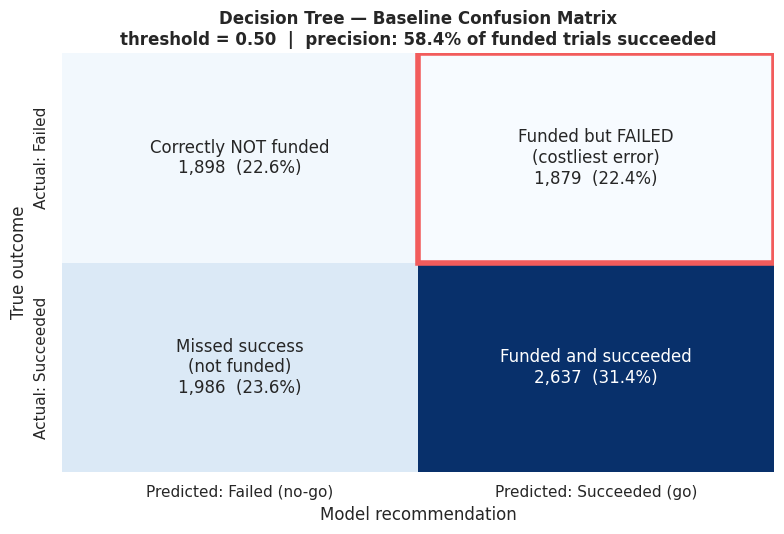

Classification Report:
              precision    recall  f1-score   support

      Failed       0.49      0.50      0.50      3777
   Succeeded       0.58      0.57      0.58      4623

    accuracy                           0.54      8400
   macro avg       0.54      0.54      0.54      8400
weighted avg       0.54      0.54      0.54      8400



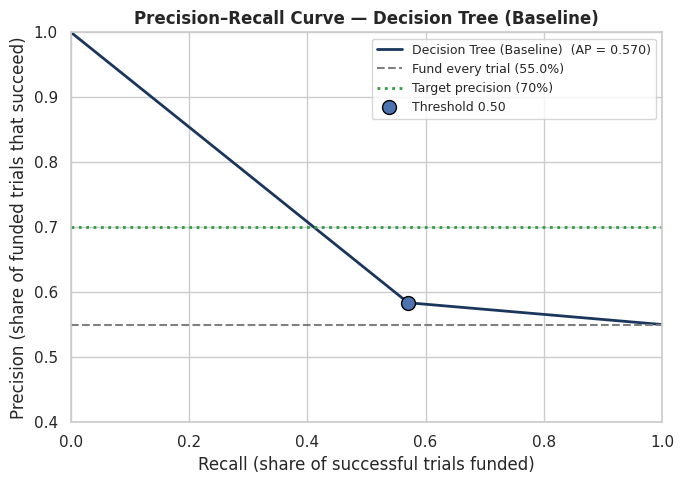

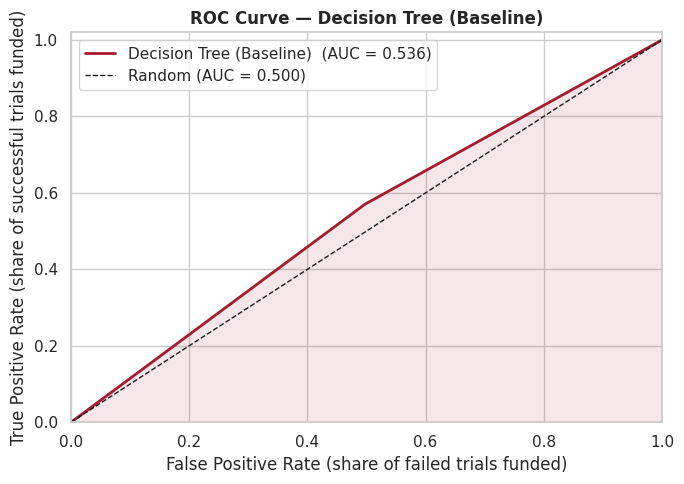

In [118]:
# =============================================================================
# DECISION TREE — CONFUSION MATRIX, PRECISION–RECALL AND ROC CURVES
# =============================================================================
make_confusion_matrix(dt_pipeline, X_test, y_test,
                      title="Decision Tree — Baseline Confusion Matrix")
dt_ap  = plot_pr_curve(dt_pipeline, X_test, y_test, model_name="Decision Tree (Baseline)")
dt_auc = plot_roc_curve(dt_pipeline, X_test, y_test, model_name="Decision Tree (Baseline)")

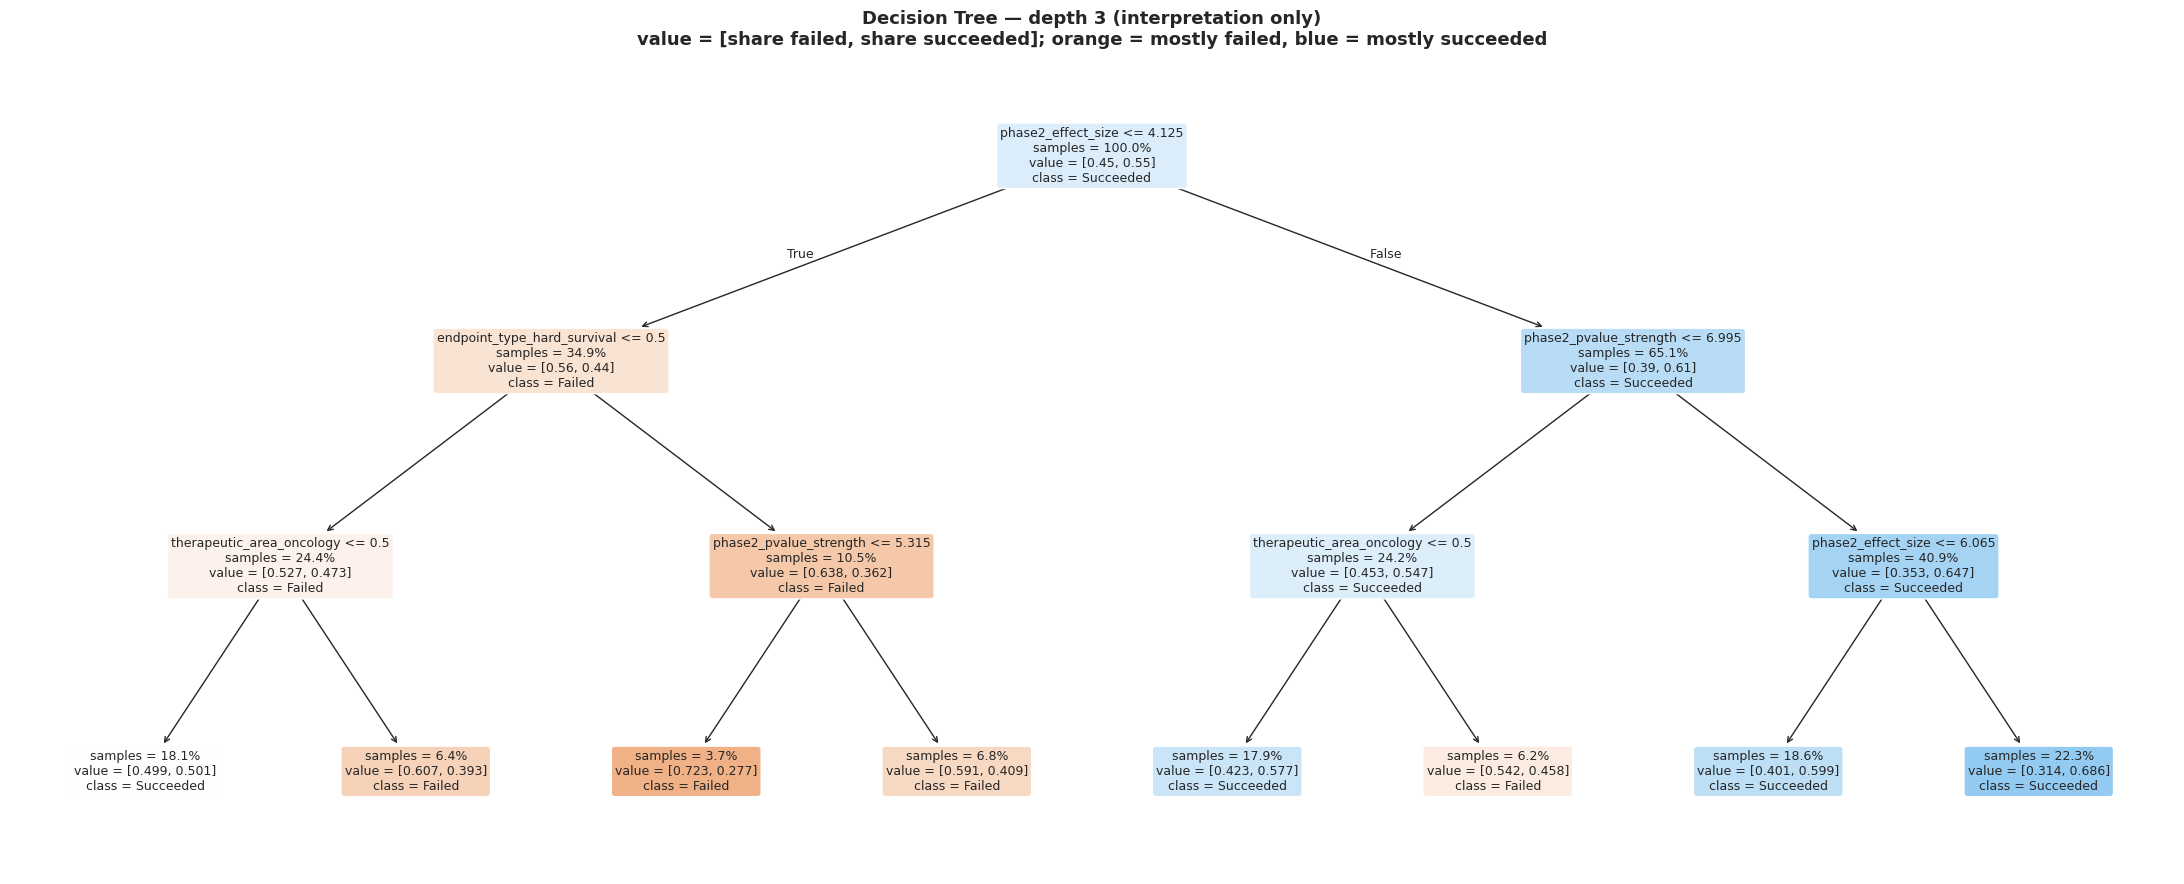

Trial profiles found by the depth-3 tree (sorted from most to least promising):


,Rule,Train trials,Train success rate,Test trials,Test success rate,Lift vs. average
0,phase2_effect_size > 4.12 AND phase2_pvalue_strength > 6.99 AND phase2_effect_size > 6.07,"7,508",68.6%,"1,928",67.7%,1.23×
1,phase2_effect_size > 4.12 AND phase2_pvalue_strength > 6.99 AND phase2_effect_size ≤ 6.07,"6,247",59.9%,"1,516",59.2%,1.08×
2,phase2_effect_size > 4.12 AND phase2_pvalue_strength ≤ 6.99 AND therapeutic_area ≠ oncology,"6,026",57.7%,"1,538",55.6%,1.01×
3,phase2_effect_size ≤ 4.12 AND endpoint_type ≠ hard_survival AND therapeutic_area ≠ oncology,"6,077",50.1%,"1,508",51.5%,0.94×
4,phase2_effect_size > 4.12 AND phase2_pvalue_strength ≤ 6.99 AND therapeutic_area = oncology,"2,090",45.8%,527,43.8%,0.80×
5,phase2_effect_size ≤ 4.12 AND endpoint_type = hard_survival AND phase2_pvalue_strength > 5.32,"2,269",40.9%,576,43.8%,0.79×
6,phase2_effect_size ≤ 4.12 AND endpoint_type ≠ hard_survival AND therapeutic_area = oncology,"2,137",39.3%,509,41.8%,0.76×
7,phase2_effect_size ≤ 4.12 AND endpoint_type = hard_survival AND phase2_pvalue_strength ≤ 5.32,"1,246",27.7%,298,31.5%,0.57×


In [119]:
# =============================================================================
# DECISION TREE — VISUALIZE A SHALLOW TREE + SPONSOR-READABLE DECISION RULES
# =============================================================================
# A depth-3 tree (each leaf ≥ 200 trials) is fitted for interpretation only.
# proportion=True shows each node's share of trials and class mix, so the
# "Succeeded" value in a leaf = expected precision if that profile is funded.
# =============================================================================
dt_viz = Pipeline([
    ("pre", make_preprocessor(scale=False)),
    ("clf", DecisionTreeClassifier(max_depth=3, min_samples_leaf=200,
                                   class_weight=CLASS_WEIGHT, random_state=RANDOM_STATE)),
]).fit(X_train, y_train)

plt.figure(figsize=(22, 9))
plot_tree(dt_viz.named_steps["clf"], feature_names=clean_feature_names(dt_viz),
          class_names=["Failed", "Succeeded"], filled=True, rounded=True,
          proportion=True, impurity=False, fontsize=9)
plt.title("Decision Tree — depth 3 (interpretation only)\n"
          "value = [share failed, share succeeded]; orange = mostly failed, blue = mostly succeeded",
          fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()


def _condition(name, thr, go_left):
    """Readable split text: one-hot → '= / ≠ level', binary → '= 0/1', numeric → '≤ / >'."""
    for col in categorical_cols:
        if name.startswith(col + "_"):
            return f"{col} {'≠' if go_left else '='} {name[len(col) + 1:]}"
    if name in binary_cols:
        return f"{name} = {0 if go_left else 1}"
    return f"{name} {'≤' if go_left else '>'} {thr:.2f}"


def leaf_rule_table(pipe, X_tr, y_tr, X_te, y_te):
    """One row per leaf: rule, size, and success rate (= precision if funded), train and test."""
    tree, pre, names = pipe.named_steps["clf"], pipe.named_steps["pre"], clean_feature_names(pipe)
    t, rules = tree.tree_, {}

    def walk(node, conds):
        if t.children_left[node] == t.children_right[node]:          # leaf
            rules[node] = " AND ".join(conds) or "(all trials)"
            return
        f, thr = names[t.feature[node]], t.threshold[node]
        walk(t.children_left[node],  conds + [_condition(f, thr, True)])
        walk(t.children_right[node], conds + [_condition(f, thr, False)])
    walk(0, [])

    tr = pd.DataFrame({"leaf": tree.apply(pre.transform(X_tr)), "y": np.asarray(y_tr)})
    te = pd.DataFrame({"leaf": tree.apply(pre.transform(X_te)), "y": np.asarray(y_te)})
    tbl = pd.DataFrame({"Rule":               pd.Series(rules),
                        "Train trials":       tr.groupby("leaf").size(),
                        "Train success rate": tr.groupby("leaf")["y"].mean(),
                        "Test trials":        te.groupby("leaf").size(),
                        "Test success rate":  te.groupby("leaf")["y"].mean()})
    tbl["Lift vs. average"] = tbl["Test success rate"] / np.mean(y_te)
    return tbl.sort_values("Train success rate", ascending=False).reset_index(drop=True)


rules_tbl = leaf_rule_table(dt_viz, X_train, y_train, X_test, y_test)
print("Trial profiles found by the depth-3 tree (sorted from most to least promising):")
display(rules_tbl.style.format({"Train trials": "{:,.0f}", "Test trials": "{:,.0f}",
                                "Train success rate": "{:.1%}", "Test success rate": "{:.1%}",
                                "Lift vs. average": "{:.2f}×"})
                 .background_gradient(subset=["Test success rate"], cmap="RdYlGn", vmin=0.3, vmax=0.8))

In [120]:
# =============================================================================
# DECISION TREE — HYPERPARAMETER TUNING (RandomizedSearchCV, precision-focused)
# =============================================================================
# The template's full grid (3,456 combinations × 5 folds ≈ 17,000 fits) is
# replaced by 80 random draws. Leaf sizes start at 20 trials so every leaf's
# success rate (its precision) rests on enough trials to be trustworthy.
# =============================================================================
dt_param_dist = {
    "clf__criterion":         ["gini", "entropy"],
    "clf__max_depth":         [3, 4, 5, 6, 8, 10, 12, None],
    "clf__min_samples_leaf":  [20, 50, 100, 200, 400],
    "clf__min_samples_split": [50, 100, 200, 500],
    "clf__max_features":      [None, "sqrt"],
    "clf__ccp_alpha":         [0.0, 1e-5, 1e-4, 5e-4, 1e-3],
}

dt_search = RandomizedSearchCV(dt_pipeline, dt_param_dist, n_iter=80, scoring=SCORING,
                               refit=PRIMARY, cv=cv, n_jobs=-1, random_state=RANDOM_STATE)
dt_search.fit(X_train, y_train)
search_summary(dt_search)
dt_tuned = dt_search.best_estimator_
print(f"Tuned tree: depth = {dt_tuned.named_steps['clf'].get_depth()}, "
      f"leaves = {dt_tuned.named_steps['clf'].get_n_leaves():,}")

Best CV precision @ top 30%: 0.687
Best parameters: {'min_samples_split': 100, 'min_samples_leaf': 400, 'max_features': None, 'max_depth': 12, 'criterion': 'gini', 'ccp_alpha': 1e-05}


,params,CV precision_at_k,CV average_precision,CV roc_auc,CV precision,CV recall,CV precision_at_k SD
0,"{'min_samples_split': 100, 'min_samples_leaf':...",0.687,0.662,0.634,0.623,0.722,0.007
1,"{'min_samples_split': 50, 'min_samples_leaf': ...",0.687,0.662,0.634,0.623,0.722,0.007
2,"{'min_samples_split': 100, 'min_samples_leaf':...",0.687,0.662,0.634,0.623,0.722,0.007
3,"{'min_samples_split': 500, 'min_samples_leaf':...",0.687,0.662,0.634,0.623,0.722,0.007
4,"{'min_samples_split': 500, 'min_samples_leaf':...",0.686,0.664,0.633,0.621,0.716,0.006


Tuned tree: depth = 9, leaves = 66


Decision Tree — Tuned Model
Metric (threshold = 0.50)                Train       Test
Precision                                0.634      0.624  ← primary
Precision @ top 30%                      0.710      0.688  ← primary
Recall                                   0.736      0.724
Specificity                              0.481      0.466
F1-Score                                 0.681      0.670
Accuracy                                 0.621      0.608
AUC-ROC                                  0.658      0.636
Trials funded (predicted go)            21,449      5,363
Failed trials funded (FP)                7,840      2,018


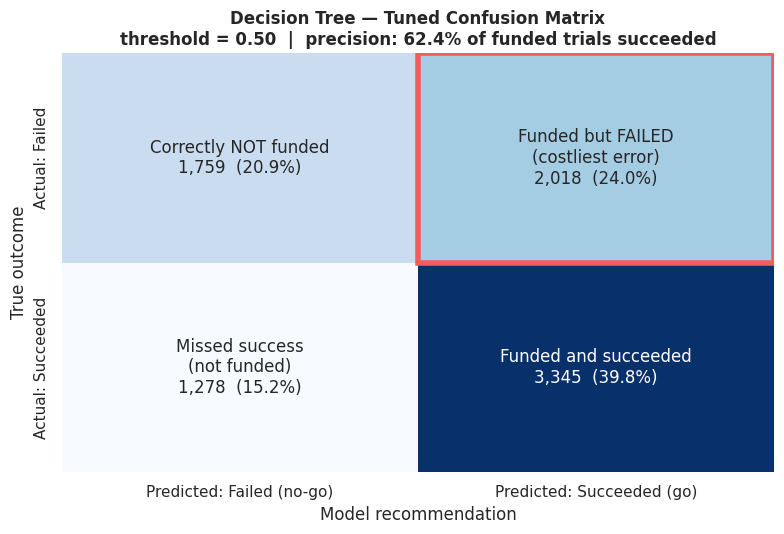

Classification Report:
              precision    recall  f1-score   support

      Failed       0.58      0.47      0.52      3777
   Succeeded       0.62      0.72      0.67      4623

    accuracy                           0.61      8400
   macro avg       0.60      0.59      0.59      8400
weighted avg       0.60      0.61      0.60      8400



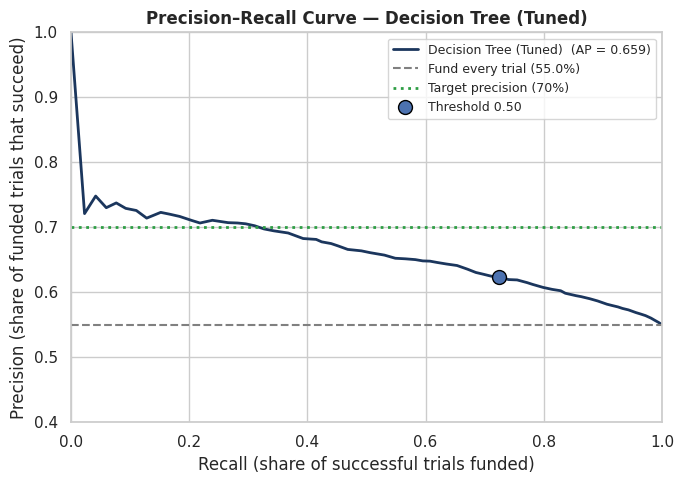

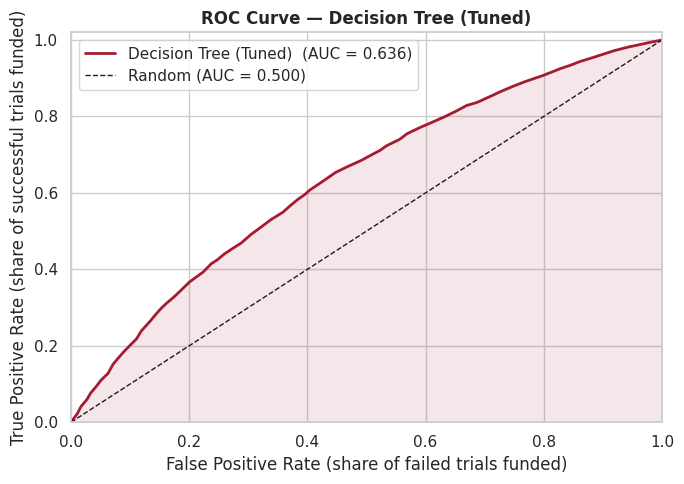

In [121]:
# =============================================================================
# DECISION TREE — TUNED MODEL EVALUATION
# =============================================================================
print("Decision Tree — Tuned Model")
dt_tuned_scores = get_metrics_score(dt_tuned, X_train, X_test, y_train, y_test)

make_confusion_matrix(dt_tuned, X_test, y_test, title="Decision Tree — Tuned Confusion Matrix")
dt_tuned_ap  = plot_pr_curve(dt_tuned, X_test, y_test, model_name="Decision Tree (Tuned)")
dt_tuned_auc = plot_roc_curve(dt_tuned, X_test, y_test, model_name="Decision Tree (Tuned)")

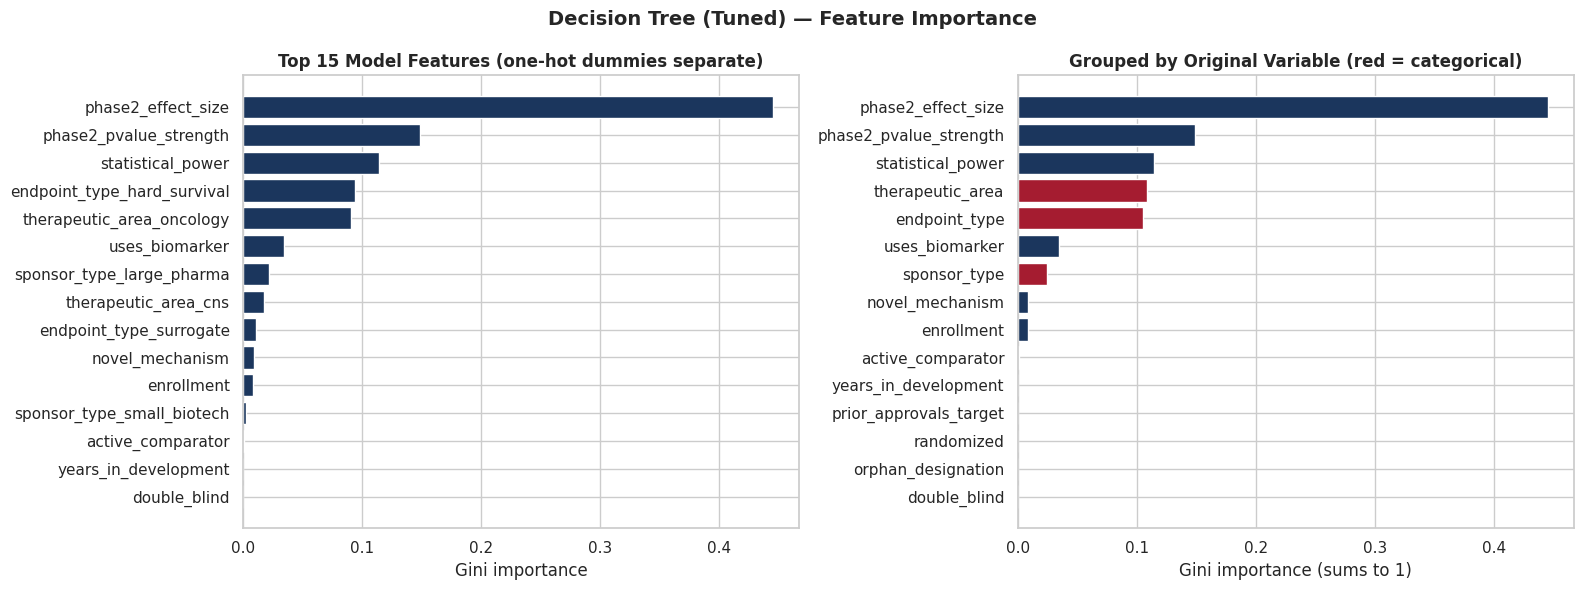

,Importance
phase2_effect_size,0.4451
phase2_pvalue_strength,0.1488
statistical_power,0.1143
therapeutic_area,0.1088
endpoint_type,0.1051
uses_biomarker,0.0344
sponsor_type,0.0248
novel_mechanism,0.0091
enrollment,0.0085
active_comparator,0.0010


In [122]:
# =============================================================================
# DECISION TREE — FEATURE IMPORTANCE (per dummy and grouped by original variable)
# =============================================================================
# Gini importance = share of total impurity reduction from splits on each feature.
# Importances are additive, so one-hot dummies can be summed into their variable.
# Caveat: impurity importance favours continuous features with many split points;
# the permutation importance for the selected model (later) is the fairer check.
# =============================================================================
imp = pd.Series(dt_tuned.named_steps["clf"].feature_importances_,
                index=clean_feature_names(dt_tuned))
grouped_imp = imp.groupby(original_feature).sum().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
top = imp.sort_values().tail(15)
axes[0].barh(top.index, top.values, color=MAIN_COLOR, edgecolor="white")
axes[0].set_title("Top 15 Model Features (one-hot dummies separate)", fontweight="bold")
axes[0].set_xlabel("Gini importance")
axes[1].barh(grouped_imp.index, grouped_imp.values, edgecolor="white",
             color=["#A51C30" if c in categorical_cols else MAIN_COLOR for c in grouped_imp.index])
axes[1].set_title("Grouped by Original Variable (red = categorical)", fontweight="bold")
axes[1].set_xlabel("Gini importance (sums to 1)")
plt.suptitle("Decision Tree (Tuned) — Feature Importance", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

display(grouped_imp.sort_values(ascending=False).round(4).to_frame("Importance"))

### Interpretation of Decision Tree Results
*Interpretation of Synthetic dataset, seed 973.*

- **The baseline overfits badly.** It grew to depth 35 with 8,119 leaves. Training precision is 1.000, but test precision is only 0.584 (precision@30% 0.573, AUC 0.536, barely above the 0.50 of a coin flip). It memorized individual trials, so the unconstrained tree is never a candidate for deployment.
- **Tuning fixes this by simplifying.** The best tree has a depth of 9, 66 leaves, and at least 400 trials per leaf. Its train-test gap in precision@30% shrinks to 0.022 (0.710 vs. 0.688).
- **It still trails the smooth models.** Test precision@30% is 0.688 vs. 0.716 for LR, about 3 points lower. A tree gives every trial in a leaf the same score, so it ranks trials in coarse steps.
- **Same drivers.** Grouped Gini importance ranks phase2_effect_size (0.445), phase2_pvalue_strength (0.149), statistical_power (0.114), therapeutic_area (0.109) and endpoint_type (0.105) highest, followed by uses_biomarker (0.034) and sponsor_type (0.025). Five variables get exactly 0 (prior approvals, double-blind, years, orphan designation, randomized). Gini importance favours continuous variables with many split points, which is why effect size looks so dominant. Permutation importance below is the fairer check.

**How to Interpret the Rules Table (depth-3 tree)**
- The most promising profile is `phase2_effect_size > 6.07 AND phase2_pvalue_strength > 6.99` (the extra "> 4.12" condition in the printed rule is redundant). It covers 1,928 test trials, with a **67.7%** test success rate (lift 1.23×).
- The riskiest profile is `effect size ≤ 4.12 AND hard-survival endpoint AND p-value strength ≤ 5.32`. It has a test success rate of **31.5%** on 298 trials (lift 0.57×).
- Oncology trials with moderate Phase 2 evidence (43.8%) or weak evidence (41.8%) are the other low-performing profiles.
- **No profile reaches the 70% target precision.** The best is 67.7%.
- Train and test rates are within 4 points in every leaf, so the profiles are reliable. The largest gaps are in the smallest leaves, where sampling noise is largest.

---

## XGBoost (Extreme Gradient Boosting)

### What is XGBoost?

**XGBoost** (Chen & Guestrin, 2016) is a highly optimized implementation of gradient boosting that adds several important refinements:

**1. Regularization built into the objective:**

$$
\mathcal{L}^{(b)} = \sum_{i=1}^{n} \ell(y_i, \hat{y}_i^{(b)}) + \Omega(h_b)
$$

where the regularization term $\Omega(h_b) = \gamma T + \frac{1}{2}\lambda\|w\|^2$ penalizes tree complexity ($T$ = number of leaves, $w$ = leaf weights).

**2. Second-order approximation of the loss** — uses both gradient and Hessian for more accurate leaf weight computation

**3. Column subsampling** (like Random Forest's feature subsampling) — reduces overfitting and speeds up training

**4. Sparsity awareness** — efficiently handles missing values internally

**5. Parallel and distributed computation** — much faster than sklearn's GradientBoostingClassifier

### Why XGBoost Dominates Tabular ML Competitions

XGBoost consistently performs among the top algorithms on structured/tabular data because it combines the power of gradient boosting with built-in regularization, computational efficiency, and robustness to missing values. It is the algorithm of choice for many Kaggle competition winners working with tabular data.

### Key Hyperparameters

| Parameter | What it controls |
|---|---|
| `n_estimators` | Number of boosting rounds |
| `learning_rate` (eta) | Shrinkage per round |
| `max_depth` | Maximum tree depth |
| `subsample` | Row sampling per tree |
| `colsample_bytree` | Column sampling per tree |
| `reg_alpha` | L1 regularization on leaf weights |
| `reg_lambda` | L2 regularization on leaf weights |
| `scale_pos_weight` | Addresses class imbalance (ratio of neg/pos) |

In [123]:
# =============================================================================
# MODULE 4B IMPORTS: BOOSTING, STACKING, NEURAL NETWORKS, XAI
# =============================================================================

from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    StackingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

# XGBoost — install if not already available
%pip install xgboost
from xgboost import XGBClassifier

# SHAP — install if not already available
%pip install shap
import shap

import warnings
warnings.filterwarnings("ignore")

print("Module 4B imports loaded successfully.")
print("  • AdaBoostClassifier")
print("  • GradientBoostingClassifier")
print("  • XGBClassifier")
print("  • StackingClassifier")
print("  • MLPClassifier")
print("  • shap")

Module 4B imports loaded successfully.
  • AdaBoostClassifier
  • GradientBoostingClassifier
  • XGBClassifier
  • StackingClassifier
  • MLPClassifier
  • shap


Class ratio (fail/success) = 0.82 → no reweighting applied
XGBoost — Baseline
Metric (threshold = 0.50)                Train       Test
Precision                                0.658      0.637  ← primary
Precision @ top 30%                      0.756      0.710  ← primary
Recall                                   0.760      0.740
Specificity                              0.517      0.484
F1-Score                                 0.705      0.685
Accuracy                                 0.650      0.625
AUC-ROC                                  0.704      0.664
Trials funded (predicted go)            21,350      5,371
Failed trials funded (FP)                7,304      1,949


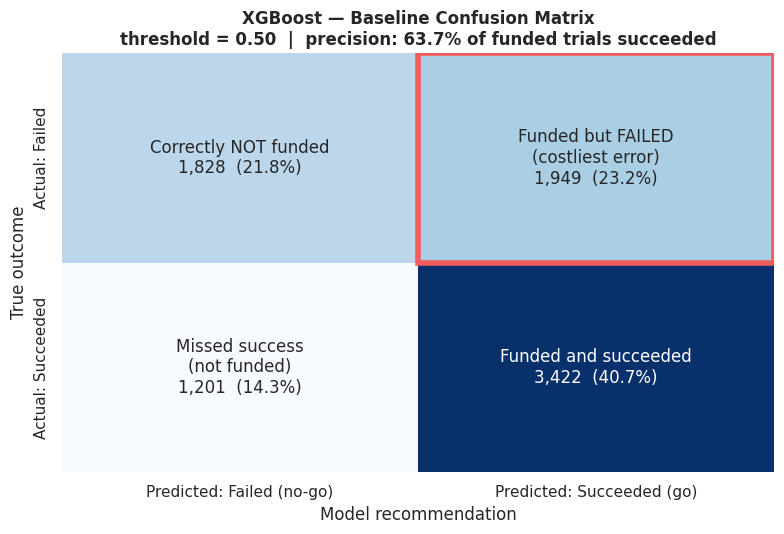

Classification Report:
              precision    recall  f1-score   support

      Failed       0.60      0.48      0.54      3777
   Succeeded       0.64      0.74      0.68      4623

    accuracy                           0.62      8400
   macro avg       0.62      0.61      0.61      8400
weighted avg       0.62      0.62      0.62      8400



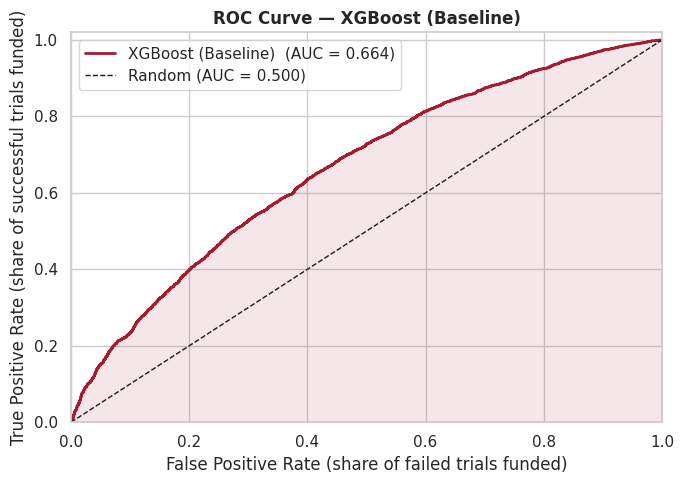

In [124]:
# =============================================================================
# M4B–Section 3: XGBOOST — BASELINE MODEL
# =============================================================================
# • scale_pos_weight REMOVED (default = 1). Classes are roughly balanced and
#   success is the MAJORITY class, so neg/pos ≈ 0.82 would wrongly
#   down-weight successful trials.
# • KNNImputer REMOVED: no missing values, and it is very slow on ~42k rows.
# • One-hot encoding added for the 3 categorical columns; numeric and binary
#   columns pass through unscaled (trees don't need scaling or transforms).
# • tree_method='hist' speeds up training on large tabular data.
# =============================================================================

pre_xgb = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("num", "passthrough", numeric_cols + binary_cols),
], remainder="drop")

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
print(f"Class ratio (fail/success) = {neg/pos:.2f} → no reweighting applied")

xgb_pipeline = Pipeline([
    ("pre", pre_xgb),
    ("clf", XGBClassifier(
                n_estimators=100,
                learning_rate=0.1,
                max_depth=4,
                subsample=0.8,
                colsample_bytree=0.8,
                tree_method="hist",
                eval_metric="logloss",
                random_state=RANDOM_STATE,
                n_jobs=-1
            ))
])

xgb_pipeline.fit(X_train, y_train)

print("XGBoost — Baseline")
xgb_scores = get_metrics_score(xgb_pipeline, X_train, X_test, y_train, y_test)

# =============================================================================
# XGBOOST — CONFUSION MATRIX AND ROC CURVE
# =============================================================================
make_confusion_matrix(xgb_pipeline, X_test, y_test,
                      title="XGBoost — Baseline Confusion Matrix")

xgb_auc = plot_roc_curve(xgb_pipeline, X_test, y_test,
                         model_name="XGBoost (Baseline)")

Best CV precision @ top 30%: 0.723
Best parameters: {'subsample': 0.7, 'reg_lambda': 5.0, 'reg_alpha': 0.1, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.7}


,params,CV precision_at_k,CV average_precision,CV roc_auc,CV precision,CV recall,CV precision_at_k SD
0,"{'subsample': 0.7, 'reg_lambda': 5.0, 'reg_alp...",0.723,0.699,0.670,0.638,0.747,0.011
1,"{'subsample': 0.8, 'reg_lambda': 5.0, 'reg_alp...",0.722,0.699,0.669,0.638,0.747,0.010
2,"{'subsample': 0.7, 'reg_lambda': 1.0, 'reg_alp...",0.720,0.699,0.669,0.636,0.759,0.011
3,"{'subsample': 0.8, 'reg_lambda': 2.0, 'reg_alp...",0.720,0.698,0.668,0.637,0.749,0.010
4,"{'subsample': 0.7, 'reg_lambda': 5.0, 'reg_alp...",0.719,0.697,0.667,0.640,0.736,0.009


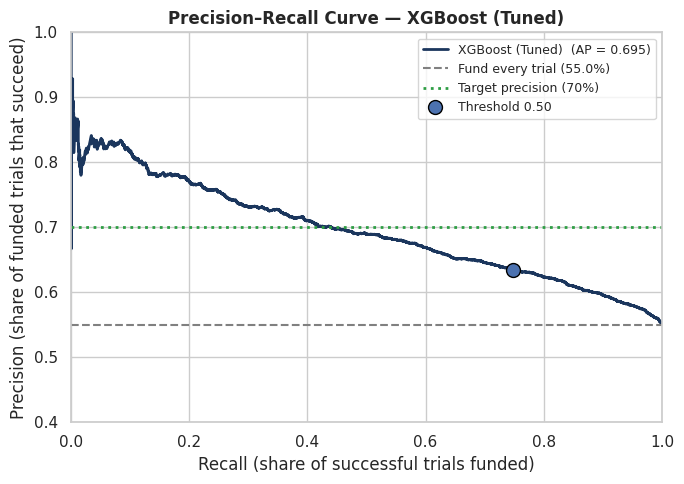

In [125]:
# =============================================================================
# XGBOOST — HYPERPARAMETER TUNING (RandomizedSearchCV)
# =============================================================================
# • GridSearchCV → RandomizedSearchCV: the full grid is 3,888 combos × 5 folds
#   ≈ 19,000 fits on ~34k rows. 50 random draws × 5 folds = 250 fits.
# • scoring='recall' → 'roc_auc': with balanced classes, recall can be inflated
#   just by predicting "success" more often.
# • XGBoost uses n_jobs=1 inside the search so the parallel CV jobs don't
#   oversubscribe the CPU.
# =============================================================================

xgb_param_dist = {
    "clf__n_estimators":     [100, 200, 300, 500],
    "clf__learning_rate":    [0.01, 0.05, 0.1, 0.2],
    "clf__max_depth":        [3, 4, 5, 6],
    "clf__subsample":        [0.7, 0.8, 1.0],
    "clf__colsample_bytree": [0.7, 0.8, 1.0],
    "clf__reg_alpha":        [0, 0.1, 1.0],
    "clf__reg_lambda":       [1.0, 2.0, 5.0],
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline.set_params(clf__n_jobs=1),
    param_distributions=xgb_param_dist,
    n_iter=50,
    scoring=SCORING,       # record every metric
    refit=PRIMARY,         # choose settings by precision among the top-ranked trials
    cv=cv, n_jobs=-1, random_state=RANDOM_STATE, verbose=0)
xgb_search.fit(X_train, y_train)
search_summary(xgb_search)

xgb_tuned = xgb_search.best_estimator_
xgb_pipeline.set_params(clf__n_jobs=-1);   # restore for later use (';' hides the output)

xgb_tuned_ap = plot_pr_curve(xgb_tuned, X_test, y_test, model_name="XGBoost (Tuned)")

## Interpreting the XGBoost results
*Interpretation of Synthetic dataset, seed 973.*

**XGBoost does not beat logistic regression.** On every test metric the models are effectively tied, and logistic regression is marginally ahead on most.

| Test metric | Logistic Regression (Tuned) | XGBoost (Baseline) | XGBoost (Tuned) |
|---|---|---|---|
| Precision @ top 30% | **0.716** | 0.710 | 0.715 |
| AUC-ROC | **0.667** | 0.664 | 0.665 |
| Precision (0.5) | **0.639** | 0.637 | 0.634 |
| Recall (0.5) | 0.743 | 0.740 | **0.748** |
| Failed trials funded (0.5) | **1,938** | 1,949 | 1,994 |

### What the results show
- **The models are statistically tied.** With 8,400 test trials, the 95% uncertainty on each AUC is roughly ±0.011, and on precision@30% roughly ±0.018. Gaps of 0.001–0.003 are well within that. When two models tie, the simpler one is preferred.
- **Tuning made XGBoost simpler.** The best settings use shallower trees (`max_depth` 3 vs. 4), a slower learning rate (0.05 vs. 0.1), more trees (200), and stronger regularization (`reg_lambda` 5.0, `reg_alpha` 0.1). The search moved *away* from complex trees, which suggests few non-linear patterns or interactions are available. This is expected, because none were planted.
- **The baseline overfit, and tuning reduced it.** The baseline's training AUC was 0.704 against 0.664 on test, and its precision@30% gap was 0.046. After tuning, the precision@30% gap fell to 0.023. Cross-validated AUC (0.670) is close to the test AUC (0.665), so the estimate is reliable.
- **Both models make the same kind of mistakes.** The baseline XGBoost flags about 74% of successes but only 48% of failures, almost identical to LR.
- **Generator caveat.** The true model is additive and logistic, so XGBoost's inability to beat it says nothing about real trials, where interactions may exist.

---

## SHAP Values

### Why Explainability Matters

As machine learning models become more accurate, they often become less interpretable. Yet in clinical, legal, and scientific contexts, **understanding why a model makes a prediction is as important as the prediction itself**.

For supervised learning on tabular data, **SHAP values** are the current gold standard for making model predictions interpretable to humans.

### SHAP Values — Shapley Values from Game Theory

**SHAP** (SHapley Additive exPlanations, Lundberg & Lee, 2017) assigns each feature a **contribution score** for each individual prediction, grounded in Shapley values from cooperative game theory.

### The Shapley Value

The Shapley value for feature $j$ in prediction $i$ is the **average marginal contribution** of feature $j$ across all possible orderings in which features could be added to the model:

$$
\phi_j(i) = \sum_{S \subseteq \mathcal{F} \setminus \{j\}} \frac{|S|!\,(|\mathcal{F}| - |S| - 1)!}{|\mathcal{F}|!} \left[ v(S \cup \{j\}) - v(S) \right]
$$

where:
- $\mathcal{F}$ = set of all features
- $S$ = a subset of features not including $j$
- $v(S)$ = model prediction using only features in $S$

In plain English: the SHAP value for feature $j$ in observation $i$ answers the question — *"How much did feature $j$ push this particular prediction above or below the average prediction, averaged across all possible ways the other features could have been introduced first?"*

### Key Properties of SHAP

| Property | Meaning |
|---|---|
| **Local** | Explains individual predictions, not the model overall |
| **Consistent** | If a feature becomes more important, its SHAP value never decreases |
| **Additive** | SHAP values sum to the difference between the prediction and the mean prediction |
| **Model-agnostic** | Works for any ML model |

$$
\hat{f}(x_i) = \mathbb{E}[\hat{f}(x)] + \sum_{j=1}^{p} \phi_j(i)
$$

### SHAP vs. Feature Importance (MDI)

| | MDI Feature Importance | SHAP |
|---|---|---|
| Scope | Global (whole dataset) | Local (per observation) + global |
| Sign | Always positive | Positive or negative (direction matters) |
| Consistency | Can be biased for high-cardinality features | Theoretically grounded |
| Model types | Tree-based only | Any model |

In [126]:
# =============================================================================
# SHAP VALUES — TREE EXPLAINER
# =============================================================================
# SHAP provides two main explainers for sklearn models:
#
#   TreeExplainer  — exact, fast computation for tree-based models
#                    (Random Forest, Gradient Boosting, XGBoost, Decision Tree)
#   KernelExplainer — model-agnostic, slower (for any model including MLP, SVM)
#
# We use TreeExplainer on the tuned XGBoost pipeline.
#
# Notes for this dataset:
#   • pre_xgb one-hot encodes the 3 categorical columns WITHOUT dropping a level
#     (trees don't need a reference group), so 12 raw predictors become 28
#     model features: 16 dummies + 6 numeric + 6 binary.
#   • Feature names therefore come from the preprocessor, NOT X_train.columns.
#   • For XGBoost, SHAP values are on the LOG-ODDS scale of P(trial success).
# =============================================================================
from scipy import sparse
import xgboost as xgb

# ── Set your best tree-based model ───────────────────────────
BEST_TREE_MODEL      = xgb_tuned            # ← or xgb_pipeline for the baseline
BEST_TREE_MODEL_NAME = "XGBoost (Tuned)"
CLASS_NAMES          = {0: "Failed", 1: "Succeeded"}
# ─────────────────────────────────────────────────────────────

preprocessor = BEST_TREE_MODEL.named_steps["pre"]
tree_clf     = BEST_TREE_MODEL.named_steps["clf"]

def _to_dense(M):
    """OneHotEncoder may return a sparse matrix; SHAP plots need dense arrays."""
    return M.toarray() if sparse.issparse(M) else np.asarray(M)

# Transformed feature names, minus the 'cat__' / 'num__' prefixes
shap_feature_names = [n.split("__", 1)[1] for n in preprocessor.get_feature_names_out()]

X_test_transformed  = _to_dense(preprocessor.transform(X_test)).astype(float)
X_train_transformed = _to_dense(preprocessor.transform(X_train)).astype(float)

X_test_transformed_df = pd.DataFrame(X_test_transformed,
                                     columns=shap_feature_names,
                                     index=X_test.index)

# Compute SHAP values
try:
    explainer = shap.TreeExplainer(tree_clf)
    shap_explanation = explainer(X_test_transformed_df)
except Exception as e:
    # Some SHAP releases can't parse models saved by XGBoost >= 2.1.
    # XGBoost's built-in TreeSHAP (pred_contribs) gives the same exact values.
    print(f"shap.TreeExplainer failed ({type(e).__name__}: {e})")
    print("→ Falling back to XGBoost's native TreeSHAP (pred_contribs=True)\n")
    explainer = None
    contribs = tree_clf.get_booster().predict(
        xgb.DMatrix(X_test_transformed), pred_contribs=True
    )                                        # last column = bias (base value)
    shap_explanation = shap.Explanation(
        values=contribs[:, :-1],
        base_values=contribs[:, -1],
        data=X_test_transformed,
        feature_names=shap_feature_names,
    )

# Some SHAP versions return a separate output per class (n, features, 2).
# Keep class 1 = trial succeeded.
if shap_explanation.values.ndim == 3:
    shap_explanation = shap_explanation[:, :, 1]

shap_explanation.feature_names = shap_feature_names
shap_vals_class1 = shap_explanation.values

print(f"SHAP values computed for: {BEST_TREE_MODEL_NAME}")
print(f"Raw predictors: {X_test.shape[1]} → model features after one-hot: {len(shap_feature_names)}")
print(f"Shape of SHAP values (test set, class 1 = Succeeded): {shap_vals_class1.shape}")

SHAP values computed for: XGBoost (Tuned)
Raw predictors: 15 → model features after one-hot: 28
Shape of SHAP values (test set, class 1 = Succeeded): (8400, 28)


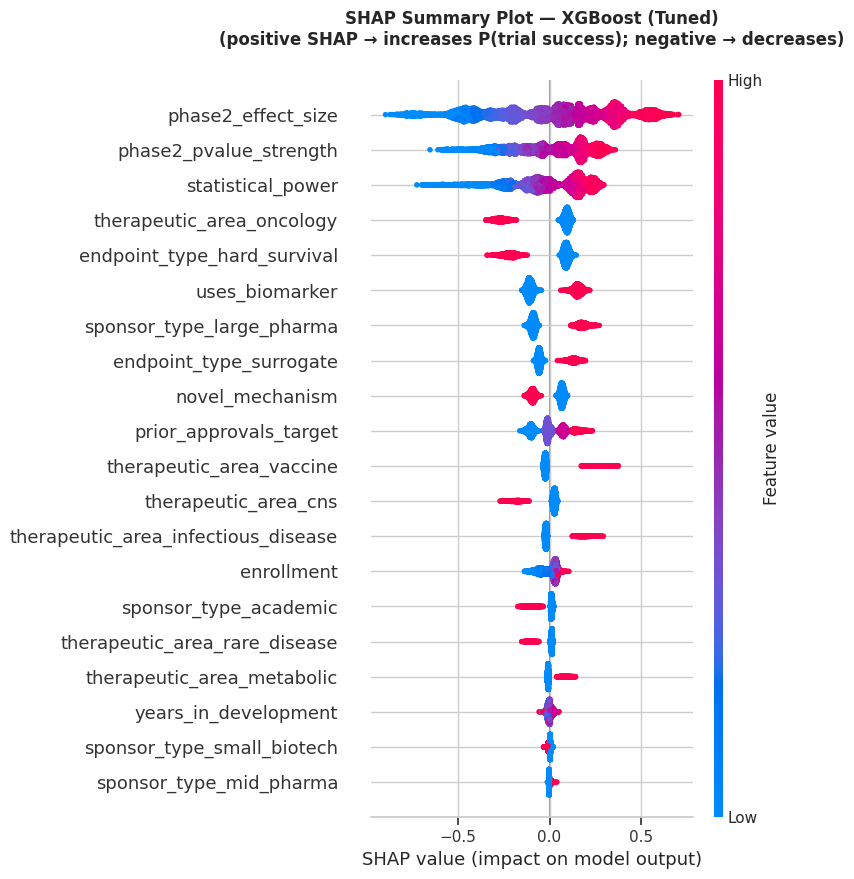

In [127]:
# =============================================================================
# SHAP — SUMMARY PLOT (GLOBAL FEATURE IMPORTANCE)
# =============================================================================
# Each dot = one test-set trial. Colour = feature value (red = high, blue = low;
# for 0/1 and one-hot columns, red = 1). x-axis = push toward success (+)
# or failure (−), in log-odds.
# =============================================================================
plt.figure(figsize=(10, 10))
shap.summary_plot(
    shap_vals_class1,
    X_test_transformed_df,              # DataFrame → feature names come from its columns
    plot_type="dot",
    max_display=20,
    show=False
)
plt.title(f'SHAP Summary Plot — {BEST_TREE_MODEL_NAME}\n'
          f'(positive SHAP → increases P(trial success); negative → decreases)',
          fontsize=12, fontweight='bold', pad=25)
plt.subplots_adjust(top=0.85)
plt.show();

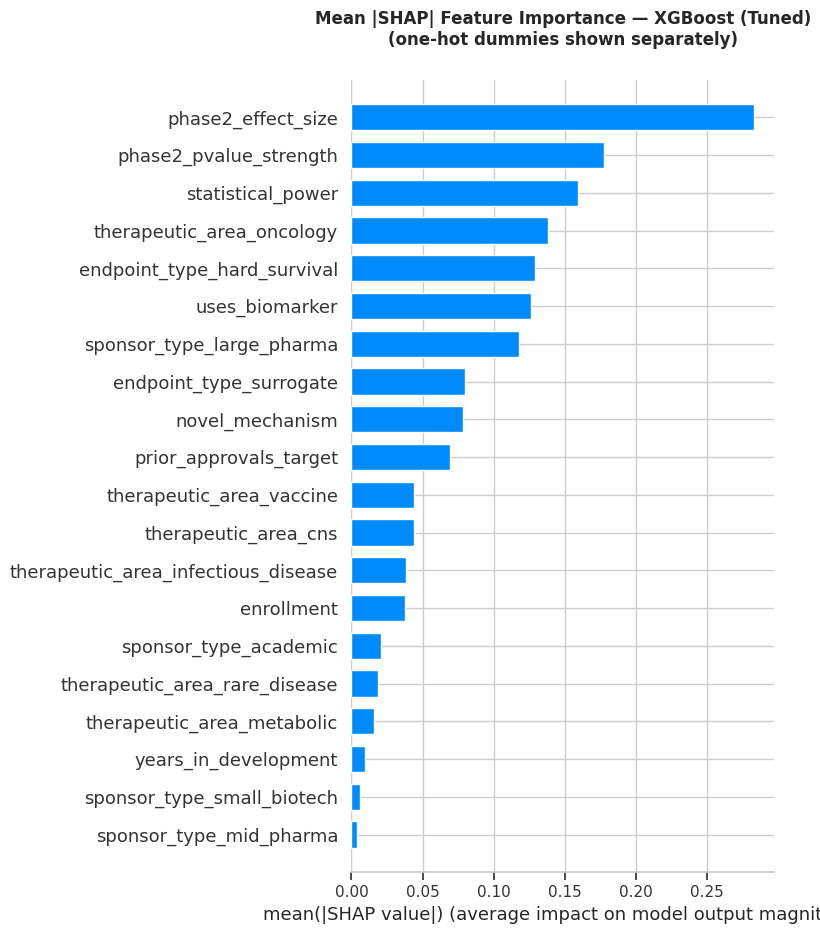

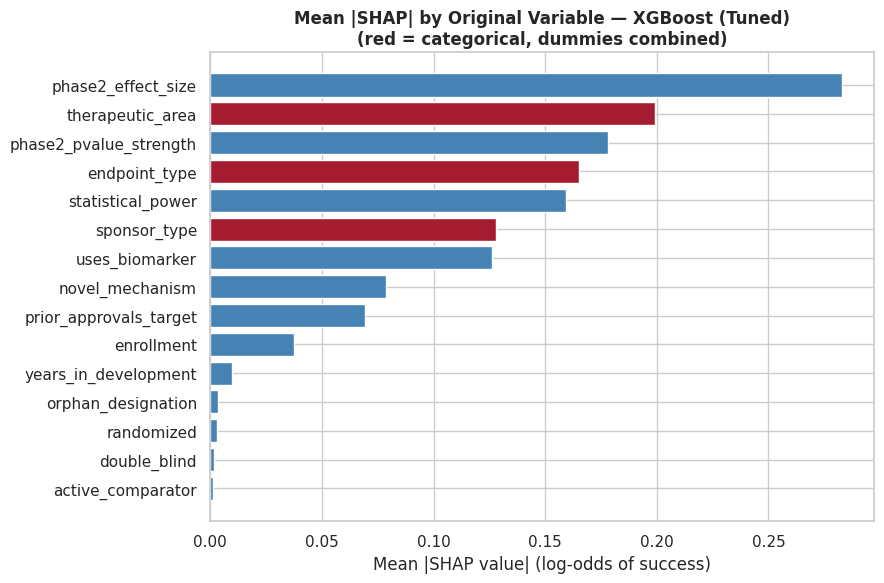

In [128]:
# =============================================================================
# SHAP — MEAN ABSOLUTE SHAP (GLOBAL BAR CHART)
# =============================================================================
# Shows average |SHAP value| per feature — a cleaner global importance ranking.
# =============================================================================

plt.figure(figsize=(9, 8))
shap.summary_plot(
    shap_vals_class1,
    X_test_transformed_df,
    plot_type="bar",
    max_display=20,
    show=False
)
plt.title(f'Mean |SHAP| Feature Importance — {BEST_TREE_MODEL_NAME}\n(one-hot dummies shown separately)',
          fontsize=12, fontweight='bold', pad=25)
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# Grouped by ORIGINAL variable (sum dummy SHAP values per trial, then mean |·|)
# -----------------------------------------------------------------------------
def original_feature(name):
    for col in categorical_cols:
        if name.startswith(col + "_"):
            return col
    return name

shap_df = pd.DataFrame(shap_vals_class1, columns=shap_feature_names)
shap_grouped = shap_df.T.groupby([original_feature(c) for c in shap_df.columns]).sum().T
grouped_importance = shap_grouped.abs().mean().sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#A51C30" if f in categorical_cols else "steelblue" for f in grouped_importance.index]
ax.barh(grouped_importance.index, grouped_importance.values, color=colors)
ax.set_xlabel("Mean |SHAP value| (log-odds of success)")
ax.set_title(f'Mean |SHAP| by Original Variable — {BEST_TREE_MODEL_NAME}\n'
             f'(red = categorical, dummies combined)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()# =============================================================================

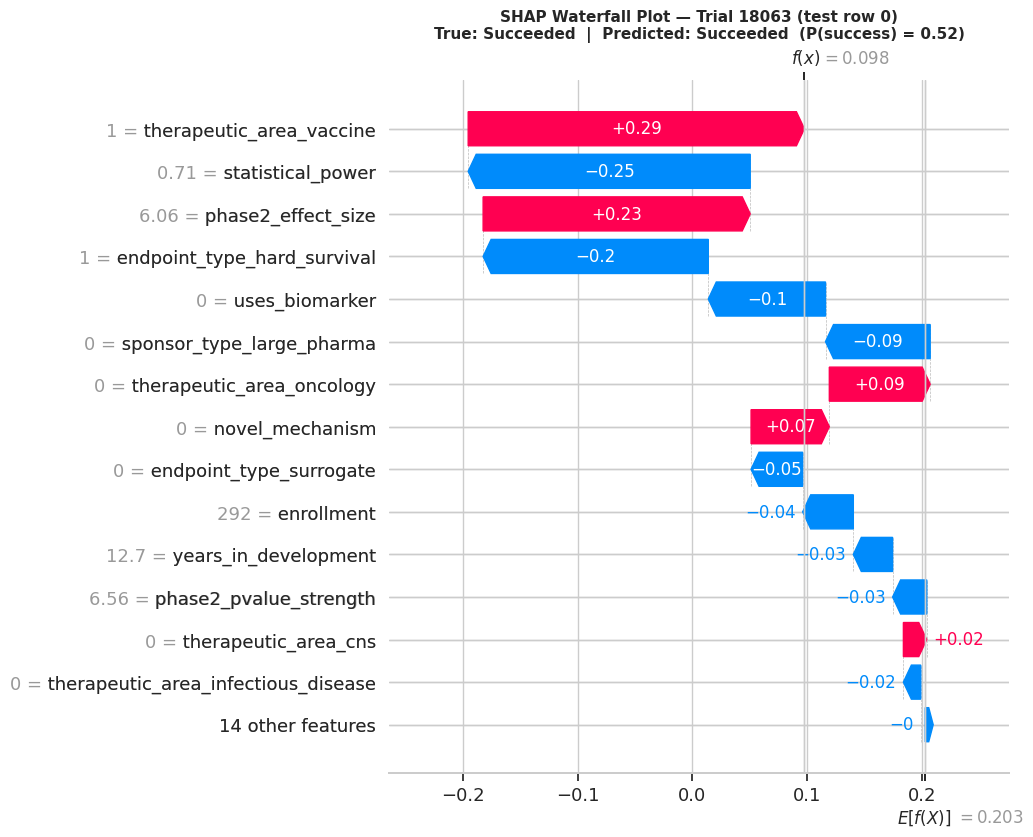


Observation 0 raw feature values:


,trial_id,therapeutic_area,endpoint_type,sponsor_type,phase2_effect_size,phase2_pvalue_strength,enrollment,statistical_power,prior_approvals_target,years_in_development,uses_biomarker,novel_mechanism,randomized,double_blind,active_comparator,orphan_designation,trial_success
18063,SYN018063,vaccine,hard_survival,small_biotech,6.06,6.56,292,0.71,1,12.7,0,0,1,1,0,1,1


In [129]:
# =============================================================================
# SHAP — WATERFALL PLOT (SINGLE PREDICTION EXPLANATION)
# =============================================================================
# E[f(X)] = average model output (log-odds) over the background data;
# f(x)    = this trial's log-odds. P(success) = 1 / (1 + exp(-f(x))).
# =============================================================================

OBSERVATION_IDX = 0   # ← change to any index in [0, len(X_test)-1]

obs_explanation = shap_explanation[OBSERVATION_IDX]
obs_explanation.feature_names = shap_feature_names

true_label = y_test.iloc[OBSERVATION_IDX]
pred_label = BEST_TREE_MODEL.predict(X_test.iloc[[OBSERVATION_IDX]])[0]
pred_proba = BEST_TREE_MODEL.predict_proba(X_test.iloc[[OBSERVATION_IDX]])[0, 1]

plt.figure(figsize=(10, 6))
shap.plots.waterfall(obs_explanation, max_display=15, show=False)
plt.title(f'SHAP Waterfall Plot — Trial {X_test.index[OBSERVATION_IDX]} '
          f'(test row {OBSERVATION_IDX})\n'
          f'True: {CLASS_NAMES[true_label]}  |  '
          f'Predicted: {CLASS_NAMES[pred_label]}  (P(success) = {pred_proba:.2f})',
          fontsize=11, fontweight='bold')
plt.subplots_adjust(top=0.88)
plt.show()
plt.close('all')

print(f"\nObservation {OBSERVATION_IDX} raw feature values:")
display(df.loc[[X_test.index[OBSERVATION_IDX]], [ID_COL] + X_test.columns.tolist() + [TARGET]])

### How to read the SHAP plots
- **Summary (beeswarm) plot:** each dot is one test trial. Its position shows how much that feature pushed the prediction toward success (right) or failure (left). Red dots are high values, or "yes" for 0/1 features.
- **Bar charts:** average impact of each feature. The *grouped* chart adds up all of a category's dummy columns, so `therapeutic_area` appears as one variable. This is the fairer ranking.
- **Waterfall plot:** explains one trial. It starts from the average prediction and adds each feature's push to reach that trial's predicted log-odds.
- XGBoost keeps **all** category levels, so a dummy such as `therapeutic_area_oncology` means "oncology vs. not oncology", not "vs. a reference group" as in logistic regression.

### Interpretation of SHAP Results
*Interpretation of Synthetic dataset, seed 973.*

- **Top drivers (grouped bar chart):** effect size, therapeutic area, p-value strength, endpoint, power.
- **Direction:** high `phase2_effect_size` values (red) should sit on the positive side, and `therapeutic_area_oncology` on the negative side. Both agree with the odds ratios.
- **Shape:** dots for each feature should separate along a single direction with no mixed patterns, consistent with monotonic, additive effects.
- **Waterfall example (trial SYN018063, test row 0; true outcome: succeeded):** a vaccine trial (favourable) with a hard-survival endpoint and small-biotech sponsor (unfavourable), effect size 6.06 (above average), low power (0.71), and no novel mechanism. Predicted P(success) = 0.52. Expect the vaccine area and effect size to push up, and the hard-survival endpoint, small-biotech sponsor and low power to push down.

## Model Evaluation and Interpretation

### Selection Rule (defined before seeing results)
- **Primary metric: precision among the top 30% of trials, averaged over 5-fold stratified cross-validation on the training set.** This directly answers the sponsor's question, *"of the trials we fund, how many will succeed?"*, at a realistic and equal funding level for every model.
- **Tie-break:** models within 0.005 of the best (about one standard error) are treated as tied, and the **simplest, most interpretable** one is chosen: logistic regression → decision tree → SVM → XGBoost. In a regulated, high-stakes setting, a model whose reasoning can be explained to a governance committee has real value when precision is equal.
- **The test set is used only to confirm** the chosen model's performance, never to choose between models.
- Average precision, AUC-ROC, and precision, recall, F1 and accuracy at the default 0.5 threshold are reported as secondary measures. Tuned models' CV scores are slightly optimistic because their settings were chosen on the same folds, which is another reason to confirm on the test set.

### Why these four model families
| Model | Role in the comparison |
|---|---|
| Logistic Regression | Transparent benchmark: additive effects, odds ratios |
| Decision Tree | Rule-based: plain-language trial profiles, captures thresholds and interactions |
| SVM (linear + RBF) | Margin-based: tests whether a curved boundary improves on a straight one |
| XGBoost | Flexible challenger: captures non-linear effects and interactions automatically |

If the flexible models (RBF-SVM, XGBoost) are not clearly more precise than logistic regression, the effects are additive and the simplest model wins.

In [130]:
# =============================================================================
# CROSS-VALIDATED COMPARISON OF ALL MODELS + AUTOMATED SELECTION
# =============================================================================
# Registry: name → (fitted model, its training matrix, its test matrix, complexity rank)
#   • LR pipelines use the pre-encoded matrices (X_train_lr / X_test_lr)
#   • SVM, DT and XGBoost pipelines encode internally → raw X_train / X_test
#   • Complexity rank is used ONLY to break ties (1 = most interpretable)
# =============================================================================
model_registry = {
    "Logistic Regression (Baseline)": (lr_pipeline,  X_train_lr, X_test_lr, 1),
    "Logistic Regression (Tuned)":    (lr_tuned,     X_train_lr, X_test_lr, 1),
    "Decision Tree (Baseline)":       (dt_pipeline,  X_train,    X_test,    2),
    "Decision Tree (Tuned)":          (dt_tuned,     X_train,    X_test,    2),
    "SVM (Baseline)":                 (svm_pipeline, X_train,    X_test,    3),
    "SVM (Tuned)":                    (svm_tuned,    X_train,    X_test,    3),
    "XGBoost (Baseline)":             (xgb_pipeline, X_train,    X_test,    4),
    "XGBoost (Tuned)":                (xgb_tuned,    X_train,    X_test,    4),
}


def _fresh_copy(name, model):
    """Unfitted copy for CV; XGBoost uses all cores itself, so CV runs serially for it."""
    m = clone(model)
    if "XGBoost" in name:
        m.set_params(clf__n_jobs=-1)
    return m, (1 if "XGBoost" in name else -1)


def cv_compare(registry):
    """5-fold CV of every model on its training matrix. Failures are reported and skipped."""
    rows = []
    for name, (model, Xtr, _, complexity) in registry.items():
        m, n_jobs = _fresh_copy(name, model)
        try:
            res = cross_validate(m, Xtr, y_train, cv=cv, scoring=SCORING,
                                 n_jobs=n_jobs, error_score="raise")
        except Exception as e:
            print(f"⚠ {name}: CV failed ({type(e).__name__}: {e}) — skipped")
            continue
        row = {"Model": name, "Complexity": complexity}
        row.update({f"CV {m_}": res[f"test_{m_}"].mean() for m_ in SCORING})
        row[f"CV {PRIMARY} SD"] = res[f"test_{PRIMARY}"].std()
        rows.append(row)
        print(f"✓ {name:<32} CV precision@{FUNDING_RATE:.0%} = {row[f'CV {PRIMARY}']:.3f} "
              f"± {row[f'CV {PRIMARY} SD']:.3f}")
    if not rows:
        raise RuntimeError("Every model failed cross-validation — check the preprocessing steps.")
    return pd.DataFrame(rows).set_index("Model")


def select_best_model(cv_df, tol=TIE_TOLERANCE):
    """Highest CV precision@k wins; models within `tol` are tied and the simplest is chosen."""
    col = f"CV {PRIMARY}"
    best = cv_df[col].max()
    tied = cv_df[cv_df[col] >= best - tol].sort_values(["Complexity", col], ascending=[True, False])
    chosen = tied.index[0]
    print(f"\nHighest CV precision@{FUNDING_RATE:.0%}: {cv_df[col].idxmax()} ({best:.3f})")
    print(f"Tied within {tol}: {list(tied.index)}")
    print(f"→ SELECTED: {chosen} (CV precision@{FUNDING_RATE:.0%} = {tied.loc[chosen, col]:.3f}), "
          "the simplest model in the tied group")
    return chosen


def test_table(registry):
    """Test-set metrics for every model (precision-focused first)."""
    rows = {}
    for name, (model, Xtr, Xte, _) in registry.items():
        s_te, s_tr = positive_scores(model, Xte), positive_scores(model, Xtr)
        yhat = (s_te >= 0.5).astype(int)
        fp = int(((yhat == 1) & (y_test.to_numpy() == 0)).sum())
        rows[name] = {
            f"Test precision@{FUNDING_RATE:.0%}": precision_at_k(y_test, s_te),
            "Train−test gap (precision@k)":       precision_at_k(y_train, s_tr) - precision_at_k(y_test, s_te),
            "Test avg precision":                 average_precision_score(y_test, s_te),
            "Test precision (0.5)":               precision_score(y_test, yhat, zero_division=0),
            "Test recall (0.5)":                  recall_score(y_test, yhat, zero_division=0),
            "Test F1 (0.5)":                      f1_score(y_test, yhat, zero_division=0),
            "Test accuracy (0.5)":                accuracy_score(y_test, yhat),
            "Test AUC-ROC":                       roc_auc_score(y_test, s_te),
            "Failed trials funded (0.5)":         fp,
        }
    return pd.DataFrame(rows).T


cv_df = cv_compare(model_registry)
best_name = select_best_model(cv_df)
best_model, best_X_train, best_X_test, _ = model_registry[best_name]

results = (cv_df[["Complexity", f"CV {PRIMARY}", f"CV {PRIMARY} SD", "CV average_precision"]]
           .join(test_table({k: v for k, v in model_registry.items() if k in cv_df.index}))
           .sort_values(f"CV {PRIMARY}", ascending=False))

# No-skill benchmark: fund every trial
base = y_test.mean()
results.loc["Benchmark: fund every trial"] = {
    "Complexity": np.nan, f"CV {PRIMARY}": y_train.mean(), f"CV {PRIMARY} SD": np.nan,
    "CV average_precision": y_train.mean(), f"Test precision@{FUNDING_RATE:.0%}": base,
    "Train−test gap (precision@k)": np.nan, "Test avg precision": base,
    "Test precision (0.5)": base, "Test recall (0.5)": 1.0, "Test F1 (0.5)": 2 * base / (1 + base),
    "Test accuracy (0.5)": base, "Test AUC-ROC": 0.5,
    "Failed trials funded (0.5)": int((y_test == 0).sum())}

int_cols = ["Complexity", "Failed trials funded (0.5)"]
display(results.style
        .format("{:.3f}", na_rep="—", subset=[c for c in results.columns if c not in int_cols])
        .format("{:,.0f}", na_rep="—", subset=int_cols)
        .apply(lambda r: ["background-color:#FFF3B0; font-weight:bold" if r.name == best_name else ""
                          for _ in r], axis=1))
print(f"Selected model (highlighted): {best_name}")

✓ Logistic Regression (Baseline)   CV precision@30% = 0.725 ± 0.012
✓ Logistic Regression (Tuned)      CV precision@30% = 0.725 ± 0.012
✓ Decision Tree (Baseline)         CV precision@30% = 0.573 ± 0.009
✓ Decision Tree (Tuned)            CV precision@30% = 0.687 ± 0.007
✓ SVM (Baseline)                   CV precision@30% = 0.725 ± 0.012
✓ SVM (Tuned)                      CV precision@30% = 0.725 ± 0.012
✓ XGBoost (Baseline)               CV precision@30% = 0.718 ± 0.012
✓ XGBoost (Tuned)                  CV precision@30% = 0.723 ± 0.011

Highest CV precision@30%: SVM (Tuned) (0.725)
Tied within 0.005: ['Logistic Regression (Tuned)', 'Logistic Regression (Baseline)', 'SVM (Tuned)', 'SVM (Baseline)', 'XGBoost (Tuned)']
→ SELECTED: Logistic Regression (Tuned) (CV precision@30% = 0.725), the simplest model in the tied group


,Complexity,CV precision_at_k,CV precision_at_k SD,CV average_precision,Test precision@30%,Train−test gap (precision@k),Test avg precision,Test precision (0.5),Test recall (0.5),Test F1 (0.5),Test accuracy (0.5),Test AUC-ROC,Failed trials funded (0.5)
Model,,,,,,,,,,,,,
SVM (Tuned),3,0.725,0.012,0.704,0.715,0.012,0.696,0.639,0.746,0.689,0.629,0.667,"1,946"
Logistic Regression (Tuned),1,0.725,0.012,0.704,0.716,0.010,0.696,0.639,0.743,0.687,0.628,0.667,"1,938"
SVM (Baseline),3,0.725,0.012,0.704,0.715,0.011,0.696,0.639,0.746,0.689,0.629,0.667,"1,946"
Logistic Regression (Baseline),1,0.725,0.012,0.704,0.715,0.012,0.696,0.639,0.744,0.688,0.628,0.667,"1,940"
XGBoost (Tuned),4,0.723,0.011,0.699,0.715,0.023,0.695,0.634,0.748,0.687,0.624,0.665,"1,994"
XGBoost (Baseline),4,0.718,0.012,0.695,0.710,0.046,0.693,0.637,0.740,0.685,0.625,0.664,"1,949"
Decision Tree (Tuned),2,0.687,0.007,0.662,0.688,0.022,0.659,0.624,0.724,0.670,0.608,0.636,"2,018"
Decision Tree (Baseline),2,0.573,0.009,0.568,0.573,0.427,0.570,0.584,0.570,0.577,0.540,0.536,"1,879"
Benchmark: fund every trial,—,0.550,—,0.550,0.550,—,0.550,0.550,1.000,0.710,0.550,0.500,"3,777"


Selected model (highlighted): Logistic Regression (Tuned)


### Interpretation of Model-Comparison Table
*Interpretation of Synthetic dataset, seed 973.*
- **Selection rule (set before results):** highest CV precision@30%, with models within the tie tolerance treated as tied and the simplest chosen. The highest CV score was 0.725 (SVM, tuned). **Five models tied** (both LR, both SVM, tuned XGBoost). **Selected: Logistic Regression (Tuned)**, the simplest in the tied group (CV precision@30% = 0.725 ± 0.012; test 0.716).
- **CV vs. test:** the selected model scores 0.725 in cross-validation and 0.716 on the test set, a 0.9-point drop that is within noise.
- **Overfitting by model:** the smallest train-test gaps are LR (0.010) and SVM (0.011–0.012). XGBoost is 0.023 tuned and 0.046 baseline. The decision tree is 0.022 tuned and 0.427 untuned (it memorized the training data).
- **Against the benchmark:** every tuned model beats funding everything (0.550) at 30% funding: LR +16.6 points, SVM +16.5, XGBoost +16.5, decision tree +13.8.
- **Spread between families:** the top six models span only 0.6 points on test precision@30% (0.710–0.716), smaller than the ±0.9 point sampling error. The decision tree is clearly behind, and the unconstrained tree barely beats the benchmark (0.573).

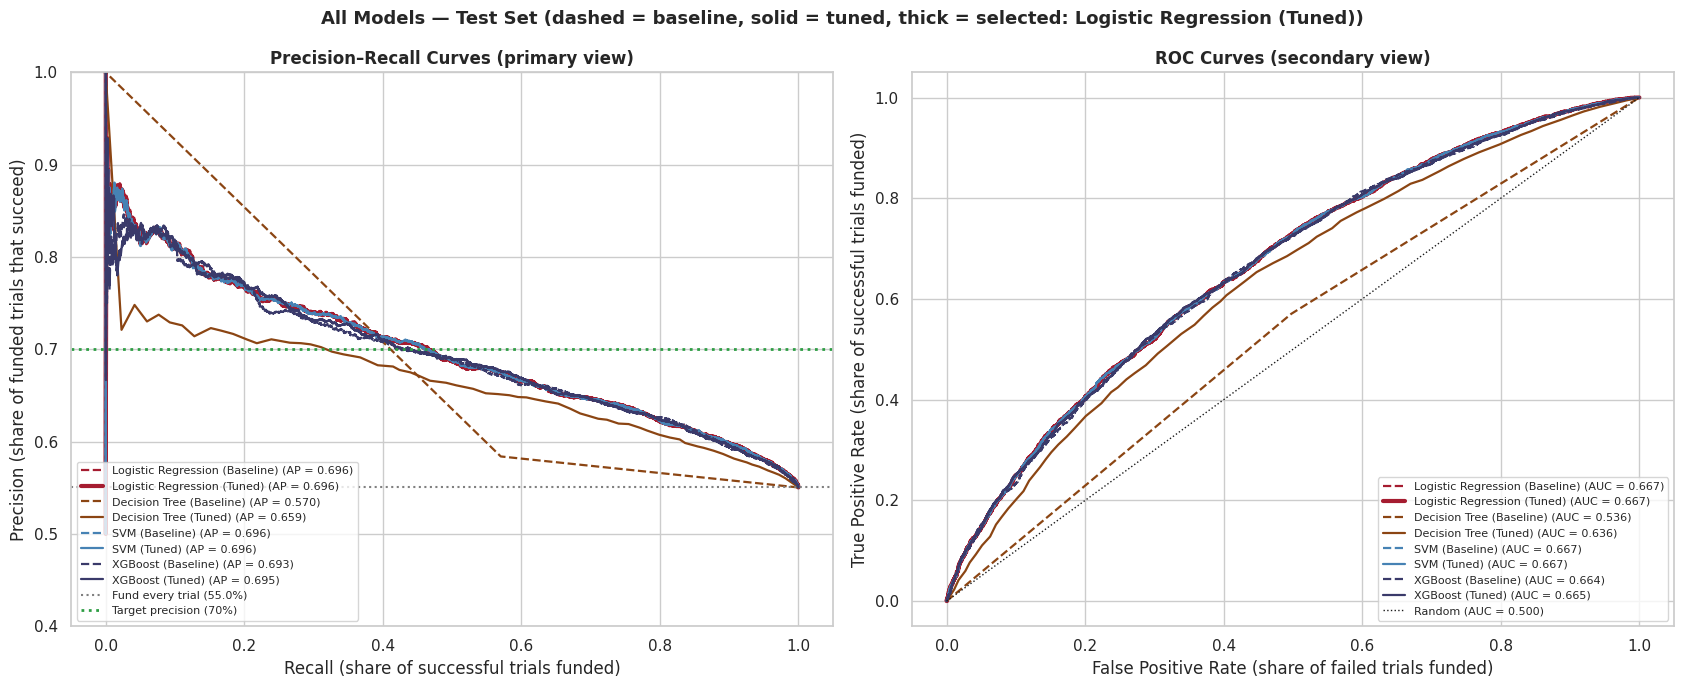

In [131]:
# =============================================================================
# PRECISION–RECALL AND ROC OVERLAYS — ALL MODELS (test set)
# =============================================================================
palette = {"Logistic Regression": "#A51C30", "Decision Tree": "#8B4513",
           "SVM": "steelblue", "XGBoost": "#3A3A6A"}

fig, (ax_pr, ax_roc) = plt.subplots(1, 2, figsize=(17, 7))
for name, (model, _, Xte, _) in model_registry.items():
    if name not in cv_df.index:
        continue
    s = positive_scores(model, Xte)
    color = next(c for fam, c in palette.items() if name.startswith(fam))
    style = dict(color=color, ls="--" if "Baseline" in name else "-",
                 lw=3 if name == best_name else 1.6)
    prec, rec, _ = precision_recall_curve(y_test, s)
    ax_pr.plot(rec, prec, label=f"{name} (AP = {average_precision_score(y_test, s):.3f})", **style)
    fpr, tpr, _ = roc_curve(y_test, s)
    ax_roc.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, s):.3f})", **style)

ax_pr.axhline(y_test.mean(), color="gray", ls=":", label=f"Fund every trial ({y_test.mean():.1%})")
ax_pr.axhline(TARGET_PRECISION, color=SUCCESS_COLOR, ls=":", lw=2,
              label=f"Target precision ({TARGET_PRECISION:.0%})")
ax_pr.set(xlabel="Recall (share of successful trials funded)",
          ylabel="Precision (share of funded trials that succeed)", ylim=(0.4, 1.0),
          title="Precision–Recall Curves (primary view)")
ax_roc.plot([0, 1], [0, 1], "k:", lw=1, label="Random (AUC = 0.500)")
ax_roc.set(xlabel="False Positive Rate (share of failed trials funded)",
           ylabel="True Positive Rate (share of successful trials funded)",
           title="ROC Curves (secondary view)")
for ax in (ax_pr, ax_roc):
    ax.legend(fontsize=8, loc="lower left" if ax is ax_pr else "lower right")
    ax.title.set_fontweight("bold")
plt.suptitle(f"All Models — Test Set (dashed = baseline, solid = tuned, thick = selected: {best_name})",
             fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

### How to read the precision–recall plot:

- Moving left along a curve means funding fewer trials. Precision should rise as only the most promising trials are kept.
- A curve that sits **higher** delivers more successes per funded trial at the same funding level.
- The gray line is what a sponsor gets by funding everything (55%).
- Where a curve crosses the green line shows how much of the successful pipeline (recall) must be given up to reach 70% precision.

✓ 70% precision is reachable with recall ≥ 20% (CV estimate)
Chosen threshold for Logistic Regression (Tuned): 0.603

Test-set funding consequences — Logistic Regression (Tuned)  (fund-everything precision = 55.0%)


,Precision (funded trials that succeed),Trials funded,% of trials funded,Failed trials funded (FP),Successes funded (TP),Successes not funded (FN),Recall,Specificity
Threshold,,,,,,,,
0.400000,59.8%,"6,961",82.9%,"2,797","4,164",459,90.1%,25.9%
0.500000,63.9%,"5,372",64.0%,"1,938","3,434","1,189",74.3%,48.7%
0.600000,68.7%,"3,371",40.1%,"1,056","2,315","2,308",50.1%,72.0%
0.603000,68.9%,"3,306",39.4%,"1,027","2,279","2,344",49.3%,72.8%
0.650000,72.2%,"2,384",28.4%,662,"1,722","2,901",37.2%,82.5%
0.700000,75.4%,"1,493",17.8%,367,"1,126","3,497",24.4%,90.3%


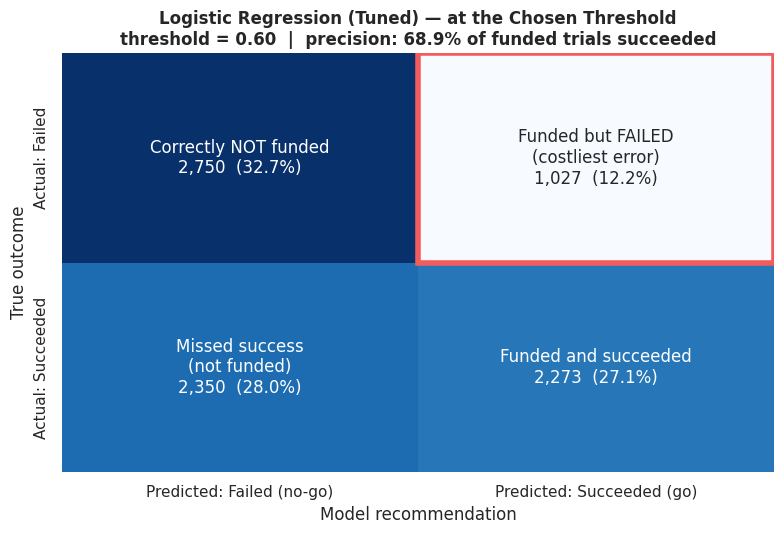

Classification Report:
              precision    recall  f1-score   support

      Failed       0.54      0.73      0.62      3777
   Succeeded       0.69      0.49      0.57      4623

    accuracy                           0.60      8400
   macro avg       0.61      0.61      0.60      8400
weighted avg       0.62      0.60      0.59      8400



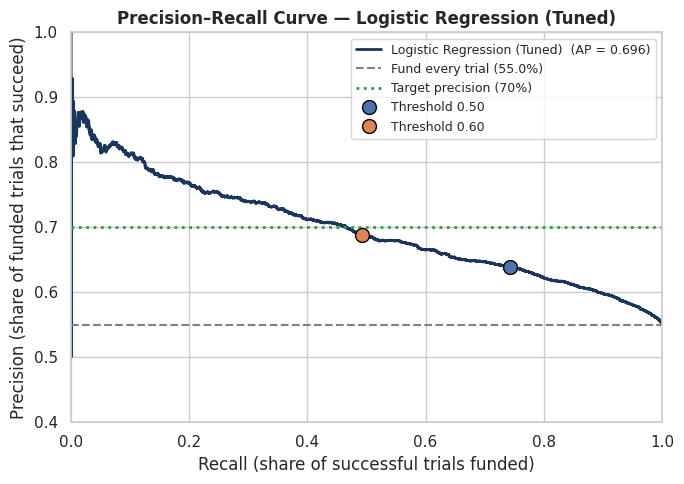

In [132]:
# =============================================================================
# SELECTED MODEL — CHOOSE THE DECISION THRESHOLD FOR THE TARGET PRECISION
# =============================================================================
# The threshold is chosen on OUT-OF-FOLD training predictions (5-fold CV) and
# then checked once on the test set, so the test result is an honest estimate.
# Conditional logic: if the target precision cannot be reached while keeping
# recall ≥ MIN_RECALL, the most precise acceptable threshold is used and a
# warning explains why.
# =============================================================================
import inspect

# Guard: an older make_confusion_matrix (no `threshold`) may have overwritten the good one.
if "threshold" not in inspect.signature(make_confusion_matrix).parameters:
    raise RuntimeError(
        "make_confusion_matrix() has no 'threshold' argument — a stale duplicate definition is "
        "overriding it. Delete the 'confusion-matrix helper' function in the 'SETUP: FEATURES, "
        "TARGET, SPLIT' cell, then Restart & Run all.")

m, n_jobs = _fresh_copy(best_name, best_model)
oof = cross_val_predict(m, best_X_train, y_train, cv=cv, method="predict_proba", n_jobs=n_jobs)[:, 1]


def choose_precision_threshold(y_true, scores, target=TARGET_PRECISION, min_recall=MIN_RECALL):
    """Lowest threshold (= most trials funded) that reaches the target precision with recall ≥ min."""
    prec, rec, thr = precision_recall_curve(y_true, scores)
    prec, rec = prec[:-1], rec[:-1]                          # align with thresholds
    ok = np.where((prec >= target) & (rec >= min_recall))[0]
    if ok.size:
        i = ok[np.argmax(rec[ok])]
        print(f"✓ {target:.0%} precision is reachable with recall ≥ {min_recall:.0%} (CV estimate)")
    else:
        allowed = np.where(rec >= min_recall)[0]
        if allowed.size == 0:                                # no threshold keeps enough recall
            raise ValueError(f"No threshold keeps recall ≥ {min_recall:.0%}. Lower MIN_RECALL.")
        i = allowed[np.argmax(prec[allowed])]
        print(f"⚠ {target:.0%} precision is not reachable with recall ≥ {min_recall:.0%}; "
              f"using the most precise acceptable threshold ({prec[i]:.1%} CV precision). "
              "Consider lowering TARGET_PRECISION or MIN_RECALL.")
    return float(thr[i])


def threshold_table(y_true, scores, thresholds):
    """Funding consequences of each candidate threshold."""
    y_true, rows = np.asarray(y_true), []
    for t in thresholds:
        go = scores >= t
        tp, fp = int((go & (y_true == 1)).sum()), int((go & (y_true == 0)).sum())
        fn, tn = int((~go & (y_true == 1)).sum()), int((~go & (y_true == 0)).sum())
        rows.append({"Threshold": round(t, 3),
                     "Precision (funded trials that succeed)": tp / (tp + fp) if tp + fp else np.nan,
                     "Trials funded": tp + fp, "% of trials funded": (tp + fp) / len(y_true),
                     "Failed trials funded (FP)": fp, "Successes funded (TP)": tp,
                     "Successes not funded (FN)": fn,
                     "Recall": tp / (tp + fn) if tp + fn else np.nan,
                     "Specificity": tn / (tn + fp) if tn + fp else np.nan})
    return pd.DataFrame(rows).set_index("Threshold")


chosen_thr = choose_precision_threshold(y_train, oof)
print(f"Chosen threshold for {best_name}: {chosen_thr:.3f}\n")

s_test = positive_scores(best_model, best_X_test)
tbl = threshold_table(y_test, s_test, sorted({0.40, 0.50, 0.60, 0.65, 0.70, round(chosen_thr, 3)}))
print(f"Test-set funding consequences — {best_name}  (fund-everything precision = {y_test.mean():.1%})")
display(tbl.style
        .format("{:.1%}", subset=["Precision (funded trials that succeed)", "% of trials funded",
                                  "Recall", "Specificity"])
        .format("{:,.0f}", subset=["Trials funded", "Failed trials funded (FP)",
                                   "Successes funded (TP)", "Successes not funded (FN)"])
        .apply(lambda r: ["background-color:#FFF3B0" if r.name == round(chosen_thr, 3) else ""
                          for _ in r], axis=1))

make_confusion_matrix(best_model, best_X_test, y_test, threshold=chosen_thr,
                      title=f"{best_name} — at the Chosen Threshold")
plot_pr_curve(best_model, best_X_test, y_test, model_name=best_name,
              mark_thresholds=(0.5, chosen_thr));

### Choosing the funding threshold
*Decision from Synthetic dataset, seed 973.*

| | Default threshold (0.50) | Chosen threshold (0.603) |
|---|---|---|
| Precision (funded trials that succeed) | 63.9% | **68.9%** |
| Trials funded | 5,372 (64.0%) | 3,306 (39.4%) |
| Failed trials funded | 1,938 | **1,027** |
| Successful trials not funded | 1,189 | 2,344 |
| Recall / Specificity | 74.3% / 48.7% | 49.3% / 72.8% |

- **Raising the threshold makes "go" decisions more reliable.** Failed trials funded fall from 1,938 to 1,027 (**47% fewer**), and from 3,777 if every trial were funded (73% fewer). That is a direct reduction in wasted Phase 3 investment.
- **The cost is a smaller, more selective portfolio.** To avoid 911 failed trials, the model gives up 1,155 additional successes: about 1.3 successes per failure avoided. In total, 2,344 successful trials (51%) are not funded. These are candidates for redesign (endpoint, biomarker selection, power), more Phase 2 work, or partnering. They are not necessarily abandoned.
- **The 70% target was met in cross-validation but not exactly on the test set** (68.9%). The test precision is about 1.1 points below target. That is about 1.4 standard errors (SE ≈ 0.8 points for 3,306 funded trials), so it is consistent with sampling noise. A sponsor who needs a firm 70% could set `TARGET_PRECISION` to about 0.72 to build in a margin. The threshold should still be chosen on out-of-fold training data, never on the test set.
- **Other thresholds on the test set:** 0.65 gives 72.2% precision while funding 28.4% of trials. 0.70 gives 75.4% while funding 17.8%, with recall of 24.4%, close to the 20% minimum.
- **The right threshold is a business decision**, set by the relative cost of a failed Phase 3 versus a missed success and by the available budget. `TARGET_PRECISION`, `MIN_RECALL` and `FUNDING_RATE` let a sponsor explore alternatives without changing any code.

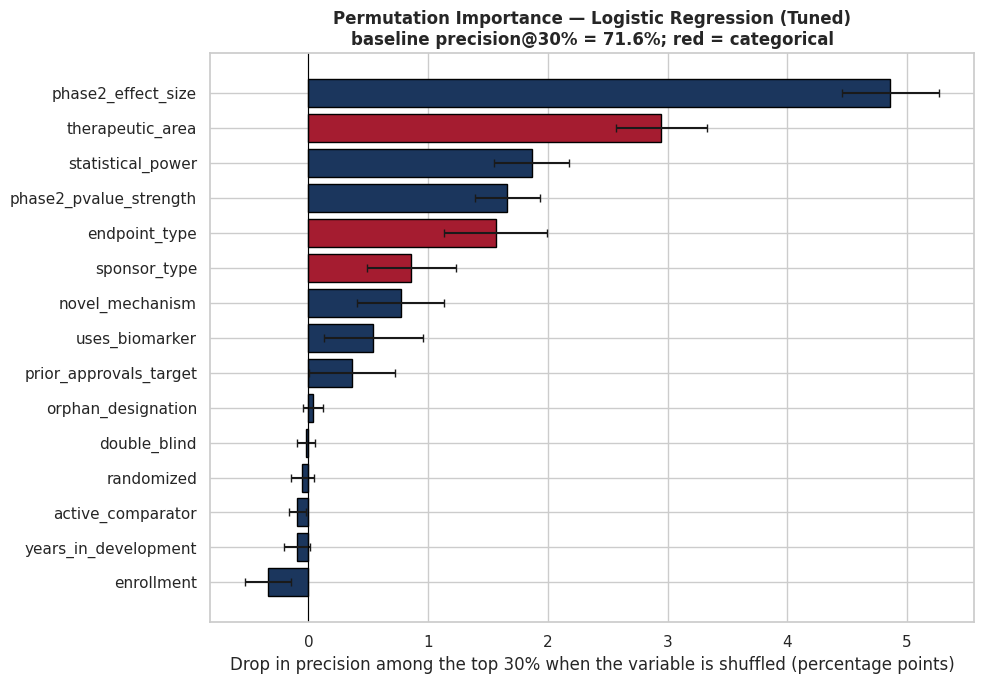

,Mean drop (pts),SD (pts)
phase2_effect_size,4.86,0.41
therapeutic_area,2.95,0.38
statistical_power,1.87,0.31
phase2_pvalue_strength,1.66,0.27
endpoint_type,1.56,0.43
sponsor_type,0.86,0.37
novel_mechanism,0.77,0.36
uses_biomarker,0.54,0.41
prior_approvals_target,0.37,0.36
orphan_designation,0.04,0.08


In [133]:
# =============================================================================
# SELECTED MODEL — PERMUTATION IMPORTANCE (model-agnostic, in precision terms)
# =============================================================================
# Each ORIGINAL variable is shuffled on the test set (breaking its link to the
# outcome) and the drop in precision@top-30% is recorded. Shuffling raw columns
# means each categorical variable is assessed as a whole, and the method works
# for any model type (unlike tree-only impurity importance).
# =============================================================================
N_REPEATS = 10
rng = np.random.default_rng(RANDOM_STATE)

if "encode_for_lr" not in globals():          # defined in the model-surface cell; fallback here
    def encode_for_lr(X_raw):
        dummies = pd.DataFrame(ohe.transform(X_raw[nominal_cols]), columns=ohe_cols, index=X_raw.index)
        return pd.concat([X_raw.drop(columns=nominal_cols), dummies], axis=1)[lr_feature_cols]

to_model_input = encode_for_lr if best_X_test is X_test_lr else (lambda d: d)
baseline_prec = precision_at_k(y_test, positive_scores(best_model, to_model_input(X_test)))

drops = {}
for col in X_test.columns:
    vals = []
    for _ in range(N_REPEATS):
        X_perm = X_test.copy()
        X_perm[col] = rng.permutation(X_perm[col].to_numpy())
        vals.append(baseline_prec - precision_at_k(y_test, positive_scores(best_model, to_model_input(X_perm))))
    drops[col] = (np.mean(vals) * 100, np.std(vals) * 100)

perm_df = pd.DataFrame(drops, index=["Mean drop (pts)", "SD (pts)"]).T.sort_values("Mean drop (pts)")

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(perm_df.index, perm_df["Mean drop (pts)"], xerr=perm_df["SD (pts)"], capsize=3,
        color=["#A51C30" if c in categorical_cols else MAIN_COLOR for c in perm_df.index],
        edgecolor="black")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel(f"Drop in precision among the top {FUNDING_RATE:.0%} when the variable is shuffled "
              "(percentage points)")
ax.set_title(f"Permutation Importance — {best_name}\n"
             f"baseline precision@{FUNDING_RATE:.0%} = {baseline_prec:.1%}; red = categorical",
             fontweight="bold")
plt.tight_layout(); plt.show()
display(perm_df.sort_values("Mean drop (pts)", ascending=False).round(2))

### Permutation importance
*Interpretation of Synthetic dataset, seed 973.*

Each variable is shuffled on the test set, and the drop in precision among the top 30% is recorded. The baseline is 71.6%.

| Variable | Drop in precision@30% (points) |
|---|---|
| phase2_effect_size | 4.86 ± 0.41 |
| therapeutic_area | 2.95 ± 0.38 |
| statistical_power | 1.87 ± 0.31 |
| phase2_pvalue_strength | 1.66 ± 0.27 |
| endpoint_type | 1.56 ± 0.43 |
| sponsor_type | 0.86 ± 0.37 |
| novel_mechanism | 0.77 ± 0.36 |
| uses_biomarker | 0.54 ± 0.41 |
| prior_approvals_target | 0.37 ± 0.36 |
| orphan_designation, double_blind, randomized, active_comparator, years_in_development | −0.10 to +0.04 (indistinguishable from zero) |
| enrollment | −0.34 ± 0.19 |

- **Phase 2 effect size matters most.** Shuffling it costs about 4.9 points, from 71.6% to about 66.8%. Therapeutic area costs about 3.0 points, power 1.9, p-value strength 1.7 and endpoint 1.6.
- **Variables with no ranking value:** five variables show drops within one SD of zero. `years_in_development` is among them, as planted. `enrollment` is slightly negative (−0.34 ± 0.19), meaning shuffling it marginally *improves* precision. It adds a little noise to the ranking, consistent with its negligible true effect.
- **Importance is not the same as odds-ratio size.** `uses_biomarker` has an OR of 1.35 but a small drop (0.54 points). A single yes/no variable moves few trials in or out of the top 30%, whereas continuous variables with a wide range reshuffle the ranking more. `prior_approvals_target` (OR 1.11 per SD) is similarly small.
- **Agreement:** the ranking matches the odds ratios, the tree's importance and the inferential tests at the top (Phase 2 effect size, therapeutic area, power, p-value strength, endpoint).

In [134]:
# =============================================================================
# SCENARIO TOOL — PREDICTED P(SUCCESS) FOR A PLANNED TRIAL + WHAT-IF CHANGES
# =============================================================================
# Uses the baseline logistic regression (interpretable, additive). Self-contained:
# defines its own encoder and reference distribution, so it does not depend on cells
# that may have been removed or run in a different order.
# NOTE: results come from SYNTHETIC data and do not apply to any real trial.
# =============================================================================
def encode_for_lr(X_raw):
    """One-hot encode the 3 nominal columns exactly as in the LR feature-engineering cell."""
    dummies = pd.DataFrame(ohe.transform(X_raw[nominal_cols]), columns=ohe_cols, index=X_raw.index)
    return pd.concat([X_raw.drop(columns=nominal_cols), dummies], axis=1)[lr_feature_cols]


# Reference distribution: predicted P(success) for every held-out test trial (for percentiles)
p_lr = lr_pipeline.predict_proba(X_test_lr)[:, 1]


def validate_profile(profile):
    """Fail early, with a clear message, on missing fields, unknown levels or out-of-range values."""
    missing = [c for c in X.columns if c not in profile]
    if missing:
        raise KeyError(f"Trial profile is missing: {missing}")
    for col, levels in zip(nominal_cols, level_order):
        if profile[col] not in levels:
            raise ValueError(f"{col}='{profile[col]}' is not one of {levels}")
    for col in binary_cols:
        if profile[col] not in (0, 1):
            raise ValueError(f"{col} must be 0 or 1 (got {profile[col]})")
    for col, (lo, hi) in range_checks.items():                  # effect size, p-value strength, power
        if not lo <= profile[col] <= hi:
            raise ValueError(f"{col}={profile[col]} is outside [{lo}, {hi}]")
    for col in ["enrollment", "prior_approvals_target", "years_in_development"]:
        if profile[col] < 0:
            raise ValueError(f"{col} cannot be negative (got {profile[col]})")


def score_trial(profile, model=lr_pipeline, reference=p_lr):
    """Return predicted P(success) and its percentile among test-set trials.
    `reference` must be the test-set scores of the SAME model."""
    validate_profile(profile)
    row = pd.DataFrame([profile])[X.columns]
    p = model.predict_proba(encode_for_lr(row))[:, 1][0]
    return p, (reference < p).mean() * 100


planned_trial = dict(
    therapeutic_area="oncology", endpoint_type="hard_survival", sponsor_type="small_biotech",
    phase2_effect_size=4.5, phase2_pvalue_strength=6.5, enrollment=500,
    statistical_power=0.80,
    prior_approvals_target=0,        # first-in-class (novel_mechanism=1) → no prior approvals on the target
    years_in_development=7,
    uses_biomarker=0, novel_mechanism=1, randomized=1, double_blind=1,
    active_comparator=0, orphan_designation=0,
)

what_ifs = {
    "As planned":                        {},
    "Add biomarker-guided selection":    {"uses_biomarker": 1},
    "Use a clinical endpoint":           {"endpoint_type": "clinical"},
    "Increase power to 0.90":            {"statistical_power": 0.90},
    "All three design changes":          {"uses_biomarker": 1, "endpoint_type": "clinical",
                                          "statistical_power": 0.90},
}

base_p, _ = score_trial(planned_trial)
rows = []
for label, change in what_ifs.items():
    p, pct = score_trial({**planned_trial, **change})
    rows.append({"Scenario": label, "Predicted P(success)": p,
                 "Change vs. plan (pts)": (p - base_p) * 100,
                 "Percentile among test trials": pct})
display(pd.DataFrame(rows).set_index("Scenario")
          .style.format({"Predicted P(success)": "{:.1%}", "Change vs. plan (pts)": "{:+.1f}",
                         "Percentile among test trials": "{:.0f}"}))
print(f"Reference: overall success rate in this synthetic dataset = {y.mean():.1%}")
print("Caution: these are associations learned from SYNTHETIC data. A design change is only "
      "worthwhile if it is scientifically and regulatorily appropriate (e.g., an accepted endpoint).")

,Predicted P(success),Change vs. plan (pts),Percentile among test trials
Scenario,,,
As planned,25.9%,+0.0,3
Add biomarker-guided selection,32.2%,+6.2,7
Use a clinical endpoint,33.0%,+7.1,8
Increase power to 0.90,29.9%,+4.0,5
All three design changes,44.9%,+18.9,26


Reference: overall success rate in this synthetic dataset = 55.0%
Caution: these are associations learned from SYNTHETIC data. A design change is only worthwhile if it is scientifically and regulatorily appropriate (e.g., an accepted endpoint).


### How to Interpret the Scenario Tool Table: Example
*Interpretation of Synthetic dataset, seed 973.*

| Scenario | Predicted P(success) | Change vs. plan | Percentile among test trials |
|---|---|---|---|
| As planned | 25.9% | — | 3rd |
| Add biomarker-guided selection | 32.2% | +6.2 pts | 7th |
| Use a clinical endpoint | 33.0% | +7.1 pts | 8th |
| Increase power to 0.90 | 29.9% | +4.0 pts | 5th |
| All three design changes | 44.9% | +18.9 pts | 26th |

- **The planned trial is high-risk.** An oncology trial with a hard-survival endpoint, a small-biotech sponsor and a novel mechanism has a predicted P(success) of **25.9%**, against 55.0% overall. Only about 3% of test trials score lower.
- **Each change helps.** Biomarker-guided selection adds 6.2 points, a clinical endpoint adds 7.1, and higher power adds 4.0.
- **The changes combine.** All three together add 18.9 points, slightly more than the 17.3 from adding the three separately. The effects add on the log-odds scale (+0.30, +0.34, +0.20 = +0.84), which is curved on the probability scale.
- **Even all three changes leave the trial below average.** At 44.9% it is still below the 55.0% overall rate, because oncology, small-biotech sponsorship and novel mechanism all lower the odds and cannot be redesigned away.
- **Caution:** these are associations learned from synthetic data. A design change is only worthwhile if it is scientifically and regulatorily appropriate. Nothing here applies to a real trial.

## Notebook Overall Key Findings
*Conclusions from Synthetic dataset, seed 973.*

| Model (tuned) | CV precision@30% | Test precision@30% | Test precision (0.5) | Failed trials funded (0.5) |
|---|---|---|---|---|
| Logistic Regression | 0.725 | 0.716 | 0.639 | 1,938 |
| Decision Tree | 0.687 | 0.688 | 0.624 | 2,018 |
| SVM | 0.725 | 0.715 | 0.639 | 1,946 |
| XGBoost | 0.723 | 0.715 | 0.634 | 1,994 |
| *Fund every trial* | 0.550 | 0.550 | 0.550 | 3,777 |

1. **Logistic Regression (tuned) was chosen by the predefined rule.** It was within the tie tolerance of the best score (0.725) and is the simplest model in the tied group.
2. **Flexible models did not improve precision.** The SVM (linear kernel won, RBF no better) and XGBoost matched, but did not beat, logistic regression. Effects are additive and interactions add little, which is expected because the generator is an additive logistic model.
3. **The decision tree overfits without constraints** (train precision 1.000 vs. 0.584 on test). When tuned, it still ranks trials more coarsely (0.688). Its value is in readable trial profiles.
4. **Every method identifies the same drivers:** Phase 2 effect size, therapeutic area, statistical power, p-value strength, and endpoint type, with sponsor, novel mechanism and biomarker use as smaller contributors. These were planted, so this is a recovery test.
5. The best model has a test AUC of 0.667.

## Recommendations for sponsors (using this workflow)
1. **Use the selected model at the precision-based threshold (0.603)** to flag programs as "fund" or "review further". Trials above the threshold succeeded 68.9% of the time, against 55.0% overall.
2. **Treat the probability as a risk adjustment, not a verdict.** Combine it with scientific, safety, regulatory and commercial review.
3. **Send "review further" programs to redesign, not automatic cancellation.** About half of eventual successes (51%) fall below the threshold. Check the controllable levers (endpoint choice within regulatory acceptability, biomarker-guided enrollment, adequate power) and re-score the revised design with the scenario tool.
4. **Re-set the threshold when the budget changes.** A tighter budget means a higher threshold and higher precision with fewer trials funded (e.g., 72.2% precision at 28.4% funded; 75.4% at 17.8%).
5. **For an ongoing trial**, use the model's estimate as a starting point and update it with interim analyses and committee recommendations.
6. **Before any real use, validate on your own real portfolio.** These results come from synthetic data and cannot be transferred.

## Considerations and Limitations

### 1. Every quoted value belongs to the synthetic dataset
All interpretations in this notebook that quote specific values come from the dataset created by `synthetic_dataset_generator.ipynb` (seed 973, 42,000 trials). This covers success rates, odds ratios, effect sizes, p-values, model scores, thresholds, and counts of trials funded. They describe **that one file**.
**If you re-generate the data with another seed or settings, or upload your own dataset, results may vary.** Re-read each interpretation against your own output. Some conclusions, such as which model wins, may change.

| Stays the same with any dataset | Changes with the dataset |
|---|---|
| Methods, formulas, code logic, how to read each plot and metric | Every number, ranking, and "which is largest" statement |
| The warnings below | The selected model, the chosen threshold, and the achievable precision |

### 2. Synthetic data cannot be used to predict real outcomes
Associations here were put in by the generator. They were not observed in real trials.

### 3. Associations are not causes
Changing an endpoint or adding a biomarker will not by itself raise a real trial's chance of success. Regulators must also accept the endpoint.

### 4. What the model does not know
No interim efficacy or safety data, mechanism-specific biology, competitive landscape, or cost.

### 5. Statistical cautions
- With n ≈ 42,000, tiny differences have tiny p-values, so judge **effect sizes**.
- Nine chi-square tests use a Bonferroni threshold of 0.05/9 = 0.0056.
- The test set is used once. Cross-validated scores for tuned models are slightly optimistic.
- A single train/test split gives one estimate, not a confidence interval.

### 6. Using your own dataset
1. Match the column names, levels, and units in the data dictionary. Validation will flag differences.
2. Re-set `TARGET_PRECISION`, `FUNDING_RATE`, and `MIN_RECALL`. They are tuned to this file.
3. Run all cells, then review the results and update interpretations.
4. Real data may be messier. The cleaning and imputation branches will then be exercised, which they are not here.

#####**AI-Usage Statement:**
An AI assistant (Claude Opus 5.5, Claude Sonnet 5.5) was utilized to support:

- **Code generation:** Modifications to code from the original notebooks authored by Dartmouth faculty member **Dr. Jamie Fairclough**.
- **Documentation:** Drafting Markdown descriptions, explanations of statistical methods, and machine learning components.
- **Interpretation:** Helping explain the outputs and performance metrics generated by my notebook.

I executed all code in Google Colab, verified that the notebook ran from start to finish without errors, and confirmed that the reported results came from my own run. I reviewed, edited, and take full responsibility for all code, explanations, and interpretations in this submission.
